## 최종 보고서 읽기 안내

- **Part I(1~8절)은 중간 보고서를 그대로 둔 기록이다.** 당시에는 선형 SFR의 RMSE를 기준으로 썼다. 이후 1차 평가 지표가 로그 SFR 공간의 RMSE로 확인되어(조교 FAQ Q6), Part II는 그 기준으로 다시 비교했다. 무엇이 왜 바뀌었는지는 9.1절에 정리했다.
- **최종 모델:** 로그 공간의 두 단계 모델. HGB 분류기가 P(SFR > 0)를, SFR > 0 은하로만 학습한 HGB 회귀기가 log10(SFR + 1)을 예측해 합치고, 0일 확률이 0.9 이상이면 SFR = 0을 낸다. 입력은 46개다. 원래 13개, 위치·속도로 만든 환경 요약 17개, 질량 성장·비율 4개, 그리고 팀원의 피처 탐색에서 고른 이웃 은하·병합×성장·질량 대비 잔차 12개다.
- **검증 결과:** log10(SFR + 1)의 RMSE **0.0941 dex**(HGB 기준선 0.1538), 선형 RMSE 7.76(기준선 9.51).
- **핵심 발견:** 별 생성이 꺼졌는지는 주변 환경이, 켜져 있다면 얼마나 만드는지는 질량과 성장 이력이 정한다(12절).

# DataHub — Galaxy Star Formation Rate Prediction
## Midterm + Final Scientific Report Template

This notebook is both your **analysis code** and your **scientific report**. Use the **same notebook for both submission stages**.

- **Part I — Midterm Report:** complete all required Part I sections and submit the notebook.
- **Part II — Final Report:** continue in the same notebook, preserve Part I, and complete the final analysis, code, results, and discussion.

## Participant Information

**Application ID:** 701104

**email:** james092@snu.ac.kr

---
# Part I — Midterm Report

**Goal:** establish a scientifically motivated modeling plan. Part I should demonstrate that you understand the prediction problem, have inspected the data carefully, established a defensible validation procedure, and produced preliminary results.

### Part I deliverables
1. Problem & objective
2. Data loading and quality checks
3. Exploratory data analysis
4. Data preparation and feature engineering
5. Validation and evaluation strategy
6. Baseline results
7. Preliminary model / proposed method
8. Midterm summary and next-step plan

## 1. Problem & Objective — **STUDENT RESPONSE**

In approximately **150–250 words**, explain:
- what quantity you are predicting;
- what information is available as input;
- why this is a non-trivial regression problem;
- one or more astrophysical considerations that may affect the prediction.

**Response:**

이 과제는 우주론 시뮬레이션(Crocodile)의 은하 208,437개 각각에 대해 별 생성률 `sfr_linear`(로그가 아닌 원래 척도)를 예측하는 회귀 문제다. 입력은 13개 피처다. 암흑물질 헤일로, 항성, 중심 블랙홀의 질량, 주 전구체(main progenitor)의 헤일로·항성 질량, 최근 병합의 질량비, 주변 밀도(모두 log10)와 3차원 위치·속도다. `subhalo_id`는 식별자라 쓰지 않는다. 공식 지표가 선형 RMSE이므로 맞혀야 할 양은 같은 피처를 가진 은하들의 평균 SFR, 즉 E[SFR | 피처]다.

쉬운 회귀가 아닌 이유는 타깃 분포에 있다. 은하의 8.66%는 SFR이 정확히 0인 꺼진 은하이고, 반대쪽 꼬리는 매우 길다(중앙값 1.63, 최댓값 2,145). RMSE는 오차를 제곱하므로 극소수의 극단 SFR 은하가 점수를 지배한다. 또 꺼진 은하와 별을 만드는 은하는 서로 다른 과정에서 나온 것으로 보여, 하나의 단순한 함수로 함께 맞히기 어렵다.

천체물리적으로는 세 요인이 예측에 영향을 줄 수 있다. 가장 중요한 것은 **주변 환경**이다. 밀집된 환경의 은하는 가스를 빼앗기거나 공급이 끊겨 별 생성이 꺼질 수 있고, 학습 데이터에서도 주변 밀도가 높을수록 SFR = 0 비율이 0.9%에서 94%까지 올라갔다. 둘째, 큰 **중심 블랙홀**이 내는 에너지(AGN 피드백)는 가스를 데우거나 날려 별 생성을 낮출 수 있다. 셋째, 은하 **병합**은 가스를 중심으로 몰아 폭발적인 별 생성을 일으킬 수 있으며, 학습 데이터에서 SFR > 100인 은하의 89.5%가 병합 후보였다. 이 요인들이 이후 EDA와 모델 설계의 출발점이다.

## 2. Setup, Reproducibility & Data Loading

The fixed cells below establish common imports, a random seed, and basic schema checks. You may change the data path if necessary, but do not silently alter the raw data.

In [1]:
# DO NOT MODIFY — core imports and seed
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

warnings.filterwarnings("ignore")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
pd.set_option("display.max_columns", 100)
print("Random seed:", RANDOM_SEED)

Random seed: 42


In [2]:
# You may change DATA_PATH only if needed.
CANDIDATES = [
    Path("Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
    Path("/mnt/data/Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset not found. Place the course CSV beside this notebook or update DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Shape: (208437, 15)


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
0,0.0,14.807566,12.812004,10.443699,14.631294,12.589542,-3.239739,2.383863,21.290455,101.703239,118.123352,-287.557892,-62.394615,-30.580877,107.896912
1,1.0,13.870680,12.091579,8.625058,13.819390,11.916792,-6.000000,2.025288,20.735514,101.805397,120.937294,786.127563,258.246796,-680.667908,68.733315
2,2.0,13.672584,12.032370,9.829654,13.620131,11.864630,-6.000000,1.704644,18.711687,103.225121,120.417160,890.943054,-756.617004,-358.727631,0.232002
3,3.0,13.650022,12.019966,9.312719,13.577394,11.849984,-6.000000,1.833376,23.493862,102.198166,113.814438,-92.127396,532.597473,544.153687,12.698732
4,4.0,13.131606,11.563723,9.452775,13.026983,11.395634,-6.000000,1.830341,24.067015,101.780312,112.495789,-187.708572,-224.876968,978.109558,0.715540


In [3]:
# DO NOT MODIFY — schema checks
TARGET = "sfr_linear"
ID_COLUMN = "subhalo_id"
EXPECTED_COLUMNS = [
    "subhalo_id", "log10_halo_mass", "log10_stellar_mass", "log10_BH_mass",
    "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio",
    "log10_overdensity_plus_1", "pos_x", "pos_y", "pos_z",
    "vel_x", "vel_y", "vel_z", "sfr_linear"
]
missing = sorted(set(EXPECTED_COLUMNS) - set(df.columns))
if missing:
    raise ValueError(f"Missing expected columns: {missing}")
n_missing_target = int(df[TARGET].isna().sum())
print(f"Missing target values: {n_missing_target}")
if n_missing_target > 0:
    print(f"Dropping {n_missing_target} row(s) with missing target before modeling.")
    df = df.dropna(subset=[TARGET]).copy()
print(f"Schema check passed. Samples available for modeling: {len(df):,}")


Missing target values: 0
Schema check passed. Samples available for modeling: 208,437


### 2.1 Data Quality Notes — **STUDENT RESPONSE**

Report the dataset size, missing values, duplicate handling (if any), and any other data-quality issue you found. Remember that **`sfr_linear = 0` is a valid physical target and is not the same as a missing value**.

**Response:**
모든 점검은 **전체 데이터**(208,437개) 기준이며, 행이나 값은 하나도 삭제·변경하지 않았다.

| 항목 | 결과 |
|---|---|
| 크기 | 208,437행 × 15열 (입력 피처 13개 + `subhalo_id` + 타깃 `sfr_linear`), 모든 열 `float64` |
| 결측값 | NaN 0개, +inf·−inf 0개 |
| 중복 | 전체 열 기준 중복 행 0, `subhalo_id` 중복 0 → 중복 처리 불필요 |
| 상수 열 | 없음 (고유값이 가장 적은 `log10_mass_ratio`도 32,659개) |
| 타깃 | `sfr_linear` = 0이 18,048개(8.66%). 결측이 아니라 별 생성이 멈춘 은하이므로 그대로 둔다. 음수 없음. 중앙값 1.63, 최댓값 2,145로 오른쪽 꼬리가 매우 길다(3절 EDA 3) |

**특수 값(센티널 후보)** — 한 값에 크게 몰려 있어 "없음/초기값"을 뜻하는 코드로 보이지만, **공식 정의는 확인하지 못했다.**
- `log10_BH_mass` ≤ 5.01: 121,546개(58.3%). 정확히 5.0인 행은 없고 5.0000~5.0001 근처에 몰려 있다(블랙홀 seed 질량 추정). 5.30 근처에도 두 번째 봉우리(15.6%)가 있다.
- `log10_mass_ratio` = −6: 175,778개(84.3%). 다음으로 작은 값이 −3.79여서 −6은 따로 떨어진 코드값으로 보인다(병합 없음 추정).
- `log10_main_prog_mass` = 6.0: 762개(0.37%), `log10_main_prog_stellar_mass` = 6.0: 772개. 762개는 두 열이 함께 6.0이다(전구체 없음 추정).

**주의할 행** (삭제하지 않음)
- 전구체 헤일로 질량은 정상인데 전구체 항성 질량만 6.0인 10개: 전구체 헤일로 질량(9.7~10.1)이 현재 헤일로 질량(12.5~13.3)보다 약 3 dex 작다. 전구체 연결이나 기록 문제일 수 있다(추정).
- 헤일로 질량 < 항성 질량인 517개(0.25%): 밀도가 높고(중앙값 1.35 대 0.66) SFR = 0 비율도 높다(42.9% 대 8.6%). 밀집 환경에서 헤일로가 깎인 위성 은하일 수 있어(추정) 오류보다는 물리적 정보로 보고 유지했다.


In [4]:
# 2.1 데이터 품질 점검 — 값은 세기만 하고 지우거나 바꾸지 않는다.
FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]  # 4절 FINAL_FEATURES와 같은 규칙

# 1. 크기와 변수 이름
print("행 × 열:", df.shape)
print("변수 이름:", list(df.columns))
print("입력 피처 수:", len(FEATURES))

# 2. 열별 타입과 결측치
col_info = pd.DataFrame({"dtype": df.dtypes.astype(str), "NaN": df.isna().sum()})
display(col_info)
print("NaN 총개수:", int(df.isna().sum().sum()))

# 3. 중복
print("전체 열 중복 행:", int(df.duplicated().sum()))
print("subhalo_id 중복:", int(df[ID_COLUMN].duplicated().sum()))
print("subhalo_id가 정수인가:", bool((df[ID_COLUMN] % 1 == 0).all()),
      "| 범위:", int(df[ID_COLUMN].min()), "~", int(df[ID_COLUMN].max()))


행 × 열: (208437, 15)
변수 이름: ['subhalo_id', 'log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z', 'sfr_linear']
입력 피처 수: 13


,dtype,NaN
subhalo_id,float64,0
log10_halo_mass,float64,0
log10_stellar_mass,float64,0
log10_BH_mass,float64,0
log10_main_prog_mass,float64,0
log10_main_prog_stellar_mass,float64,0
log10_mass_ratio,float64,0
log10_overdensity_plus_1,float64,0
pos_x,float64,0
pos_y,float64,0


NaN 총개수: 0


전체 열 중복 행: 0
subhalo_id 중복: 0
subhalo_id가 정수인가: True | 범위: 0 ~ 976589


In [5]:
# 4. 타깃 sfr_linear
y_all = df[TARGET]
sfr_summary = y_all.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999]).round(3)
display(sfr_summary.to_frame("sfr_linear"))
print(f"정확히 0: {int((y_all == 0).sum()):,}개 ({(y_all == 0).mean():.2%})")
print(f"음수: {int((y_all < 0).sum())}개")
print(f"0 < SFR < 0.01: {int(((y_all > 0) & (y_all < 0.01)).sum()):,}개")
print(f"SFR > 100: {int((y_all > 100).sum()):,}개")
print(f"평균 / 중앙값 = {y_all.mean() / y_all.median():.2f}")


,sfr_linear
count,208437.000
mean,3.710
std,11.795
min,0.000
10%,0.343
25%,0.916
50%,1.632
75%,3.286
90%,7.554
99%,34.859


정확히 0: 18,048개 (8.66%)
음수: 0개
0 < SFR < 0.01: 2개
SFR > 100: 270개
평균 / 중앙값 = 2.27


In [6]:
# 5. 특수 값(센티널 후보) 분포 — 같은 값이 많이 반복되는지부터 본다
for col in ["log10_BH_mass", "log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_mass_ratio"]:
    vc = df[col].round(4).value_counts().head(5)
    print(f"\n[{col}] 가장 많이 나오는 값 (소수 4자리로 반올림)")
    print((vc.to_frame("count").assign(share=(vc / len(df)).round(4))))

bh = df["log10_BH_mass"]
mp = df["log10_main_prog_mass"]
mps = df["log10_main_prog_stellar_mass"]
mr = df["log10_mass_ratio"]
special = pd.DataFrame([
    ("log10_BH_mass == 5.0 (정확히)", (bh == 5.0).sum()),
    ("log10_BH_mass <= 5.01", (bh <= 5.01).sum()),
    ("log10_BH_mass < 5.5", (bh < 5.5).sum()),
    ("log10_main_prog_mass == 6.0", (mp == 6.0).sum()),
    ("log10_main_prog_stellar_mass == 6.0", (mps == 6.0).sum()),
    ("둘 다 6.0 (같은 행)", ((mp == 6.0) & (mps == 6.0)).sum()),
    ("log10_mass_ratio == -6", (mr == -6).sum()),
    ("log10_mass_ratio > -6", (mr > -6).sum()),
], columns=["조건", "개수"])
special["비율"] = (special["개수"] / len(df)).map("{:.2%}".format)
display(special)
print("BH > 5.01인 행의 최솟값:", round(bh[bh > 5.01].min(), 4))
print("mass_ratio > -6인 행의 최솟값:", round(mr[mr > -6].min(), 4), "| 최댓값:", mr.max())
print("main_prog_mass > 6인 행의 최솟값:", round(mp[mp > 6].min(), 4))



[log10_BH_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
               count   share
log10_BH_mass               
5.0001         31078  0.1491
5.0000         27600  0.1324
5.0002         14495  0.0695
5.0003          8324  0.0399
5.3011          7108  0.0341



[log10_main_prog_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
                      count   share
log10_main_prog_mass               
6.0000                  762  0.0037
11.1724                  38  0.0002
11.1925                  37  0.0002
11.1251                  36  0.0002
11.0774                  35  0.0002

[log10_main_prog_stellar_mass] 가장 많이 나오는 값 (소수 4자리로 반올림)
                              count   share
log10_main_prog_stellar_mass               
6.0000                          772  0.0037
9.2446                           36  0.0002
9.4331                           34  0.0002
9.5617                           34  0.0002
9.4322                           34  0.0002



[log10_mass_ratio] 가장 많이 나오는 값 (소수 4자리로 반올림)
                   count   share
log10_mass_ratio                
-6.0000           175778  0.8433
-1.6965                9  0.0000
-1.3854                9  0.0000
-1.7421                9  0.0000
-1.5388                9  0.0000


,조건,개수,비율
0,log10_BH_mass == 5.0 (정확히),0,0.00%
1,log10_BH_mass <= 5.01,121546,58.31%
2,log10_BH_mass < 5.5,181335,87.00%
3,log10_main_prog_mass == 6.0,762,0.37%
4,log10_main_prog_stellar_mass == 6.0,772,0.37%
5,둘 다 6.0 (같은 행),762,0.37%
6,log10_mass_ratio == -6,175778,84.33%
7,log10_mass_ratio > -6,32659,15.67%


BH > 5.01인 행의 최솟값: 5.01
mass_ratio > -6인 행의 최솟값: -3.7883 | 최댓값: -0.000282686697
main_prog_mass > 6인 행의 최솟값: 9.3357


In [7]:
# 5-1. 주의 값 추가 확인 (위 표에서 눈에 띈 것)
print("BH 질량, 정확한 값 기준 최빈값 3개:", bh.value_counts().head(3).to_dict())
print(f"BH 5.30~5.31 구간(두 번째 봉우리): {int(bh.between(5.30, 5.31).sum()):,}개 ({bh.between(5.30, 5.31).mean():.1%})")
only_stellar6 = (mps == 6.0) & (mp != 6.0)
print(f"전구체 항성 질량만 6.0 (헤일로 질량은 정상): {int(only_stellar6.sum())}개")
display(df.loc[only_stellar6, ["log10_main_prog_mass", "log10_main_prog_stellar_mass", "log10_stellar_mass", TARGET]].round(3))
halo_lt_star = df["log10_halo_mass"] < df["log10_stellar_mass"]
print(f"헤일로 질량 < 항성 질량인 행: {int(halo_lt_star.sum())}개 ({halo_lt_star.mean():.2%})")


BH 질량, 정확한 값 기준 최빈값 3개: {5.00000048: 13999, 5.00004768: 234, 5.00006866: 233}
BH 5.30~5.31 구간(두 번째 봉우리): 32,597개 (15.6%)
전구체 항성 질량만 6.0 (헤일로 질량은 정상): 10개


,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_stellar_mass,sfr_linear
30736,10.069,6.0,11.358,3.510
43026,9.907,6.0,11.235,2.511
49465,10.055,6.0,11.435,11.262
49841,9.886,6.0,11.280,14.941
53297,9.798,6.0,11.045,11.161
55136,9.995,6.0,11.019,1.849
56888,9.926,6.0,11.186,7.168
62118,9.944,6.0,11.077,5.099
66016,9.744,6.0,10.862,5.257
71206,9.906,6.0,10.602,2.337


헤일로 질량 < 항성 질량인 행: 517개 (0.25%)


In [8]:
# 7. 비유한 값(+inf, -inf) — NaN과 따로 센다
num = df.select_dtypes("number")
nonfinite = pd.DataFrame({
    "+inf": np.isposinf(num).sum(),
    "-inf": np.isneginf(num).sum(),
    "NaN": num.isna().sum(),
})
print("숫자형 열:", num.shape[1], "/", df.shape[1])
print("비유한 값이 있는 열:", list(nonfinite.index[nonfinite.sum(axis=1) > 0]) or "없음")
print("+inf 총개수:", int(nonfinite["+inf"].sum()), "| -inf 총개수:", int(nonfinite["-inf"].sum()))


숫자형 열: 15 / 15
비유한 값이 있는 열: 없음
+inf 총개수: 0 | -inf 총개수: 0


In [9]:
# 8. 상수 열 — 15개 열 전체에서 값이 한 종류뿐인 열, 그리고 한 값이 대부분을 차지하는 열
const_check = pd.DataFrame({
    "고유값 수": df.nunique(),
    "최빈값": df.mode().iloc[0],
    "최빈값 비율": (df.apply(lambda s: s.value_counts(normalize=True).iloc[0])).round(4),
}).sort_values("최빈값 비율", ascending=False)
display(const_check)
print("상수 열(고유값 1개):", list(const_check.index[const_check["고유값 수"] == 1]) or "없음")


,고유값 수,최빈값,최빈값 비율
log10_mass_ratio,32659,-6.000000,0.8433
sfr_linear,189864,0.000000,0.0866
log10_BH_mass,72276,5.000000,0.0672
log10_main_prog_stellar_mass,207098,6.000000,0.0037
log10_main_prog_mass,206349,6.000000,0.0037
log10_overdensity_plus_1,95330,0.040029,0.0001
log10_stellar_mass,195185,9.305265,0.0000
log10_halo_mass,189212,8.000000,0.0000
subhalo_id,208437,0.000000,0.0000
pos_y,207324,78.444397,0.0000


상수 열(고유값 1개): 없음


In [10]:
# 9. 점검 대상 구분 — 위 1~8은 모두 "전체 CSV"(df) 기준의 데이터 품질 점검이다.
#    3절의 타깃 관련 EDA는 학습 데이터만 쓴다. 공통 분할은 5절(DO NOT MODIFY)에서 만들어지므로,
#    여기서 같은 인자로 분할을 재현해 학습 인덱스(_tr_idx)를 준비한다. 5절 칸은 고치지 않는다.
#    검증 데이터의 타깃 통계는 출력하지 않는다.
_y = df[TARGET]
_regime = (_y > 0).astype(int)
_tr_idx, _va_idx = train_test_split(
    df.index, test_size=0.20, random_state=RANDOM_SEED, stratify=_regime
)
print("전체:", len(df), "| 학습:", len(_tr_idx), "| 검증:", len(_va_idx))


전체: 208437 | 학습: 166749 | 검증: 41688


In [11]:
# 10. 전구체 헤일로 질량은 정상(≠ 6.0)인데 전구체 항성 질량만 6.0인 10개 은하
g10 = (df["log10_main_prog_stellar_mass"] == 6.0) & (df["log10_main_prog_mass"] != 6.0)
print("해당 은하 수:", int(g10.sum()), "| 학습:", int(g10.loc[_tr_idx].sum()), "| 검증:", int(g10.loc[_va_idx].sum()))
display(df.loc[g10].round(3))

# 비교 기준: 나머지 전체, 그리고 현재 항성 질량이 비슷한(같은 범위) 나머지 은하
lo, hi = df.loc[g10, "log10_stellar_mass"].min(), df.loc[g10, "log10_stellar_mass"].max()
similar = (~g10) & df["log10_stellar_mass"].between(lo, hi)
cols = ["log10_halo_mass", "log10_stellar_mass", "log10_BH_mass", "log10_main_prog_mass",
        "log10_mass_ratio", "log10_overdensity_plus_1", TARGET]
cmp10 = pd.DataFrame({
    "10개 (중앙값)": df.loc[g10, cols].median(),
    f"항성 질량 {lo:.2f}~{hi:.2f}인 나머지 (중앙값)": df.loc[similar, cols].median(),
    "나머지 전체 (중앙값)": df.loc[~g10, cols].median(),
}).round(3)
cmp10.loc["SFR = 0 비율(%)"] = [(df.loc[m, TARGET] == 0).mean() * 100 for m in (g10, similar, ~g10)]
cmp10.loc["최근 병합 비율(%) (mass_ratio > -6)"] = [(df.loc[m, "log10_mass_ratio"] > -6).mean() * 100 for m in (g10, similar, ~g10)]
cmp10.loc["n"] = [g10.sum(), similar.sum(), (~g10).sum()]
display(cmp10.round(3))


해당 은하 수: 10 | 학습: 8 | 검증: 2


,subhalo_id,log10_halo_mass,log10_stellar_mass,log10_BH_mass,log10_main_prog_mass,log10_main_prog_stellar_mass,log10_mass_ratio,log10_overdensity_plus_1,pos_x,pos_y,pos_z,vel_x,vel_y,vel_z,sfr_linear
30736,129846.0,13.325,11.358,5.301,10.069,6.0,-0.144,1.269,28.858,198.584,11.311,383.411,373.581,40.684,3.510
43026,178550.0,13.137,11.235,5.604,9.907,6.0,-6.000,1.027,19.950,96.055,150.028,274.661,362.304,-156.417,2.511
49465,203353.0,12.938,11.435,5.000,10.055,6.0,-0.168,0.865,22.788,47.631,5.149,7.284,-442.530,-238.463,11.262
49841,204808.0,12.959,11.280,5.303,9.886,6.0,-0.012,0.878,75.187,42.358,7.008,-546.956,-70.521,-249.324,14.941
53297,217928.0,12.871,11.045,5.301,9.798,6.0,-6.000,0.862,106.025,153.248,164.700,240.663,153.171,46.054,11.161
55136,224909.0,12.828,11.019,5.302,9.995,6.0,-0.143,0.811,6.539,153.061,17.836,-125.066,72.456,-161.129,1.849
56888,231313.0,12.791,11.186,5.303,9.926,6.0,-0.076,0.684,57.659,130.080,159.867,0.846,112.788,95.000,7.168
62118,250269.0,12.659,11.077,5.000,9.944,6.0,-6.000,0.735,65.292,87.665,5.250,-420.196,222.809,-239.303,5.099
66016,264051.0,12.538,10.862,5.000,9.744,6.0,-6.000,1.526,3.858,178.105,4.105,-179.463,-212.145,205.211,5.257
71206,281327.0,12.480,10.602,5.000,9.906,6.0,-6.000,0.632,78.968,79.504,183.376,62.601,37.856,118.942,2.337


,10개 (중앙값),항성 질량 10.60~11.43인 나머지 (중앙값),나머지 전체 (중앙값)
log10_halo_mass,12.850,12.252,11.383
log10_stellar_mass,11.131,10.873,9.838
log10_BH_mass,5.301,5.624,5.001
log10_main_prog_mass,9.917,12.120,11.244
log10_mass_ratio,-3.084,-6.000,-6.000
log10_overdensity_plus_1,0.863,0.837,0.665
sfr_linear,5.178,9.694,1.632
SFR = 0 비율(%),0.000,11.129,8.659
최근 병합 비율(%) (mass_ratio > -6),50.000,40.623,15.667
n,10.000,24666.000,208427.000


In [12]:
# 11. 헤일로 질량 < 항성 질량인 517개 은하 vs 나머지
g517 = df["log10_halo_mass"] < df["log10_stellar_mass"]
print("해당 은하 수:", int(g517.sum()), "| 학습:", int(g517.loc[_tr_idx].sum()), "| 검증:", int(g517.loc[_va_idx].sum()))

def _q(s):
    return s.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).rename(lambda p: f"{int(p*100)}%")

tbl = pd.DataFrame({
    ("SFR = 0 비율(%)", "517개"): [(df.loc[g517, TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%)", "나머지"): [(df.loc[~g517, TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%) — 학습만", "517개"): [(df.loc[_tr_idx][g517.loc[_tr_idx]][TARGET] == 0).mean() * 100],
    ("SFR = 0 비율(%) — 학습만", "나머지"): [(df.loc[_tr_idx][~g517.loc[_tr_idx]][TARGET] == 0).mean() * 100],
}).T.round(2)
tbl.columns = ["값"]
display(tbl)

for col, name in [("log10_overdensity_plus_1", "주변 밀도"), ("log10_stellar_mass", "항성 질량"), ("log10_halo_mass", "헤일로 질량")]:
    print(f"\n[{name}: {col}] 분위수")
    display(pd.DataFrame({"517개": _q(df.loc[g517, col]), "나머지": _q(df.loc[~g517, col])}).round(3))

print("\n(halo − stellar) 차이 분포 (517개):")
display(_q(df.loc[g517, "log10_halo_mass"] - df.loc[g517, "log10_stellar_mass"]).round(3).to_frame("dex"))


해당 은하 수: 517 | 학습: 415 | 검증: 102


값
SFR = 0 비율(%)       517개  42.94
                    나머지    8.57
SFR = 0 비율(%) — 학습만 517개  41.69
                    나머지    8.58


[주변 밀도: log10_overdensity_plus_1] 분위수


,517개,나머지
10%,0.777,0.058
25%,1.003,0.303
50%,1.351,0.663
75%,1.697,1.139
90%,2.078,1.608



[항성 질량: log10_stellar_mass] 분위수


,517개,나머지
10%,9.690,9.396
25%,10.690,9.547
50%,11.012,9.837
75%,11.234,10.270
90%,11.447,10.742



[헤일로 질량: log10_halo_mass] 분위수


,517개,나머지
10%,9.434,10.693
25%,10.499,11.082
50%,10.784,11.384
75%,11.009,11.721
90%,11.254,12.143



(halo − stellar) 차이 분포 (517개):


,dex
10%,-0.425
25%,-0.312
50%,-0.187
75%,-0.086
90%,-0.028


In [13]:
# 6. 입력 피처 13개의 범위
feat_range = df[FEATURES].agg(["min", "median", "max"]).T.round(3)
feat_range["고유값 수"] = df[FEATURES].nunique()
display(feat_range)


,min,median,max,고유값 수
log10_halo_mass,8.000,11.383,14.827,189212
log10_stellar_mass,9.300,9.838,12.962,195185
log10_BH_mass,5.000,5.001,11.162,72276
log10_main_prog_mass,6.000,11.244,14.702,206349
log10_main_prog_stellar_mass,6.000,9.626,12.746,207098
log10_mass_ratio,-6.000,-6.000,-0.000,32659
log10_overdensity_plus_1,-0.581,0.665,2.512,95330
pos_x,0.000,91.635,200.000,207401
pos_y,0.000,106.818,199.999,207324
pos_z,0.002,101.473,200.000,207401


## 3. Exploratory Data Analysis (EDA) — **STUDENT WORK**

Your EDA should be selective and scientifically useful rather than a gallery of plots. Include **at least two analyses/figures that influence a later modeling decision**. At minimum, examine the target distribution and relevant relationships between predictors and SFR.

For every important figure/table, add a short interpretation directly below it: **What does it show? Why might the pattern occur? How does it affect your modeling choices?**

In [14]:
# STUDENT TODO — starter summary
print(df[TARGET].describe(percentiles=[0.5, 0.9, 0.99]))
zero_fraction = (df[TARGET] == 0).mean()
print(f"Exact zero-SFR fraction: {zero_fraction:.2%}")

# Add your EDA here.

count    208437.000000
mean          3.709985
std          11.794583
min           0.000000
50%           1.631928
90%           7.554342
99%          34.859419
max        2145.372800
Name: sfr_linear, dtype: float64


Exact zero-SFR fraction: 8.66%


#### 3절 EDA 개요 (모두 학습 데이터 166,749개만 사용)

**핵심 EDA (공식 제출, 3.1 Findings에 정리)**

| EDA | 질문 | 그림 |
|---|---|---|
| EDA 1 | 주변 밀도가 높을수록 SFR = 0 비율이 커지는가? | 밀도 구간별 SFR = 0 비율 |
| EDA 2 | 항성 질량 분위별로 나눠도 그 관계가 유지되는가? | 질량 4분위별 밀도–SFR = 0 비율 곡선 |
| EDA 3 | SFR 분포는 왜 예측하기 어렵고, 선형 RMSE에 어떤 영향을 주는가? | 원래 SFR과 log1p(SFR) 히스토그램 |

흐름: 환경(주변 밀도)이 SFR = 0과 강하게 관련됨 → 이 관계는 항성 질량 분위별로 나눠도 유지됨 → 하지만 SFR 자체는 0과 극단적으로 큰 값이 공존하는 비대칭 타깃 → 여러 타깃 처리·모델 구조를 같은 선형 RMSE 기준에서 비교할 근거가 생김.

**추가 EDA (참고 분석, 아래 "추가 EDA" 구역)**: EDA 4 블랙홀 질량과 SFR 억제, EDA 5 병합 후보와 높은 SFR. 최종 보고서 활용 여부는 추후 판단한다.

분할은 템플릿 5절과 같은 인자로 재현했고(2.1의 9번 칸), 검증 데이터의 타깃은 쓰지 않았다. 바로 위 템플릿 기본 칸(starter summary)만 전체 데이터 요약을 출력한다.


In [15]:
# EDA 1. 주변 밀도가 높을수록 SFR = 0 비율이 커지는가? — 학습 데이터(166,749개)만 사용
#    분할은 위 9번 칸에서 5절(DO NOT MODIFY)과 같은 인자로 재현한 _tr_idx를 쓴다.
train = df.loc[_tr_idx]
assert len(train) == 166749

DENS = "log10_overdensity_plus_1"
edges = np.arange(-0.75, 2.75 + 1e-9, 0.25)          # 0.25 dex 폭 구간 14개
dens_bin = pd.cut(train[DENS], bins=edges)
assert dens_bin.notna().all()                          # 모든 은하가 어떤 구간에 들어감

def wilson(k, n, z=1.96):
    """비율의 95% Wilson 신뢰구간 (개수가 적은 구간에서도 0~1 안에 머문다)"""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

g = train.groupby(dens_bin, observed=True)[TARGET]
zero_by_dens = pd.DataFrame({"은하 수": g.size(), "SFR=0 수": g.apply(lambda s: int((s == 0).sum()))})
zero_by_dens["SFR=0 비율(%)"] = zero_by_dens["SFR=0 수"] / zero_by_dens["은하 수"] * 100
lo_ci, hi_ci = wilson(zero_by_dens["SFR=0 수"], zero_by_dens["은하 수"])
zero_by_dens["95% CI 하한(%)"] = lo_ci * 100
zero_by_dens["95% CI 상한(%)"] = hi_ci * 100
zero_by_dens["전체 0 중 비중(%)"] = zero_by_dens["SFR=0 수"] / zero_by_dens["SFR=0 수"].sum() * 100
zero_by_dens["밀도 배수(구간 오른쪽 끝, 10^x)"] = [round(10 ** iv.right, 2) for iv in zero_by_dens.index]
display(zero_by_dens.round(2))
print(f"학습 데이터 전체 SFR=0 비율: {(train[TARGET] == 0).mean():.2%}  ({int((train[TARGET] == 0).sum()):,} / {len(train):,})")


,은하 수,SFR=0 수,SFR=0 비율(%),95% CI 하한(%),95% CI 상한(%),전체 0 중 비중(%),"밀도 배수(구간 오른쪽 끝, 10^x)"
log10_overdensity_plus_1,,,,,,,
"(-0.75, -0.5]",14,0,0.00,0.00,21.53,0.00,0.32
"(-0.5, -0.25]",1412,0,0.00,0.00,0.27,0.00,0.56
"(-0.25, 0.0]",10622,0,0.00,0.00,0.04,0.00,1.00
"(0.0, 0.25]",23451,2,0.01,0.00,0.03,0.01,1.78
"(0.25, 0.5]",29501,7,0.02,0.01,0.05,0.05,3.16
"(0.5, 0.75]",27202,21,0.08,0.05,0.12,0.15,5.62
"(0.75, 1.0]",22243,50,0.22,0.17,0.30,0.35,10.00
"(1.0, 1.25]",17559,162,0.92,0.79,1.08,1.12,17.78
"(1.25, 1.5]",13834,591,4.27,3.95,4.62,4.09,31.62


학습 데이터 전체 SFR=0 비율: 8.66%  (14,438 / 166,749)


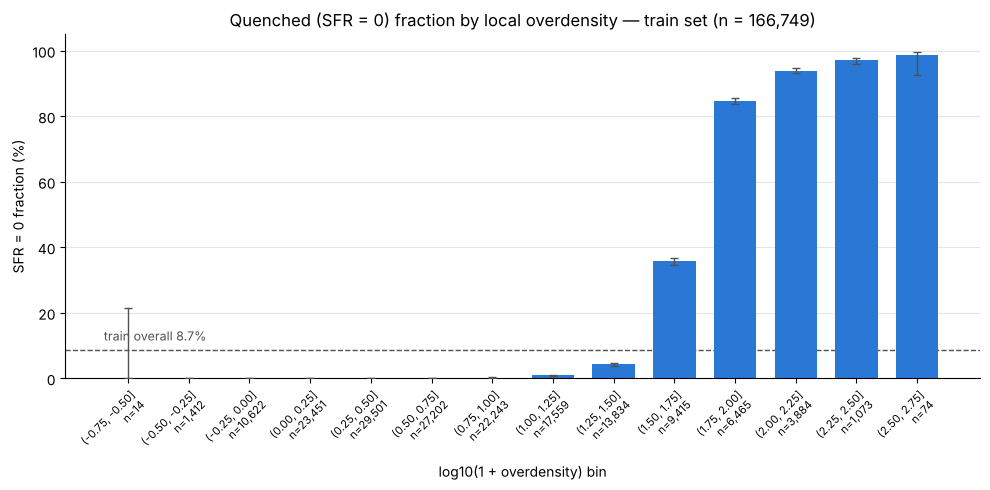

In [16]:
# 그림: 밀도 구간별 SFR = 0 비율 (막대 = 비율, 세로선 = 95% Wilson 구간)
#    글꼴 문제를 피하려고 그림 안 글자는 영어로 쓴다.
x = np.arange(len(zero_by_dens))
rate = zero_by_dens["SFR=0 비율(%)"].to_numpy()
yerr = np.vstack([rate - zero_by_dens["95% CI 하한(%)"], zero_by_dens["95% CI 상한(%)"] - rate])
labels = [f"({iv.left:.2f}, {iv.right:.2f}]" for iv in zero_by_dens.index]
overall = (train[TARGET] == 0).mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x, rate, width=0.7, color="#2a78d6", zorder=2)
ax.errorbar(x, rate, yerr=yerr, fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, zorder=3)
ax.axhline(overall, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(-0.4, overall + 2, f"train overall {overall:.1f}%", ha="left", va="bottom", fontsize=9, color="#52514e")
tick_labels = [f"{lab}\nn={n:,}" for lab, n in zip(labels, zero_by_dens["은하 수"])]
ax.set_xticks(x, tick_labels, rotation=45, ha="right", rotation_mode="anchor", fontsize=8)
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("SFR = 0 fraction (%)")
ax.set_xlabel("log10(1 + overdensity) bin")
ax.set_title("Quenched (SFR = 0) fraction by local overdensity — train set (n = 166,749)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.8, zorder=0)
plt.tight_layout()
plt.show()


#### EDA 1 — 주변 밀도와 SFR = 0 (학습 데이터 166,749개)

**Finding**
- 주변 밀도(`log10_overdensity_plus_1`, 0.25 dex 구간)가 높아질수록 SFR = 0 비율이 **모든 구간에서 단조 증가**했다: (1.00, 1.25] 0.92% → (1.25, 1.50] 4.27% → (1.50, 1.75] 35.70% → (1.75, 2.00] 84.76% → (2.00, 2.25] 93.95%.
- SFR = 0 은하의 **94.2%가 밀도 ≥ 1.5**에 있다. 그러나 밀도 ≥ 1.5인 은하 중에도 **7,306개(34.9%)는 SFR > 0**이다.

**Interpretation**
- 주변 밀도는 SFR = 0 여부와 **강하게 연관**되어 있다. 급격한 전환은 1.5 부근 구간에서 나타났지만, 이는 0.25 dex 구간화에서 보인 패턴이며 절대적인 물리적 임계값은 아니다.
- 밀집된 환경에서 가스를 잃거나 공급이 끊겨 별 생성이 억제된다는 설명과 일관된 패턴이다(물리적 해석, 추정). 이번 EDA로 밀도가 SFR = 0의 원인임을 보인 것은 아니다.

**Modeling implication**
- 주변 밀도는 **중요한 후보 피처**로 유지할 근거가 있다.
- 다만 고밀도에서도 SFR > 0인 은하가 7,306개 있으므로, 밀도 하나로 0/비0을 나누는 규칙이 아니라 **다른 피처를 함께 쓰는 모델**이 필요해 보인다.

**Limitation**
- 통계적 연관이며 인과의 증명이 아니다. 위성/중심 은하 구분 정보가 없고, 밀도의 정확한 정의·측정 반경은 공식 설명에서 확인하지 못했다. 양 끝 일부 구간은 표본이 적다(최저 구간 14개, 최고 구간 74개).


In [17]:
# 가설과 맞지 않는 부분 확인 — 같은 학습 데이터에서 숫자만 센다
zeros = train[train[TARGET] == 0]
pos = train[train[TARGET] > 0]
diffs = zero_by_dens["SFR=0 비율(%)"].diff().dropna()
print("구간이 올라갈 때 0 비율이 줄어드는 곳:",
      [f"{a} → {b}: {d:+.2f}%p" for a, b, d in zip(labels[:-1], labels[1:], diffs) if d < 0] or "없음")
for cut in (1.0, 1.5):
    print(f"밀도 < {cut}인 0 은하: {int((zeros[DENS] < cut).sum()):,}개 (전체 0의 {(zeros[DENS] < cut).mean():.1%})")
for cut in (1.5, 2.0):
    hi = train[DENS] >= cut
    print(f"밀도 ≥ {cut}인 은하 {int(hi.sum()):,}개 중 SFR > 0: {int((train.loc[hi, TARGET] > 0).sum()):,}개 ({(train.loc[hi, TARGET] > 0).mean():.1%})")
print("SFR = 0 은하의 밀도 최솟값:", round(zeros[DENS].min(), 3))


구간이 올라갈 때 0 비율이 줄어드는 곳: 없음
밀도 < 1.0인 0 은하: 80개 (전체 0의 0.6%)
밀도 < 1.5인 0 은하: 833개 (전체 0의 5.8%)
밀도 ≥ 1.5인 은하 20,911개 중 SFR > 0: 7,306개 (34.9%)
밀도 ≥ 2.0인 은하 5,031개 중 SFR > 0: 267개 (5.3%)
SFR = 0 은하의 밀도 최솟값: 0.021


In [18]:
# EDA 2. 항성 질량이 비슷한 은하끼리 비교해도 밀도가 높을수록 SFR = 0 비율이 커지는가? — 학습 데이터만
#    EDA 1의 train, DENS, edges, wilson을 그대로 쓴다. 원본 df와 피처는 바꾸지 않는다.
MASS = "log10_stellar_mass"
SMALL_N = 100      # 이 수보다 적은 구간은 "표본 적음"으로 표시
TINY_N = 30        # 이 수보다 적은 구간은 "매우 적음" (비율을 해석하지 않는다)

mass_q = pd.qcut(train[MASS], q=4, labels=["Q1 (low)", "Q2", "Q3", "Q4 (high)"])   # 학습 데이터 분위수
mass_edges = train[MASS].quantile([0, 0.25, 0.5, 0.75, 1]).round(3).to_list()
print("항성 질량 분위수 경계 (학습):", mass_edges)
dens_bin2 = pd.cut(train[DENS], bins=edges)

q_summary = train.groupby(mass_q, observed=True).agg(
    은하_수=(TARGET, "size"),
    SFR0_수=(TARGET, lambda s: int((s == 0).sum())),
    질량_최소=(MASS, "min"), 질량_최대=(MASS, "max"),
    밀도_중앙값=(DENS, "median"),
    밀도_1_5이상_비율=(DENS, lambda s: (s >= 1.5).mean() * 100),
)
q_summary["SFR0_비율(%)"] = q_summary["SFR0_수"] / q_summary["은하_수"] * 100
display(q_summary.round(3))

g2 = train.groupby([mass_q, dens_bin2], observed=True)[TARGET]
tab2 = pd.DataFrame({"은하 수": g2.size(), "SFR=0 수": g2.apply(lambda s: int((s == 0).sum()))})
tab2["SFR=0 비율(%)"] = tab2["SFR=0 수"] / tab2["은하 수"] * 100
lo2, hi2 = wilson(tab2["SFR=0 수"], tab2["은하 수"])
tab2["95% CI"] = [f"{max(a, 0)*100:.1f}~{b*100:.1f}" for a, b in zip(lo2, hi2)]
tab2["표본"] = np.select([tab2["은하 수"] < TINY_N, tab2["은하 수"] < SMALL_N], ["매우 적음 (<30)", "적음 (<100)"], "")
tab2.index.names = ["질량 집단", "밀도 구간"]
with pd.option_context("display.max_rows", 100):
    display(tab2.round(2))


항성 질량 분위수 경계 (학습): [9.3, 9.547, 9.839, 10.273, 12.962]


,은하_수,SFR0_수,질량_최소,질량_최대,밀도_중앙값,밀도_1_5이상_비율,SFR0_비율(%)
log10_stellar_mass,,,,,,,
Q1 (low),41688,3217,9.300,9.547,0.565,9.981,7.717
Q2,41687,3221,9.547,9.839,0.589,11.402,7.727
Q3,41687,3647,9.839,10.273,0.636,12.834,8.749
Q4 (high),41687,4353,10.273,12.962,0.824,15.945,10.442


은하 수  SFR=0 수  SFR=0 비율(%)      95% CI           표본
질량 집단     밀도 구간                                                             
Q1 (low)  (-0.75, -0.5]    12        0         0.00    0.0~24.3  매우 적음 (<30)
          (-0.5, -0.25]   860        0         0.00     0.0~0.4             
          (-0.25, 0.0]   4387        0         0.00     0.0~0.1             
          (0.0, 0.25]    6875        2         0.03     0.0~0.1             
          (0.25, 0.5]    7034        2         0.03     0.0~0.1             
          (0.5, 0.75]    6171       10         0.16     0.1~0.3             
          (0.75, 1.0]    5019       17         0.34     0.2~0.5             
          (1.0, 1.25]    4026       88         2.19     1.8~2.7             
          (1.25, 1.5]    3143      299         9.51    8.5~10.6             
          (1.5, 1.75]    1980      829        41.87   39.7~44.1             
          (1.75, 2.0]    1256     1080        85.99   84.0~87.8             
          (2.0, 2.25]     735      701        95.37   93.6~96.7             
          (2.25, 2.5]     183      182        99.45   97.0~99.9             
          (2.5, 2.75]       7        7       100.00  64.6~100.0  매우 적음 (<30)
Q2        (-0.75, -0.5]     2        0         0.00    0.0~65.8  매우 적음 (<30)
          (-0.5, -0.25]   461        0         0.00     0.0~0.8             
          (-0.25, 0.0]   3824        0         0.00     0.0~0.1             
          (0.0, 0.25]    6875        0         0.00     0.0~0.1             
          (0.25, 0.5]    7363        3         0.04     0.0~0.1             
          (0.5, 0.75]    6202        6         0.10     0.0~0.2             
          (0.75, 1.0]    4940        7         0.14     0.1~0.3             
          (1.0, 1.25]    4007       25         0.62     0.4~0.9             
          (1.25, 1.5]    3260      130         3.99     3.4~4.7             
          (1.5, 1.75]    2218      786        35.44   33.5~37.5             
          (1.75, 2.0]    1466     1229        83.83   81.9~85.6             
          (2.0, 2.25]     843      810        96.09   94.6~97.2             
          (2.25, 2.5]     212      211        99.53   97.4~99.9             
          (2.5, 2.75]      14       14       100.00  78.5~100.0  매우 적음 (<30)
Q3        (-0.5, -0.25]    90        0         0.00     0.0~4.1    적음 (<100)
          (-0.25, 0.0]   2203        0         0.00     0.0~0.2             
          (0.0, 0.25]    6885        0         0.00     0.0~0.1             
          (0.25, 0.5]    7868        2         0.03     0.0~0.1             
          (0.5, 0.75]    6576        2         0.03     0.0~0.1             
          (0.75, 1.0]    5208       12         0.23     0.1~0.4             
          (1.0, 1.25]    4144       15         0.36     0.2~0.6             
          (1.25, 1.5]    3363       80         2.38     1.9~3.0             
          (1.5, 1.75]    2323      816        35.13   33.2~37.1             
          (1.75, 2.0]    1714     1467        85.59   83.8~87.2             
          (2.0, 2.25]     996      945        94.88   93.3~96.1             
          (2.25, 2.5]     299      290        96.99   94.4~98.4             
          (2.5, 2.75]      18       18       100.00  82.4~100.0  매우 적음 (<30)
Q4 (high) (-0.5, -0.25]     1        0         0.00    0.0~79.3  매우 적음 (<30)
          (-0.25, 0.0]    208        0         0.00     0.0~1.8             
          (0.0, 0.25]    2816        0         0.00     0.0~0.1             
          (0.25, 0.5]    7236        0         0.00     0.0~0.1             
          (0.5, 0.75]    8253        3         0.04     0.0~0.1             
          (0.75, 1.0]    7076       14         0.20     0.1~0.3             
          (1.0, 1.25]    5382       34         0.63     0.5~0.9             
          (1.25, 1.5]    4068       82         2.02     1.6~2.5             
          (1.5, 1.75]    2894      930        32.14   30.5~33.9             
          (1.75, 2.0]

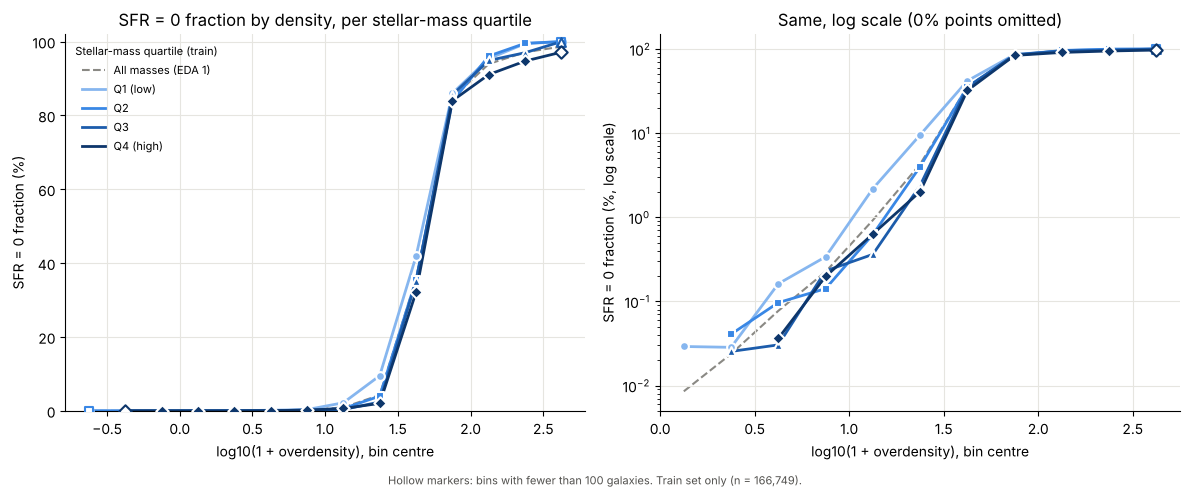

In [19]:
# 그림: 질량 집단별 밀도–SFR=0 비율 곡선 (왼쪽 선형 축, 오른쪽 로그 축으로 낮은 비율까지)
#    색은 질량 순서대로 옅은 파랑 → 진한 파랑, 표본이 100개 미만인 점은 속이 빈 표시
tab2r = tab2.reset_index()
tab2r["밀도 중앙"] = tab2r["밀도 구간"].apply(lambda iv: iv.mid)
overall_curve = zero_by_dens.reset_index()
overall_curve["밀도 중앙"] = overall_curve[DENS].apply(lambda iv: iv.mid)

colors = {"Q1 (low)": "#86b6ef", "Q2": "#3987e5", "Q3": "#1c5cab", "Q4 (high)": "#0d366b"}
markers = {"Q1 (low)": "o", "Q2": "s", "Q3": "^", "Q4 (high)": "D"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, logy in zip(axes, (False, True)):
    oy = overall_curve["SFR=0 비율(%)"]
    ax.plot(overall_curve["밀도 중앙"], oy.where(~(logy & (oy == 0))),
            color="#8a8984", lw=1.5, ls="--", label="All masses (EDA 1)", zorder=1)
    for q, d in tab2r.groupby("질량 집단", observed=True):
        y = d["SFR=0 비율(%)"].where(~(logy & (d["SFR=0 비율(%)"] == 0)))   # 로그 축에서는 0%를 그리지 않는다
        ax.plot(d["밀도 중앙"], y, color=colors[q], lw=2, label=q, zorder=2)
        big = d["은하 수"] >= SMALL_N
        ax.scatter(d.loc[big, "밀도 중앙"], y[big], color=colors[q], marker=markers[q], s=40, zorder=3,
                   edgecolor="white", linewidth=1.5)
        ax.scatter(d.loc[~big, "밀도 중앙"], y[~big], facecolor="white", edgecolor=colors[q], marker=markers[q],
                   s=40, linewidth=1.5, zorder=3)
    ax.set_xlabel("log10(1 + overdensity), bin centre")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color="#e6e5e0", lw=0.8, zorder=0)
    if logy:
        ax.set_yscale("log"); ax.set_ylim(0.005, 150)
        ax.set_ylabel("SFR = 0 fraction (%, log scale)")
        ax.set_title("Same, log scale (0% points omitted)")
    else:
        ax.set_ylim(0, 102); ax.set_ylabel("SFR = 0 fraction (%)")
        ax.set_title("SFR = 0 fraction by density, per stellar-mass quartile")
axes[0].legend(title="Stellar-mass quartile (train)", fontsize=8, title_fontsize=8, frameon=False, loc="upper left")
fig.text(0.5, -0.02, "Hollow markers: bins with fewer than 100 galaxies. Train set only (n = 166,749).",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()


#### EDA 2 — 항성 질량 분위별 주변 밀도와 SFR = 0 (학습 데이터 166,749개)

**Finding**
- `log10_stellar_mass`를 학습 데이터 분위수로 4개 그룹(Q1 낮음 ~ Q4 높음)으로 나눴다. **모든 질량 그룹에서 밀도가 높아질수록 SFR = 0 비율이 거의 단조 증가**했다.
- 같은 밀도 구간에서도 그룹별 차이가 일부 있다. 예: 밀도 (1.50, 1.75]에서 Q1 41.87%, Q2 35.44%, Q3 35.13%, Q4 32.14%.

**Interpretation**
- 항성 질량 분위별로 비교해도 주변 밀도 증가에 따른 SFR = 0 비율의 급격한 증가가 유지되었다. 즉 EDA 1의 관계는 질량 그룹을 나눠 봐도 사라지지 않는다.
- 다만 같은 밀도에서도 질량 그룹별 차이가 있으므로, 질량의 정보도 함께 볼 필요가 있다. 작은 은하가 가스를 더 쉽게 잃는다는 설명이 가능하지만 추정이다.

**Modeling implication**
- 주변 밀도와 항성 질량을 **함께 고려**하는 것이 적절해 보인다. 밀도에 따른 급격한 변화와 질량별 차이를 표현할 수 있는 모델(예: 트리 계열)이 후보이며, 실제 효과는 모델 실험으로 확인한다.

**Limitation**
- 질량을 4개 구간으로 나눠 비교한 것이며, 질량을 정확히 맞추거나 다른 변수의 영향을 모두 고려한 분석은 아니다. 분석 대상은 SFR = 0 여부이며, 양수 SFR의 크기나 RMSE로 확대하지 않는다. 일부 구간은 표본이 적다(표의 "적음"·"매우 적음" 표시).


In [20]:
# 질량을 나누기 전과 후 비교
# (1) 집단별 핵심 숫자: 50%를 처음 넘는 밀도 구간, 전환 구간의 0 비율, 낮은 밀도(< 1.0)의 0 비율
rows = []
for q, d in tab2.groupby(level=0, observed=True):
    d = d.droplevel(0)
    ok = d[d["은하 수"] >= SMALL_N]
    first50 = ok.index[ok["SFR=0 비율(%)"] >= 50]
    sub = train[mass_q == q]
    rows.append({
        "질량 집단": q,
        "50% 처음 넘는 구간 (n≥100)": str(first50[0]) if len(first50) else "없음",
        "(1.25,1.5] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.25, 1.5), np.nan),
        "(1.5,1.75] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.5, 1.75), np.nan),
        "(1.75,2.0] 0 비율(%)": d["SFR=0 비율(%)"].get(pd.Interval(1.75, 2.0), np.nan),
        "밀도<1.0 0 비율(%)": (sub.loc[sub[DENS] < 1.0, TARGET] == 0).mean() * 100,
        "밀도≥1.5 0 비율(%)": (sub.loc[sub[DENS] >= 1.5, TARGET] == 0).mean() * 100,
        "밀도≥1.5 SFR>0 수": int((sub.loc[sub[DENS] >= 1.5, TARGET] > 0).sum()),
        "줄어드는 곳 (n≥100끼리)": sum(ok["SFR=0 비율(%)"].diff().dropna() < 0),
    })
overall_row = {"질량 집단": "전체 (나누기 전)",
    "50% 처음 넘는 구간 (n≥100)": str(zero_by_dens.index[zero_by_dens["SFR=0 비율(%)"] >= 50][0]),
    "(1.25,1.5] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.25, 1.5), "SFR=0 비율(%)"],
    "(1.5,1.75] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.5, 1.75), "SFR=0 비율(%)"],
    "(1.75,2.0] 0 비율(%)": zero_by_dens.loc[pd.Interval(1.75, 2.0), "SFR=0 비율(%)"],
    "밀도<1.0 0 비율(%)": (train.loc[train[DENS] < 1.0, TARGET] == 0).mean() * 100,
    "밀도≥1.5 0 비율(%)": (train.loc[train[DENS] >= 1.5, TARGET] == 0).mean() * 100,
    "밀도≥1.5 SFR>0 수": int((train.loc[train[DENS] >= 1.5, TARGET] > 0).sum()),
    "줄어드는 곳 (n≥100끼리)": 0}
display(pd.DataFrame(rows + [overall_row]).set_index("질량 집단").round(2))

# (2) 질량 구성을 똑같이 맞춘 곡선(직접 표준화): 각 밀도 구간에서 네 집단의 0 비율을 같은 가중치(25%)로 평균
wide = tab2["SFR=0 비율(%)"].unstack(level=0)
wide_n = tab2["은하 수"].unstack(level=0)
std_curve = wide.where(wide_n >= SMALL_N).mean(axis=1, skipna=False)
cmp_std = pd.DataFrame({
    "나누기 전 (원래 비율)": zero_by_dens["SFR=0 비율(%)"],
    "질량 구성 맞춤 (4집단 평균, 모두 n≥100일 때만)": std_curve,
})
cmp_std["차이 (%p)"] = cmp_std.iloc[:, 1] - cmp_std.iloc[:, 0]
display(cmp_std.round(2))


,50% 처음 넘는 구간 (n≥100),"(1.25,1.5] 0 비율(%)","(1.5,1.75] 0 비율(%)","(1.75,2.0] 0 비율(%)",밀도<1.0 0 비율(%),밀도≥1.5 0 비율(%),밀도≥1.5 SFR>0 수,줄어드는 곳 (n≥100끼리)
질량 집단,,,,,,,,
Q1 (low),"(1.75, 2.0]",9.51,41.87,85.99,0.10,67.27,1362,1
Q2,"(1.75, 2.0]",3.99,35.44,83.83,0.05,64.17,1703,0
Q3,"(1.75, 2.0]",2.38,35.13,85.59,0.06,66.09,1814,0
Q4 (high),"(1.75, 2.0]",2.02,32.14,83.98,0.07,63.49,2427,0
전체 (나누기 전),"(1.75, 2.0]",4.27,35.70,84.76,0.07,65.06,7306,0


,나누기 전 (원래 비율),"질량 구성 맞춤 (4집단 평균, 모두 n≥100일 때만)",차이 (%p)
"(-0.75, -0.5]",0.00,NaN,NaN
"(-0.5, -0.25]",0.00,NaN,NaN
"(-0.25, 0.0]",0.00,0.00,0.00
"(0.0, 0.25]",0.01,0.01,-0.00
"(0.25, 0.5]",0.02,0.02,-0.00
"(0.5, 0.75]",0.08,0.08,0.00
"(0.75, 1.0]",0.22,0.23,0.00
"(1.0, 1.25]",0.92,0.95,0.03
"(1.25, 1.5]",4.27,4.47,0.20
"(1.5, 1.75]",35.70,36.14,0.44


In [21]:
# EDA 3. SFR 분포는 왜 예측하기 어려운가 — 학습 데이터(166,749개)만 사용. 검증 타깃은 쓰지 않는다.
y_tr = train[TARGET]
n_tr = len(y_tr)
q = y_tr.quantile([0.5, 0.9, 0.99, 0.999])
sfr3 = pd.Series({
    "은하 수": n_tr,
    "SFR = 0 수": int((y_tr == 0).sum()),
    "SFR = 0 비율(%)": (y_tr == 0).mean() * 100,
    "평균": y_tr.mean(),
    "중앙값": q[0.5],
    "90% 분위수": q[0.9],
    "99% 분위수": q[0.99],
    "99.9% 분위수": q[0.999],
    "최댓값": y_tr.max(),
    "SFR > 100 수": int((y_tr > 100).sum()),
    "SFR > 100 비율(%)": (y_tr > 100).mean() * 100,
})
display(sfr3.round(3).to_frame("학습 데이터"))

# 꼬리 길이를 보여 주는 비율들
tail = pd.Series({
    "평균 / 중앙값": y_tr.mean() / q[0.5],
    "99% 분위수 / 중앙값": q[0.99] / q[0.5],
    "최댓값 / 99.9% 분위수": y_tr.max() / q[0.999],
    "최댓값 / 중앙값": y_tr.max() / q[0.5],
    "왜도(skewness)": y_tr.skew(),
    "log1p 변환 후 왜도": np.log1p(y_tr).skew(),
})
display(tail.round(2).to_frame("값"))
print("상위 5개 SFR:", np.sort(y_tr.to_numpy())[-5:][::-1].round(1))


,학습 데이터
은하 수,166749.000
SFR = 0 수,14438.000
SFR = 0 비율(%),8.659
평균,3.700
중앙값,1.633
90% 분위수,7.551
99% 분위수,35.011
99.9% 분위수,110.600
최댓값,2145.373
SFR > 100 수,209.000


,값
평균 / 중앙값,2.27
99% 분위수 / 중앙값,21.44
최댓값 / 99.9% 분위수,19.40
최댓값 / 중앙값,1313.91
왜도(skewness),60.69
log1p 변환 후 왜도,1.21


상위 5개 SFR: [2145.4 1413.7  764.8  610.   596.5]


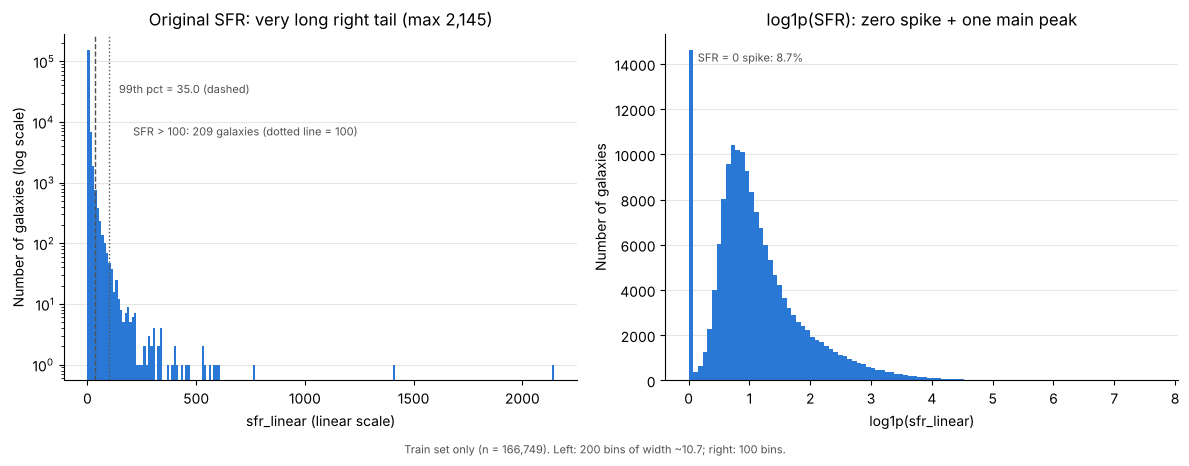

In [22]:
# 그림: 왼쪽 원래 SFR(세로축 로그 — 꼬리의 적은 은하까지 보이게), 오른쪽 log1p(SFR)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
ax.hist(y_tr, bins=200, color="#2a78d6")
ax.set_yscale("log")
ax.axvline(q[0.99], color="#52514e", lw=1, ls="--")
ax.text(q[0.99] + 110, 3e4, f"99th pct = {q[0.99]:.1f} (dashed)", fontsize=8, color="#52514e")
ax.axvline(100, color="#52514e", lw=1, ls=":")
ax.text(210, 6e3, f"SFR > 100: {int((y_tr > 100).sum())} galaxies (dotted line = 100)", fontsize=8, color="#52514e")
ax.set_xlabel("sfr_linear (linear scale)")
ax.set_ylabel("Number of galaxies (log scale)")
ax.set_title("Original SFR: very long right tail (max 2,145)")

ax = axes[1]
ax.hist(np.log1p(y_tr), bins=100, color="#2a78d6")
ax.text(0.15, ax.get_ylim()[1] * 0.92, f"SFR = 0 spike: {(y_tr == 0).mean():.1%}", fontsize=8, color="#52514e")
ax.set_xlabel("log1p(sfr_linear)")
ax.set_ylabel("Number of galaxies")
ax.set_title("log1p(SFR): zero spike + one main peak")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e6e5e0", lw=0.8)
    a.set_axisbelow(True)
fig.text(0.5, -0.02, "Train set only (n = 166,749). Left: 200 bins of width ~10.7; right: 100 bins.",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()


#### EDA 3 — SFR 분포와 타깃 처리 문제 (학습 데이터 166,749개)

**Finding**
- SFR = 0이 **14,438개(8.66%)**이고, 오른쪽 꼬리가 매우 길다: 평균 3.700, 중앙값 1.633, 99% 분위수 35.011, 99.9% 분위수 110.600, 최댓값 2,145.373. SFR > 100은 209개(0.125%)다. 왜도는 원래 60.7, log1p 후 1.21이다.
- **상위 1% 은하가 y² 합의 82.0%**를 차지한다. 모든 은하에 학습 평균 하나를 예측하는 **단순 기준에서는** 상위 1%가 오차제곱합의 86.5%, SFR = 0 은하는 0.87%를 차지한다.
- log1p 척도의 평균을 원래 척도로 되돌리면 2.061로, 원래 평균 3.700의 **55.7%**다.

**Interpretation**
- 선형 RMSE는 오차를 제곱해 평균하므로, **극단적으로 큰 SFR 은하의 예측 오차가 전체 성능에 큰 영향을 줄 가능성**이 있다. 위 82.0%·86.5%는 타깃 자체와 단순 기준의 수치이며, 실제 모델의 오차 구성은 모델마다 다르다.
- 0에 집중된 부분과 긴 꼬리가 함께 있어, 단일 회귀 모델이 두 영역을 동시에 맞추기 어려울 수 있다(추정).
- log1p 변환은 극단값의 영향을 완화하지만, 로그 척도에서의 평균을 원래 척도로 되돌리면 선형 평균보다 크게 작아진다. 따라서 선형 RMSE로 평가하는 이번 문제에서는 log1p 타깃 처리의 장단점을 실제 검증 실험으로 비교할 필요가 있다.

**Modeling implication**
- 원래 척도, log1p 타깃 처리, SFR = 0 여부를 별도로 다루는 방법(EDA 1·2와 연결)을 **같은 선형 RMSE 기준에서 비교**할 필요가 있다.
- 전체 RMSE와 함께 `evaluate_sfr`의 구간별 지표(SFR = 0, SFR > 0, Top 10%)를 보는 것이 좋아 보인다. 실제 성능 개선 여부는 7절의 모델 실험으로 확인한다.

**Limitation**
- 모델 실험 없이 타깃 분포만 본 결과다. 검증 타깃을 보지 않았으므로 검증 데이터의 극단값이 RMSE를 얼마나 흔들지는 모른다. 큰 SFR의 물리적 원인은 다루지 않았다.


In [23]:
# 극단값의 영향력 — 선형 RMSE는 오차 제곱의 평균이라 큰 값의 영향이 커진다
y_sorted = np.sort(y_tr.to_numpy())[::-1]
k1, k10 = int(np.ceil(n_tr * 0.01)), int(np.ceil(n_tr * 0.10))

# (1) y^2 합에서 상위 은하가 차지하는 비율
y2 = y_sorted ** 2
share_y2 = {"상위 0.1%": y2[: int(np.ceil(n_tr * 0.001))].sum() / y2.sum(),
            "상위 1%": y2[:k1].sum() / y2.sum(), "상위 10%": y2[:k10].sum() / y2.sum()}

# (2) 모든 은하에 학습 평균을 똑같이 예측할 때(가장 단순한 기준), 오차 제곱합에서 상위 은하·0 은하가 차지하는 비율
#     (모델이 아니라 "평균 하나로 예측"했을 때의 오차 구조를 보는 참고 계산)
sq_err = (y_sorted - y_tr.mean()) ** 2
share_sse = {"상위 0.1%": sq_err[: int(np.ceil(n_tr * 0.001))].sum() / sq_err.sum(),
             "상위 1%": sq_err[:k1].sum() / sq_err.sum(), "상위 10%": sq_err[:k10].sum() / sq_err.sum()}
zero_share = ((0 - y_tr.mean()) ** 2 * (y_tr == 0).sum()) / sq_err.sum()

impact = pd.DataFrame({"y² 합에서의 비율(%)": pd.Series(share_y2) * 100,
                       "평균 예측 시 오차제곱합에서의 비율(%)": pd.Series(share_sse) * 100})
display(impact.round(2))
print(f"평균 예측 시 오차제곱합에서 SFR = 0 은하({(y_tr == 0).mean():.1%})가 차지하는 비율: {zero_share:.2%}")
print(f"상위 1% 은하의 SFR 하한: {y_sorted[k1 - 1]:.1f}, 상위 10% 은하의 SFR 하한: {y_sorted[k10 - 1]:.2f}")

# (3) 로그 척도의 '평균'을 원래 척도로 되돌리면 원래 평균과 얼마나 다른가 (모델 학습 없이 숫자만 비교)
back = np.expm1(np.log1p(y_tr).mean())
print(f"원래 척도 평균: {y_tr.mean():.3f} | log1p 척도 평균을 되돌린 값 expm1(mean(log1p y)): {back:.3f} "
      f"(원래 평균의 {back / y_tr.mean():.1%})")


,y² 합에서의 비율(%),평균 예측 시 오차제곱합에서의 비율(%)
상위 0.1%,62.35,67.40
상위 1%,82.02,86.47
상위 10%,96.30,96.22


평균 예측 시 오차제곱합에서 SFR = 0 은하(8.7%)가 차지하는 비율: 0.87%
상위 1% 은하의 SFR 하한: 35.0, 상위 10% 은하의 SFR 하한: 7.55
원래 척도 평균: 3.700 | log1p 척도 평균을 되돌린 값 expm1(mean(log1p y)): 2.061 (원래 평균의 55.7%)


---
### 추가 EDA (참고 분석) — EDA 4·5

아래 두 분석은 **공식 제출 EDA(1~3)에 포함하지 않은 참고 분석**이다. 결과·그림·코드는 그대로 보존하며, 최종 보고서 활용 여부는 추후 판단한다. 모두 학습 데이터만 사용했다.


In [24]:
# EDA 4. 블랙홀 질량은 SFR = 0을 설명하는가, SFR > 0 은하의 SFR 억제를 설명하는가? — 학습 데이터만
#    BH 값은 바꾸거나 지우지 않는다. 5.0 근처(seed 추정)와 5.30 근처 봉우리는 따로 구간으로 둔다.
BH = "log10_BH_mass"
bh_tr = train[BH]
print("BH ≤ 5.01 비율(학습):", f"{(bh_tr <= 5.01).mean():.1%}", "| 5.29~5.31:", f"{bh_tr.between(5.29, 5.31).mean():.1%}",
      "| > 7.0:", f"{(bh_tr > 7.0).mean():.1%}")

# 분포를 고려한 구간: 두 봉우리는 좁게, 나머지는 0.5 dex 폭. 오른쪽 끝은 표본이 적어 9 이상을 묶는다.
bh_edges = [4.99, 5.01, 5.29, 5.31, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 11.5]
bh_names = ["≤5.01 (seed 봉우리)", "5.01~5.29", "5.29~5.31 (두 번째 봉우리)", "5.31~5.5", "5.5~6.0", "6.0~6.5",
            "6.5~7.0", "7.0~7.5", "7.5~8.0", "8.0~8.5", "8.5~9.0", "> 9.0"]
bh_bin = pd.cut(bh_tr, bins=bh_edges, labels=bh_names)
assert bh_bin.notna().all()

gb = train.groupby(bh_bin, observed=True)
bh_tab = pd.DataFrame({
    "은하 수": gb.size(),
    "SFR=0 수": gb[TARGET].apply(lambda s: int((s == 0).sum())),
    "BH 중앙값": gb[BH].median(),
    "항성 질량 중앙값": gb[MASS].median(),
    "밀도 중앙값": gb[DENS].median(),
})
bh_tab["SFR=0 비율(%)"] = bh_tab["SFR=0 수"] / bh_tab["은하 수"] * 100
lo4, hi4 = wilson(bh_tab["SFR=0 수"], bh_tab["은하 수"])
bh_tab["95% CI(%)"] = [f"{max(a, 0)*100:.1f}~{b*100:.1f}" for a, b in zip(lo4, hi4)]
bh_tab["표본"] = np.where(bh_tab["은하 수"] < SMALL_N, "적음 (<100)", "")
display(bh_tab[["은하 수", "SFR=0 수", "SFR=0 비율(%)", "95% CI(%)", "BH 중앙값", "항성 질량 중앙값", "밀도 중앙값", "표본"]].round(3))
print(f"학습 전체 SFR=0 비율: {(train[TARGET] == 0).mean():.2%}")
print("SFR=0 여부와 BH의 상관 (점이연, 참고):", round(np.corrcoef(bh_tr, (train[TARGET] == 0).astype(float))[0, 1], 3))


BH ≤ 5.01 비율(학습): 58.4% | 5.29~5.31: 15.6% | > 7.0: 2.8%


,은하 수,SFR=0 수,SFR=0 비율(%),95% CI(%),BH 중앙값,항성 질량 중앙값,밀도 중앙값,표본
log10_BH_mass,,,,,,,,
≤5.01 (seed 봉우리),97325,8959,9.205,9.0~9.4,5.000,9.642,0.641,
5.01~5.29,6070,887,14.613,13.7~15.5,5.025,10.414,0.814,
5.29~5.31 (두 번째 봉우리),25963,1353,5.211,4.9~5.5,5.301,9.857,0.522,
5.31~5.5,15607,1344,8.612,8.2~9.1,5.423,10.375,0.655,
5.5~6.0,13948,1156,8.288,7.8~8.8,5.650,10.746,0.748,
6.0~6.5,2423,259,10.689,9.5~12.0,6.156,11.165,0.948,
6.5~7.0,716,45,6.285,4.7~8.3,6.717,10.983,0.898,
7.0~7.5,683,52,7.613,5.9~9.8,7.271,10.568,0.786,
7.5~8.0,1012,80,7.905,6.4~9.7,7.769,10.755,0.800,


학습 전체 SFR=0 비율: 8.66%
SFR=0 여부와 BH의 상관 (점이연, 참고): -0.005


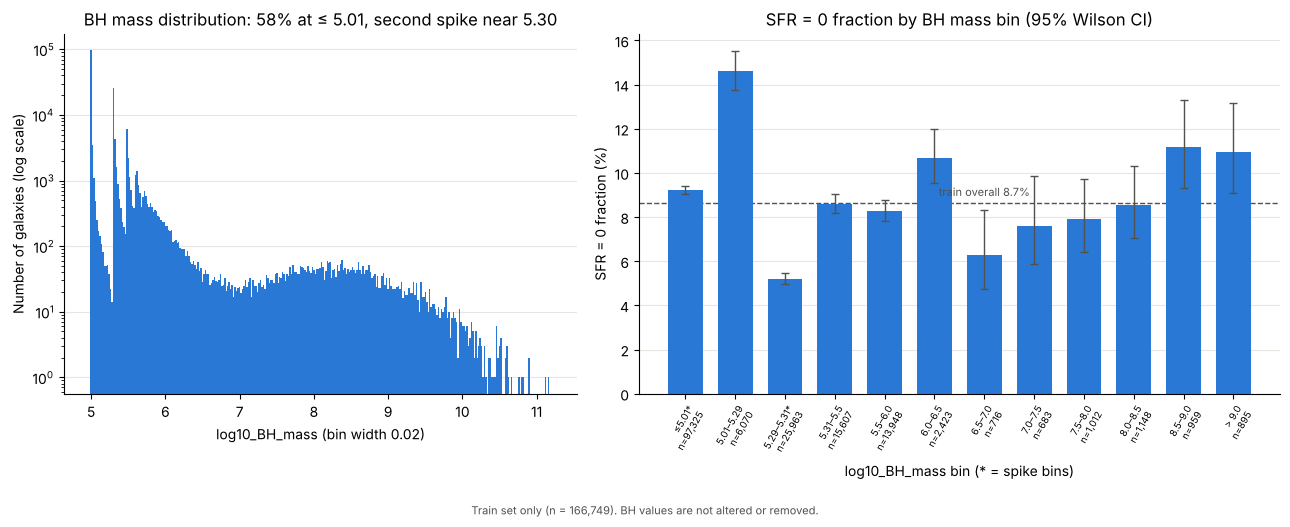

In [25]:
# 그림 A: BH 질량 분포(왼쪽)와 BH 구간별 SFR = 0 비율(오른쪽)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
ax.hist(bh_tr, bins=np.arange(4.95, 11.25, 0.02), color="#2a78d6")
ax.set_yscale("log")
ax.set_xlabel("log10_BH_mass (bin width 0.02)")
ax.set_ylabel("Number of galaxies (log scale)")
ax.set_title(f"BH mass distribution: {(bh_tr <= 5.01).mean():.0%} at ≤ 5.01, second spike near 5.30")

ax = axes[1]
xb = np.arange(len(bh_tab))
rate4 = bh_tab["SFR=0 비율(%)"].to_numpy()
ax.bar(xb, rate4, width=0.7, color="#2a78d6", zorder=2)
ax.errorbar(xb, rate4, yerr=np.vstack([rate4 - np.maximum(lo4, 0) * 100, hi4 * 100 - rate4]),
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, zorder=3)
overall4 = (train[TARGET] == 0).mean() * 100
ax.axhline(overall4, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(6, overall4 + 0.3, f"train overall {overall4:.1f}%", ha="center", fontsize=8, color="#52514e")
en_names = ["≤5.01*", "5.01–5.29", "5.29–5.31*", "5.31–5.5", "5.5–6.0", "6.0–6.5", "6.5–7.0",
            "7.0–7.5", "7.5–8.0", "8.0–8.5", "8.5–9.0", "> 9.0"]
ax.set_xticks(xb, [f"{nm}\nn={n:,}" for nm, n in zip(en_names, bh_tab["은하 수"])], rotation=60, ha="right",
              rotation_mode="anchor", fontsize=7)
ax.set_ylabel("SFR = 0 fraction (%)")
ax.set_xlabel("log10_BH_mass bin (* = spike bins)")
ax.set_title("SFR = 0 fraction by BH mass bin (95% Wilson CI)")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e6e5e0", lw=0.8)
    a.set_axisbelow(True)
fig.text(0.5, -0.04, "Train set only (n = 166,749). BH values are not altered or removed.", ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()


In [26]:
# 분석 2. SFR > 0 학습 은하에서 BH 질량과 SFR — 주계열 잔차로 항성 질량 효과를 뺀다
#    주계열 정의(study/1-1과 같은 방식): SFR > 0 은하에서 log10 SFR을 log10 M*에 대해 1차 직선으로 맞춘 것.
#    여기서는 학습 데이터의 SFR > 0 은하로만 맞춘다. 잔차 = log10 SFR − 주계열 예측 (음수 = 주계열보다 낮음).
pos_tr = train[train[TARGET] > 0]
lsfr = np.log10(pos_tr[TARGET])
ms_slope, ms_int = np.polyfit(pos_tr[MASS], lsfr, 1)
ms_resid = lsfr - (ms_slope * pos_tr[MASS] + ms_int)
print(f"주계열 (학습, SFR>0 n={len(pos_tr):,}): log10 SFR = {ms_slope:.3f} · log10 M* {ms_int:+.3f}, "
      f"상관 {np.corrcoef(pos_tr[MASS], lsfr)[0, 1]:.3f}")

bh_pos = pos_tr[BH]
seed_pos = bh_pos <= 5.01
def _corr(a, b):
    return pd.Series({"Pearson": a.corr(b), "Spearman": a.corr(b, method="spearman"), "n": len(a)})
corr_tab = pd.DataFrame({
    "BH vs log10 SFR (전체 SFR>0)": _corr(bh_pos, lsfr),
    "BH vs 주계열 잔차 (전체 SFR>0)": _corr(bh_pos, ms_resid),
    "BH vs 주계열 잔차 (BH > 5.01만)": _corr(bh_pos[~seed_pos], ms_resid[~seed_pos]),
    "M* vs 주계열 잔차 (확인용, 정의상 ≈0)": _corr(pos_tr[MASS], ms_resid),
}).T
corr_tab["n"] = corr_tab["n"].astype(int)
display(corr_tab.round(3))

bh_bin_pos = pd.cut(bh_pos, bins=bh_edges, labels=bh_names)
gp = pd.DataFrame({"bin": bh_bin_pos, "lsfr": lsfr, "resid": ms_resid, "mass": pos_tr[MASS]}).groupby("bin", observed=True)
res_tab = pd.DataFrame({
    "SFR>0 은하 수": gp.size(),
    "log10 SFR 중앙값": gp["lsfr"].median(),
    "항성 질량 중앙값": gp["mass"].median(),
    "잔차 중앙값 (dex)": gp["resid"].median(),
    "잔차 25%": gp["resid"].quantile(0.25),
    "잔차 75%": gp["resid"].quantile(0.75),
    "잔차 < −0.5 비율(%)": gp["resid"].apply(lambda s: (s < -0.5).mean() * 100),
})
res_tab["표본"] = np.where(res_tab["SFR>0 은하 수"] < SMALL_N, "적음 (<100)", "")
display(res_tab.round(3))


주계열 (학습, SFR>0 n=152,311): log10 SFR = 0.679 · log10 M* -6.444, 상관 0.846


,Pearson,Spearman,n
BH vs log10 SFR (전체 SFR>0),0.422,0.668,152311
BH vs 주계열 잔차 (전체 SFR>0),-0.220,0.140,152311
BH vs 주계열 잔차 (BH > 5.01만),-0.445,0.064,63945
"M* vs 주계열 잔차 (확인용, 정의상 ≈0)",-0.000,0.101,152311


,SFR>0 은하 수,log10 SFR 중앙값,항성 질량 중앙값,잔차 중앙값 (dex),잔차 25%,잔차 75%,잔차 < −0.5 비율(%),표본
bin,,,,,,,,
≤5.01 (seed 봉우리),88366,0.114,9.637,0.004,-0.120,0.110,2.345,
5.01~5.29,5183,0.594,10.419,-0.025,-0.160,0.072,3.396,
5.29~5.31 (두 번째 봉우리),24610,0.304,9.854,0.071,-0.036,0.162,0.715,
5.31~5.5,14263,0.651,10.369,0.085,-0.027,0.179,1.031,
5.5~6.0,12792,0.965,10.741,0.142,0.036,0.231,1.321,
6.0~6.5,2164,1.307,11.170,0.186,0.077,0.299,1.802,
6.5~7.0,671,1.091,10.974,0.095,-0.069,0.232,3.130,
7.0~7.5,631,0.592,10.569,-0.119,-0.264,0.039,6.181,
7.5~8.0,932,0.552,10.767,-0.270,-0.428,-0.116,14.270,


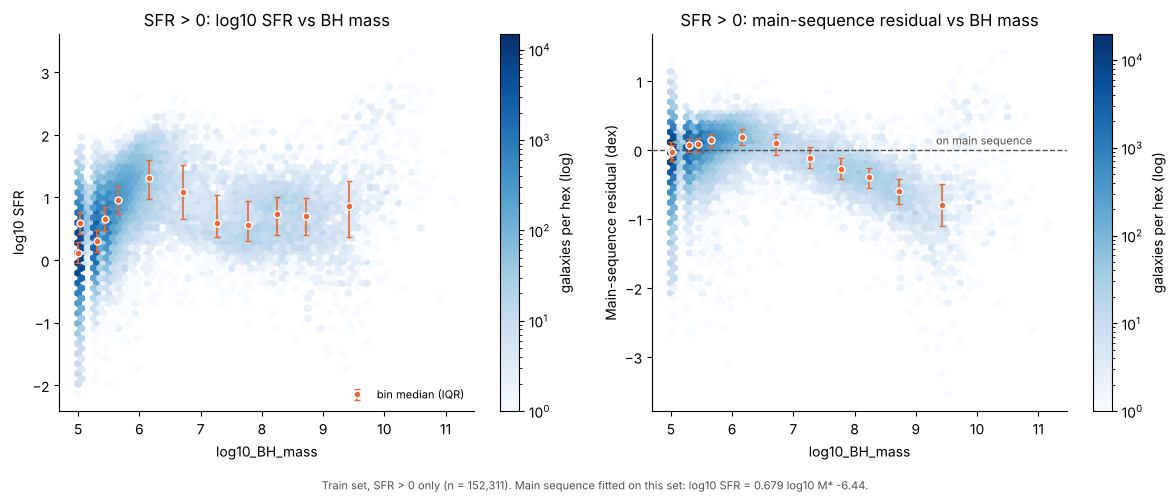

In [27]:
# 그림 B: SFR > 0 은하에서 BH 질량과 log10 SFR(왼쪽), 주계열 잔차(오른쪽). 점은 BH 구간별 중앙값, 세로선은 25~75%
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
mids = gp["resid"].median().index
xmed = gp.apply(lambda d: pos_tr.loc[d.index, BH].median())
for ax, col, ylab, title in [
    (axes[0], lsfr, "log10 SFR", "SFR > 0: log10 SFR vs BH mass"),
    (axes[1], ms_resid, "Main-sequence residual (dex)", "SFR > 0: main-sequence residual vs BH mass"),
]:
    hb = ax.hexbin(bh_pos, col, gridsize=60, bins="log", cmap="Blues", mincnt=1)
    key = "lsfr" if col is lsfr else "resid"
    med = gp[key].median(); q1 = gp[key].quantile(0.25); q3 = gp[key].quantile(0.75)
    ax.errorbar(xmed, med, yerr=[med - q1, q3 - med], fmt="o", color="#eb6834", ecolor="#eb6834",
                ms=5, mec="white", mew=1, elinewidth=1.2, capsize=2, label="bin median (IQR)")
    ax.set_xlabel("log10_BH_mass")
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)
    fig.colorbar(hb, ax=ax, label="galaxies per hex (log)")
axes[1].axhline(0, color="#52514e", lw=1, ls="--")
axes[1].text(10.9, 0.08, "on main sequence", ha="right", fontsize=8, color="#52514e")
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.text(0.5, -0.03, f"Train set, SFR > 0 only (n = {len(pos_tr):,}). Main sequence fitted on this set: "
         f"log10 SFR = {ms_slope:.3f} log10 M* {ms_int:+.2f}.", ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()


#### EDA 4 (추가) — 블랙홀 질량과 SFR 억제 (학습 데이터 166,749개)

**Finding**
- BH 질량 구간별 SFR = 0 비율은 대부분 6~11%이며 **뚜렷한 단조 관계가 없다**(최고 5.01~5.29 구간 14.6%, 최저 5.29~5.31 구간 5.2%; SFR = 0 여부와의 상관 −0.005).
- SFR > 0 은하(152,311개)에서 주계열 잔차(학습 데이터로 맞춘 log10 SFR = 0.679·log10 M* − 6.444 기준)는 BH ≈ 6.0~6.5까지 오히려 +0.19 dex로 높다가, **BH ≳ 7부터 낮아져** BH > 9.0에서 −0.80 dex가 된다. 그래서 잔차와의 상관은 Pearson −0.220, Spearman +0.140으로 부호가 다르다.

**Interpretation**
- 통계적으로 BH는 SFR = 0 여부보다 **SFR > 0 은하의 SFR이 주계열보다 낮은 현상**과 더 관련되어 보이며, 그 관계는 BH ≳ 7 구간에 집중된다.
- AGN 피드백이 별 생성을 0이 아니라 "주계열 아래로" 낮춘다는 설명과 일관된다(물리적 해석, 추정).
- 다만 큰 BH 은하는 항성 질량도 크다. 주계열을 직선으로 맞췄으므로, **항성 질량 및 주계열 곡률 효과와 완전히 분리되지 않았다.**

**Modeling implication**
- BH는 SFR = 0 분류보다는 **양수 SFR 크기 예측의 후보 피처**로 볼 근거가 있다. 관계가 비단조이므로 비선형 모델이 표현하기 쉬울 수 있다. 실제 기여는 모델 실험(예: BH 제외 비교)으로 확인한다.

**Limitation**
- BH ≈ 5.0·5.30 봉우리의 의미(seed 질량 등)는 공식 확인되지 않았다. 통계적 연관이며 인과가 아니다. BH ≳ 6.5 구간은 구간당 약 700~1,100개다.


In [28]:
# EDA 5. 병합 후보 은하는 극단적으로 높은 SFR을 보일 가능성이 더 높은가? — 학습 데이터만
#    "병합 후보" = log10_mass_ratio > -6 (데이터상의 지표 기준. -6의 공식 의미는 확인되지 않았다). -6 값은 그대로 둔다.
MR = "log10_mass_ratio"
merger = train[MR] > -6
grp_name = pd.Series(np.where(merger, "병합 후보 (mass_ratio > -6)", "비후보 (mass_ratio = -6)"), index=train.index)
assert ((train[MR] == -6) | merger).all()

def _sfr_stats(s):
    return pd.Series({
        "은하 수": len(s), "비율(%)": len(s) / len(train) * 100,
        "SFR=0 비율(%)": (s == 0).mean() * 100, "SFR 중앙값": s.median(),
        "90%": s.quantile(0.9), "99%": s.quantile(0.99), "99.9%": s.quantile(0.999), "최댓값": s.max(),
        "SFR>100 수": int((s > 100).sum()), "SFR>100 비율(%)": (s > 100).mean() * 100,
    })
grp_tab = pd.DataFrame({g: _sfr_stats(train.loc[grp_name == g, TARGET]) for g in grp_name.unique()}).T
grp_tab.loc["학습 전체"] = _sfr_stats(train[TARGET])
ctx = train.groupby(grp_name)[[MASS, DENS, BH]].median().rename(columns={MASS: "항성 질량 중앙값", DENS: "밀도 중앙값", BH: "BH 중앙값"})
ctx.loc["학습 전체"] = train[[MASS, DENS, BH]].median().values
display(grp_tab.join(ctx).round(3))


,은하 수,비율(%),SFR=0 비율(%),SFR 중앙값,90%,99%,99.9%,최댓값,SFR>100 수,SFR>100 비율(%),항성 질량 중앙값,밀도 중앙값,BH 중앙값
비후보 (mass_ratio = -6),140601.0,84.319,10.262,1.428,4.984,18.374,49.922,405.787,22.0,0.016,9.778,0.698,5.001
병합 후보 (mass_ratio > -6),26148.0,15.681,0.034,4.737,22.326,86.367,296.302,2145.373,187.0,0.715,10.391,0.548,5.337
학습 전체,166749.0,100.000,8.659,1.633,7.551,35.011,110.600,2145.373,209.0,0.125,9.839,0.664,5.001


In [29]:
# 분석 2. SFR 기준별 병합 후보 비율 (기준선: 학습 전체의 병합 후보 비율)
base_rate = merger.mean()
q99 = train[TARGET].quantile(0.99)
crit = {
    "SFR = 0": train[TARGET] == 0,
    "SFR > 10": train[TARGET] > 10,
    "SFR > 30": train[TARGET] > 30,
    f"상위 1% (SFR ≥ {q99:.2f})": train[TARGET] >= q99,
    "SFR > 100": train[TARGET] > 100,
}
rows = []
for name, m in crit.items():
    n, k = int(m.sum()), int((m & merger).sum())
    lo, hi = wilson(np.array([k]), np.array([n]))
    rows.append({"기준": name, "해당 은하 수": n, "병합 후보 수": k, "병합 후보 비율(%)": k / n * 100,
                 "95% CI(%)": f"{lo[0]*100:.1f}~{hi[0]*100:.1f}", "기준선 대비 배수": (k / n) / base_rate,
                 "표본": "적음 (<300)" if n < 300 else ""})
crit_tab = pd.DataFrame(rows).set_index("기준")
display(crit_tab.round(2))
print(f"기준선 — 학습 전체 병합 후보 비율: {base_rate:.2%} ({int(merger.sum()):,} / {len(train):,})")
print(f"SFR > 100 중 비후보: {int(((train[TARGET] > 100) & ~merger).sum())}개")

# 병합 후보 안에서 SFR이 얼마나 퍼져 있는가 (모두 높은 SFR은 아니다)
mpos = train.loc[merger, TARGET]
print(f"병합 후보 중 SFR > 100: {(mpos > 100).mean():.2%}, SFR > 10: {(mpos > 10).mean():.1%}, "
      f"SFR ≤ 중앙값(학습 전체 {train[TARGET].median():.2f}) : {(mpos <= train[TARGET].median()).mean():.1%}")

# 질문 4용: SFR 영역별로 병합 후보·밀도·BH·항성 질량을 나란히 (기술 통계만)
regime = pd.cut(train[TARGET], bins=[-0.1, 0, 10, 100, np.inf], labels=["SFR = 0", "0 < SFR ≤ 10", "10 < SFR ≤ 100", "SFR > 100"])
reg_tab = train.groupby(regime, observed=True).agg(
    은하_수=(TARGET, "size"),
    병합후보_비율=(MR, lambda s: (s > -6).mean() * 100),
    밀도_중앙값=(DENS, "median"),
    밀도_1_5이상_비율=(DENS, lambda s: (s >= 1.5).mean() * 100),
    BH_중앙값=(BH, "median"),
    항성질량_중앙값=(MASS, "median"),
)
display(reg_tab.round(2))


,해당 은하 수,병합 후보 수,병합 후보 비율(%),95% CI(%),기준선 대비 배수,표본
기준,,,,,,
SFR = 0,14438,9,0.06,0.0~0.1,0.00,
SFR > 10,11696,7161,61.23,60.3~62.1,3.90,
SFR > 30,2169,1661,76.58,74.8~78.3,4.88,
상위 1% (SFR ≥ 35.01),1668,1308,78.42,76.4~80.3,5.00,
SFR > 100,209,187,89.47,84.6~92.9,5.71,적음 (<300)


기준선 — 학습 전체 병합 후보 비율: 15.68% (26,148 / 166,749)
SFR > 100 중 비후보: 22개
병합 후보 중 SFR > 100: 0.72%, SFR > 10: 27.4%, SFR ≤ 중앙값(학습 전체 1.63) : 15.1%


,은하_수,병합후보_비율,밀도_중앙값,밀도_1_5이상_비율,BH_중앙값,항성질량_중앙값
sfr_linear,,,,,,
SFR = 0,14438,0.06,1.88,94.23,5.00,9.92
0 < SFR ≤ 10,140615,13.50,0.57,4.72,5.00,9.78
10 < SFR ≤ 100,11487,60.71,0.81,5.09,5.73,11.03
SFR > 100,209,89.47,1.41,39.71,6.87,11.95


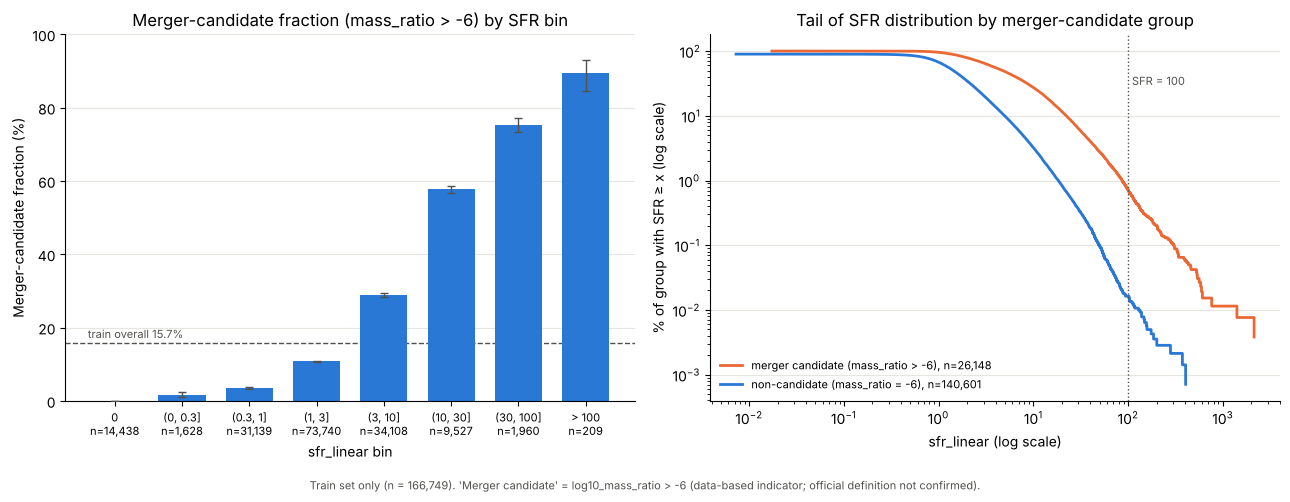

,n,k,rate,95% CI(%)
sfr_linear,,,,
0,14438,9,0.06,0.0~0.1
"(0, 0.3]",1628,27,1.66,1.1~2.4
"(0.3, 1]",31139,1108,3.56,3.4~3.8
"(1, 3]",73740,7962,10.80,10.6~11.0
"(3, 10]",34108,9881,28.97,28.5~29.5
"(10, 30]",9527,5500,57.73,56.7~58.7
"(30, 100]",1960,1474,75.20,73.2~77.1
> 100,209,187,89.47,84.6~92.9


In [30]:
# 그림: 왼쪽 = SFR 구간별 병합 후보 비율, 오른쪽 = 두 집단의 SFR 꼬리 (SFR > x인 비율, 로그-로그)
sfr_edges = [-0.1, 0, 0.3, 1, 3, 10, 30, 100, np.inf]
sfr_labels = ["0", "(0, 0.3]", "(0.3, 1]", "(1, 3]", "(3, 10]", "(10, 30]", "(30, 100]", "> 100"]
sb = pd.cut(train[TARGET], bins=sfr_edges, labels=sfr_labels)
gm = merger.groupby(sb, observed=True)
mfrac = pd.DataFrame({"n": gm.size(), "k": gm.sum()})
mfrac["rate"] = mfrac["k"] / mfrac["n"] * 100
lo5, hi5 = wilson(mfrac["k"].to_numpy(), mfrac["n"].to_numpy())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
xs = np.arange(len(mfrac))
ax.bar(xs, mfrac["rate"], width=0.7, color="#2a78d6", zorder=2)
ax.errorbar(xs, mfrac["rate"], yerr=[mfrac["rate"] - np.maximum(lo5, 0) * 100, hi5 * 100 - mfrac["rate"]],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=3, zorder=3)
ax.axhline(base_rate * 100, color="#52514e", lw=1, ls="--", zorder=1)
ax.text(-0.4, base_rate * 100 + 1.5, f"train overall {base_rate:.1%}", fontsize=8, color="#52514e")
ax.set_xticks(xs, [f"{lab}\nn={n:,}" for lab, n in zip(mfrac.index, mfrac["n"])], fontsize=8)
ax.set_ylim(0, 100)
ax.set_xlabel("sfr_linear bin")
ax.set_ylabel("Merger-candidate fraction (%)")
ax.set_title("Merger-candidate fraction (mass_ratio > -6) by SFR bin")

ax = axes[1]
for m, lab, col in [(True, "merger candidate (mass_ratio > -6)", "#eb6834"), (False, "non-candidate (mass_ratio = -6)", "#2a78d6")]:
    s = np.sort(train.loc[merger == m, TARGET].to_numpy())
    s = s[s > 0]
    n_all = int((merger == m).sum())
    surv = (len(s) - np.arange(len(s))) / n_all          # SFR ≥ x인 비율 (해당 집단 전체 대비)
    ax.step(s, surv * 100, where="post", color=col, lw=2, label=f"{lab}, n={n_all:,}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(100, color="#52514e", lw=1, ls=":")
ax.text(110, 30, "SFR = 100", fontsize=8, color="#52514e")
ax.set_xlabel("sfr_linear (log scale)")
ax.set_ylabel("% of group with SFR ≥ x (log scale)")
ax.set_title("Tail of SFR distribution by merger-candidate group")
ax.legend(frameon=False, fontsize=8, loc="lower left")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e6e5e0", lw=0.8)
    a.set_axisbelow(True)
fig.text(0.5, -0.03, "Train set only (n = 166,749). 'Merger candidate' = log10_mass_ratio > -6 (data-based indicator; official definition not confirmed).",
         ha="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()
display(mfrac.assign(**{"95% CI(%)": [f"{max(a,0)*100:.1f}~{b*100:.1f}" for a, b in zip(lo5, hi5)]}).round(2))


In [31]:
# EDA 5 추가 검증. 항성 질량 분위별로 비교해도 병합 후보와 높은 SFR의 관계가 유지되는가? — 학습 데이터만
#    질량 그룹은 EDA 2의 mass_q(학습 데이터 4분위)를 그대로 쓴다. 병합 후보 = log10_mass_ratio > -6.
TINY_SFR_N = 30
rows = []
for q in mass_q.cat.categories:
    in_q = mass_q == q
    base_q = merger[in_q].mean()
    q99_in = train.loc[in_q, TARGET].quantile(0.99)
    crits = [("그룹 전체", in_q), ("SFR = 0", in_q & (train[TARGET] == 0)),
             ("SFR > 10", in_q & (train[TARGET] > 10)), ("SFR > 30", in_q & (train[TARGET] > 30)),
             ("SFR > 100", in_q & (train[TARGET] > 100)),
             (f"그룹 내 상위 1% (SFR ≥ {q99_in:.1f})", in_q & (train[TARGET] >= q99_in))]
    for name, m in crits:
        n, k = int(m.sum()), int((m & merger).sum())
        if n:
            lo, hi = wilson(np.array([k]), np.array([n]))
            ci = f"{max(lo[0], 0)*100:.1f}~{hi[0]*100:.1f}"
        else:
            ci = "—"
        rows.append({"질량 그룹": q, "기준": name, "은하 수": n, "병합 후보 수": k,
                     "병합 후보 비율(%)": k / n * 100 if n else np.nan, "95% CI(%)": ci,
                     "그룹 기준선 대비 배수": (k / n) / base_q if n else np.nan,
                     "표본": "매우 적음 (<30)" if n < TINY_SFR_N else ("적음 (<100)" if n < SMALL_N else "")})
mq_tab = pd.DataFrame(rows).set_index(["질량 그룹", "기준"])
with pd.option_context("display.max_rows", 50):
    display(mq_tab.round(2))

# 요약: 그룹 × 기준 비율만 한 표로
wide_rate = mq_tab["병합 후보 비율(%)"].unstack(level=1)
wide_n = mq_tab["은하 수"].unstack(level=1)
order = ["그룹 전체", "SFR = 0", "SFR > 10", "SFR > 30", "SFR > 100"]
summary = wide_rate[order].round(1).astype(str) + "% (n=" + wide_n[order].astype(int).map("{:,}".format) + ")"
display(summary)
print("SFR > 100 은하의 질량 그룹 분포:", train.loc[train[TARGET] > 100].groupby(mass_q[train[TARGET] > 100], observed=False).size().to_dict())


은하 수  병합 후보 수  병합 후보 비율(%)  95% CI(%)  \
질량 그룹     기준                                                                
Q1 (low)  그룹 전체                    41688     2460         5.90    5.7~6.1   
          SFR = 0                   3217        2         0.06    0.0~0.2   
          SFR > 10                     4        0         0.00   0.0~49.0   
          SFR > 30                     0        0          NaN          —   
          SFR > 100                    0        0          NaN          —   
          그룹 내 상위 1% (SFR ≥ 2.3)     417       56        13.43  10.5~17.0   
Q2        그룹 전체                    41687     3568         8.56    8.3~8.8   
          SFR = 0                   3221        1         0.03    0.0~0.2   
          SFR > 10                    13        0         0.00   0.0~22.8   
          SFR > 30                     0        0          NaN          —   
          SFR > 100                    0        0          NaN          —   
          그룹 내 상위 1% (SFR ≥ 3.3)     417      106        25.42  21.5~29.8   
Q3        그룹 전체                    41687     5538        13.28  13.0~13.6   
          SFR = 0                   3647        1         0.03    0.0~0.2   
          SFR > 10                    27        0         0.00   0.0~12.5   
          SFR > 30                     0        0          NaN          —   
          SFR > 100                    0        0          NaN          —   
          그룹 내 상위 1% (SFR ≥ 6.1)     417      162        38.85  34.3~43.6   
Q4 (high) 그룹 전체                    41687    14582        34.98  34.5~35.4   
          SFR = 0                   4353        5         0.11    0.0~0.3   
          SFR > 10                 11652     7161        61.46  60.6~62.3   
          SFR > 30                  2169     1661        76.58  74.8~78.3   
          SFR > 100                  209      187        89.47  84.6~92.9   
          그룹 내 상위 1% (SFR ≥ 73.1)    417      371        88.97  85.6~91.6   

                                   그룹 기준선 대비 배수           표본  
질량 그룹     기준                                                  
Q1 (low)  그룹 전체                            1.00               
          SFR = 0                          0.01               
          SFR > 10                         0.00  매우 적음 (<30)  
          SFR > 30                          NaN  매우 적음 (<30)  
          SFR > 100                         NaN  매우 적음 (<30)  
          그룹 내 상위 1% (SFR ≥ 2.3)           2.28               
Q2        그룹 전체                            1.00               
          SFR = 0                          0.00               
          SFR > 10                         0.00  매우 적음 (<30)  
          SFR > 30                          NaN  매우 적음 (<30)  
          SFR > 100                         NaN  매우 적음 (<30)  
          그룹 내 상위 1% (SFR ≥ 3.3)           2.97               
Q3        그룹 전체                            1.00               
          SFR = 0                          0.00               
          SFR > 10                         0.00  매우 적음 (<30)  
          SFR > 30                          NaN  매우 적음 (<30)  
          SFR > 100                         NaN  매우 적음 (<30)  
          그룹 내 상위 1% (SFR ≥ 6.1)           2.92               
Q4 (high) 그룹 전체                            1.00               
          SFR = 0                          0.00               
          SFR > 10                         1.76               
          SFR > 30                         2.19               
          SFR > 100                        2.56               
          그룹 내 상위 1% (SFR ≥ 73.1)          2.54

기준,그룹 전체,SFR = 0,SFR > 10,SFR > 30,SFR > 100
질량 그룹,,,,,
Q1 (low),"5.9% (n=41,688)","0.1% (n=3,217)",0.0% (n=4),NaN,NaN
Q2,"8.6% (n=41,687)","0.0% (n=3,221)",0.0% (n=13),NaN,NaN
Q3,"13.3% (n=41,687)","0.0% (n=3,647)",0.0% (n=27),NaN,NaN
Q4 (high),"35.0% (n=41,687)","0.1% (n=4,353)","61.5% (n=11,652)","76.6% (n=2,169)",89.5% (n=209)


SFR > 100 은하의 질량 그룹 분포: {'Q1 (low)': 0, 'Q2': 0, 'Q3': 0, 'Q4 (high)': 209}


#### EDA 5 (추가) — 병합 후보와 높은 SFR (학습 데이터 166,749개)

"병합 후보"는 `log10_mass_ratio > −6`인 은하를 뜻하는 **데이터상의 지표 기준**이다(−6의 공식 의미는 확인되지 않음).

**Finding**
- 병합 후보는 학습 데이터의 15.7%이며, SFR 중앙값 4.74(비후보 1.43), SFR = 0 비율 0.03%(비후보 10.26%)다.
- **SFR이 높아질수록 병합 후보 비율이 크게 증가**한다: SFR > 10에서 61.2%, SFR > 30에서 76.6%, 상위 1%에서 78.4%, **SFR > 100에서 89.5%(209개 중 187개)**. SFR = 0에서는 0.06%다.
- 항성 질량 분위별 **그룹 내 상위 1%**에서도 병합 후보 비율이 그룹 기준선의 2.3~3.0배로 높다(Q1 13.4%, Q2 25.4%, Q3 38.9%, Q4 89.0%).

**Interpretation**
- 통계적으로 병합 후보는 SFR = 0과 거의 겹치지 않고 **높은 SFR 쪽에 집중**된다. 질량 분위별로 봐도 같은 방향이 보여, 질량 차이만으로 설명하기는 어려워 보인다.
- 다만 **절대적인 극단 SFR(> 30, > 100)은 거의 모두 Q4**에 있고, Q4는 질량 범위가 넓어 **질량 효과가 남아 있을 수 있다.**
- 병합이 가스를 중심으로 몰아 폭발적 별 생성을 일으킨다는 설명과 일관된다(물리적 해석, 추정). 인과관계는 확정하지 않는다.

**Modeling implication**
- 병합 피처(`log10_mass_ratio`)는 **높은 SFR 예측의 후보로 유지할 근거**가 있다. SFR = 0 여부에는 정보가 거의 없어 보인다. 높은 SFR 영역을 따로 다루는 구조를 실험할지는 모델 실험으로 판단한다.

**Limitation**
- 병합 지표의 공식 정의가 확인되지 않았다. SFR > 100은 209개뿐이다. 질량을 4개 분위로 나눠 비교한 것일 뿐 교란 요인을 제거한 것은 아니며, 인과관계는 확인하지 않았다.


### 3.1 EDA Findings — **STUDENT RESPONSE**

> 핵심 EDA 1~3의 결과다. 모두 학습 데이터 166,749개만 사용했으며(템플릿 5절과 같은 분할), 통계적 연관성 수준의 결과다. 실제 모델 기여는 후속 실험으로 확인한다.

**Finding 1 — EDA 1: 주변 밀도와 SFR = 0**
- *Finding*: 주변 밀도(`log10_overdensity_plus_1`, 0.25 dex 구간)가 높아질수록 SFR = 0 비율이 감소하는 구간 없이 급격히 증가했다: (1.00, 1.25] 0.92% → (1.25, 1.50] 4.27% → (1.50, 1.75] 35.70% → (1.75, 2.00] 84.76% → (2.00, 2.25] 93.95% (학습 전체 8.66%). SFR = 0 은하의 94.2%가 밀도 ≥ 1.5에 있다. 그러나 **밀도 ≥ 1.5인 은하 중 7,306개(34.9%)는 SFR > 0**이다.
- *Interpretation*: 주변 밀도는 SFR = 0 여부와 강하게 연관되어 있다. 밀집 환경에서 가스를 잃어 별 생성이 억제된다는 설명과 일관되지만(추정), 원인을 입증한 것은 아니다. 1.5 부근은 구간화에서 전환이 보인 곳이며 물리적 임계값이 아니다.
- *Modeling implication*: 주변 밀도는 중요한 후보 피처다. 다만 고밀도에서도 SFR > 0인 은하가 많으므로 밀도 하나로 0/비0을 나눌 수 없고, 다른 피처와 함께 고려해야 한다.
- *Limitation*: 위성/중심 은하 구분이 없고, 밀도의 정의·측정 반경은 공식 설명에서 확인하지 못했다. 양 끝 일부 구간은 표본이 적다.

**Finding 2 — EDA 2: 항성 질량 분위별 주변 밀도와 SFR = 0**
- *Finding*: 항성 질량을 4개 분위 그룹(Q1~Q4)으로 나눠 비교해도 모든 그룹에서 밀도 증가에 따라 SFR = 0 비율이 거의 단조 증가했다. 같은 밀도에서도 차이가 일부 있다: (1.50, 1.75]에서 Q1 41.87%, Q2 35.44%, Q3 35.13%, Q4 32.14%.
- *Interpretation*: 항성 질량 분위별로 비교해도 주변 밀도 증가에 따른 SFR = 0 비율의 급격한 증가가 유지되었다. 다만 질량 그룹별 차이도 있어 질량 정보도 함께 볼 필요가 있다.
- *Modeling implication*: 주변 밀도와 항성 질량을 함께 고려하고, 급격한 변화와 그룹 차이를 표현할 수 있는 비선형 모델(예: 트리 계열)을 비교할 근거가 있다.
- *Limitation*: 질량을 4개 구간으로 나눠 비교한 것이며 다른 변수의 영향을 모두 고려한 분석이 아니다. 대상은 SFR = 0 여부이며 양수 SFR의 크기나 RMSE로 확대하지 않는다.

**Finding 3 — EDA 3: SFR 분포와 타깃 처리**
- *Finding*: SFR = 0이 14,438개(8.66%)이고 오른쪽 꼬리가 매우 길다(중앙값 1.633, 평균 3.700, 99% 35.011, 99.9% 110.600, 최댓값 2,145.373; SFR > 100은 209개, 0.125%). **상위 1% 은하가 y² 합의 82.0%**를 차지하고, 평균 하나로 예측하는 단순 기준선에서는 상위 1%가 오차제곱합의 86.5%다. log1p 척도 평균을 되돌리면 2.061로 선형 평균의 55.7%다.
- *Interpretation*: 선형 RMSE에서는 극단적으로 큰 SFR 은하의 예측 오차가 전체 성능에 큰 영향을 줄 가능성이 있다(위 수치는 타깃과 단순 기준선의 값이며 실제 모델의 오차 구성은 아니다). log1p 변환은 극단값의 영향을 완화하지만, 로그 척도 평균을 되돌리면 선형 평균보다 크게 작아지므로 장단점은 실제 검증 실험으로 비교해야 한다.
- *Modeling implication*: 원래 척도, log1p 타깃 처리, SFR = 0을 별도로 다루는 방법을 **같은 선형 RMSE 기준**에서 비교하고, `evaluate_sfr`의 구간별 지표(SFR = 0, SFR > 0, Top 10%)도 함께 본다.
- *Limitation*: 모델 실험 없이 타깃 분포만 본 결과다. 검증 타깃을 보지 않았으므로 검증 데이터의 극단값이 RMSE에 줄 영향은 모른다.

**Additional finding(s)** — 참고 분석(핵심 제출 EDA 아님, 위 "추가 EDA" 구역에 상세)
- EDA 4 (블랙홀): BH 질량은 SFR = 0 여부와 뚜렷한 단조 관계가 없고, BH ≳ 7에서 SFR > 0 은하의 주계열 잔차가 낮아진다. 항성 질량·주계열 곡률 효과와 완전히 분리되지 않았다.
- EDA 5 (병합 후보, `log10_mass_ratio > −6`): SFR이 높을수록 병합 후보 비율이 증가한다(SFR > 100에서 89.5%). 질량 분위별 상위 1%에서도 높지만, 극단 SFR은 거의 모두 Q4에 있어 질량 효과가 남아 있을 수 있다.

**Modeling decisions motivated by the EDA:** 주변 밀도와 항성 질량을 함께 쓰는 비선형 모델을 후보로 하고, 원래 척도·log1p·SFR = 0 분리(2단계) 등 타깃 처리를 같은 선형 RMSE와 구간별 지표로 비교한다. 어떤 방법이 실제로 RMSE를 개선하는지는 모델 실험(5~7절)에서 확인한다.


## 4. Data Preparation & Feature Engineering — **STUDENT WORK**

Document all choices that affect model inputs. Discuss feature inclusion/exclusion, missing-value treatment, transformations, scaling, and engineered features where applicable. **`subhalo_id` must not be used as a predictive feature.**

In [32]:
# Default allowed feature set. You may modify FINAL_FEATURES, but never include subhalo_id or sfr_linear.
ALLOWED_FEATURES = [c for c in df.columns if c not in [ID_COLUMN, TARGET]]
FINAL_FEATURES = ALLOWED_FEATURES.copy()

assert ID_COLUMN not in FINAL_FEATURES
assert TARGET not in FINAL_FEATURES
assert set(FINAL_FEATURES).issubset(set(ALLOWED_FEATURES))

X = df[FINAL_FEATURES].copy()
y = df[TARGET].copy()
print(f"Using {len(FINAL_FEATURES)} features:")
print(FINAL_FEATURES)

# STUDENT TODO: add preprocessing / feature engineering if desired.

Using 13 features:
['log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z']


### 4.1 Preprocessing Rationale — **STUDENT RESPONSE**

| Choice | What you did | Why |
|---|---|---|
| Feature selection | 템플릿 기본 13개 피처를 모두 사용. `subhalo_id`(식별자)와 `sfr_linear`(타깃)는 제외 | 중간 단계에서는 기준선과 **같은 입력**을 두고 손실·모델 구조만 바꿔 비교하려고(7절). 피처 선택은 최종 보고서에서 ablation·중요도로 정한다 |
| Missing values | NaN·inf 없음 → 대체(imputation) 없음. 센티널 후보(BH ≤ 5.01, mass_ratio = −6, 전구체 6.0)도 **값을 그대로 유지**, 행 삭제 없음 | 센티널은 "블랙홀이 안 자람/병합 없음/전구체 없음"이라는 정보일 수 있다(정의 미확인). 예: BH ≤ 5.01 행을 지우면 58%가 사라진다. 트리 모델(HGB)은 이런 값을 분할로 따로 떼어 쓸 수 있다. 선형 모델을 쓰게 되면 표시 열로 바꾸는 것을 검토한다 |
| Scaling / transformation | 피처 스케일링·변환 없음. 질량 열은 원래 log10 척도 그대로. 채택 모델의 타깃도 원래 선형 척도(log1p·Poisson은 7절에서 비교한 대안) | 트리 모델은 단조 변환에 영향을 받지 않아 스케일링이 필요 없다. 공식 지표가 선형 SFR의 RMSE이고, log1p는 되돌릴 때 평균이 작아져(EDA 3, 7절) RMSE에서 불리할 수 있어 대안으로만 비교했다 |
| Feature engineering | 없음 | 손실·구조의 효과만 보려고(변인 통제). EDA에서 나온 후보(예: 성장량 = 현재 − 전구체 질량, 센티널 표시 열, 질량비)는 최종 보고서에서 시험한다 |

**Additional explanation:** 3절 EDA는 이 선택을 바꾸기보다 **유지할 근거**를 줬다. 주변 밀도(EDA 1·2)와 병합 지표·블랙홀 질량(추가 EDA 4·5)은 서로 다른 SFR 영역과 연관되므로 13개 피처 중 이 열들을 그대로 두었다. 실제로 BH 질량을 빼면 RMSE가 나빠졌다(7.1). 위치·속도 6열은 빼도 차이가 없었지만(7.1), 제외 여부는 최종 보고서에서 정한다.


## 5. Validation & Evaluation Strategy

A common reference split is provided for comparability. If you use cross-validation or another additional strategy, describe it clearly and prevent data leakage.

In [33]:
# DO NOT MODIFY — common reference split
# Stratify by zero vs positive SFR so both regimes are represented consistently.
regime = (y > 0).astype(int)
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=regime,
)
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Validation zero-SFR fraction:", f"{(y_val == 0).mean():.2%}")

Train: (166749, 13) Validation: (41688, 13)
Validation zero-SFR fraction: 8.66%


In [34]:
# DO NOT MODIFY — standardized metrics
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

def evaluate_sfr(y_true, y_pred, label="Model"):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rows = []
    masks = {
        "All": np.ones(len(y_true), dtype=bool),
        "SFR = 0": y_true == 0,
        "SFR > 0": y_true > 0,
        "Top 10% SFR": y_true >= np.quantile(y_true, 0.90),
    }
    for regime_name, mask in masks.items():
        if mask.sum() == 0:
            continue
        m = regression_metrics(y_true[mask], y_pred[mask])
        rows.append({"Model": label, "Regime": regime_name, "N": int(mask.sum()), **m})
    return pd.DataFrame(rows)

#### 5절 보조 — `X_train` 안 5-fold CV (검증 데이터는 쓰지 않는다)

In [35]:
# 5절 보조: 하이퍼파라미터는 X_train 안 5-fold CV로만 비교한다. 공통 분할의 X_val/y_val은 쓰지 않는다.
from sklearn.model_selection import KFold

def rmse(a, b):
    return mean_squared_error(a, b) ** 0.5

HGB = dict(learning_rate=0.08, max_iter=150, max_leaf_nodes=31, random_state=RANDOM_SEED)  # 기준선과 같은 설정

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
Xtr = X_train.reset_index(drop=True)
ytr = y_train.reset_index(drop=True)
FOLDS = list(kf.split(Xtr))
print("fold별 최대 SFR:", [round(float(ytr.iloc[te].max())) for _, te in FOLDS])
print("fold별 SFR > 100 개수:", [int((ytr.iloc[te] > 100).sum()) for _, te in FOLDS])

grid = [(0.08, 150, 31), (0.08, 500, 31), (0.02, 150, 31), (0.3, 150, 31), (0.08, 150, 7), (0.08, 150, 3)]
cv_rows = []
for lr, it, lv in grid:
    fold_rmse, fold_rmse_le100, n_iters = [], [], []
    for tr, te in FOLDS:
        m = HistGradientBoostingRegressor(learning_rate=lr, max_iter=it, max_leaf_nodes=lv,
                                          random_state=RANDOM_SEED).fit(Xtr.iloc[tr], ytr.iloc[tr])
        p, yt = m.predict(Xtr.iloc[te]), ytr.iloc[te].to_numpy()
        fold_rmse.append(rmse(yt, p))
        fold_rmse_le100.append(rmse(yt[yt <= 100], p[yt <= 100]))
        n_iters.append(m.n_iter_)
    cv_rows.append({"learning_rate": lr, "max_iter": it, "max_leaf_nodes": lv,
                    "CV RMSE": np.mean(fold_rmse), "fold SD": np.std(fold_rmse, ddof=1),
                    "fold RMSE": [round(f, 2) for f in fold_rmse],
                    "CV RMSE (SFR<=100)": np.mean(fold_rmse_le100),
                    "n_iter_ (fold별)": n_iters})
cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

fold별 최대 SFR: [2145, 1414, 564, 463, 334]
fold별 SFR > 100 개수: [58, 49, 31, 36, 35]


,learning_rate,max_iter,max_leaf_nodes,CV RMSE,fold SD,fold RMSE,CV RMSE (SFR<=100),n_iter_ (fold별)
0,0.08,150,31,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",4.075,"[84, 35, 41, 47, 30]"
1,0.08,500,31,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",4.075,"[84, 35, 41, 47, 30]"
2,0.02,150,31,8.321,4.006,"[14.48, 10.32, 5.97, 5.48, 5.37]",3.849,"[150, 149, 123, 121, 106]"
3,0.30,150,31,8.660,3.866,"[14.53, 10.65, 6.72, 5.61, 5.79]",4.671,"[29, 17, 21, 13, 14]"
4,0.08,150,7,8.427,3.968,"[14.41, 10.61, 6.05, 5.6, 5.46]",3.992,"[104, 45, 49, 59, 69]"
5,0.08,150,3,8.512,3.960,"[14.46, 10.73, 6.21, 5.6, 5.56]",3.985,"[150, 147, 91, 131, 105]"


**무엇을 보여 주나.** 6개 설정의 CV RMSE는 학습률 0.3(8.660)만 뚜렷이 나쁘고 나머지는 8.321~8.512로 0.2 안에 모인다. 반면 같은 설정 안에서 fold RMSE는 5.4~14.4로 흔들린다(fold SD 약 4.0).

**왜.** fold RMSE 순서가 "fold별 최대 SFR" 순서(2145, 1414, 564, 463, 334)와 같다. 어느 fold에 가장 큰 은하 몇 개가 들어갔는지가 RMSE를 정한다. SFR ≤ 100만 재면 설정별 CV 평균이 3.8~4.7로 내려간다. 즉 흔들림은 설정 차이가 아니라 꼬리와 지표 때문이다. `max_iter` 500이 150과 똑같은 것은 early stopping이 fold마다 30~84번째 트리에서 멈춰 상한에 닿지 않기 때문이다.

**모델에 주는 결정.** 설정 간 차이(≤ 0.2)가 fold SD(약 4)보다 훨씬 작아 CV로 하이퍼파라미터를 가를 수 없다. 그래서 7절의 모든 모델은 **기준선 설정을 그대로** 쓰고(변인 통제), 손실과 구조만 바꿔 비교한다.

### 5.1 Validation Rationale — **STUDENT RESPONSE**

Explain:
- how training and validation data are separated;
- which metric(s) you use to choose models and why;
- how you prevent leakage;
- whether the zero-SFR / low-SFR population requires special attention.

**Response:**

**① 학습·검증 분리.** 템플릿의 공통 분할을 그대로 사용했다. 전체 208,437개를 train 80%(166,749개)와 val 20%(41,688개)로 나눴고, SFR = 0 여부로 층화해 두 집합의 SFR = 0 비율이 모두 8.66%다(seed 42). 하이퍼파라미터는 val을 보지 않고 정했다. train 안의 5-fold CV(shuffle, seed 42)로 설정들을 비교했지만 차이를 가를 수 없어 기준선 값으로 고정했다. 후보 모델(손실·구조)은 train 안 CV와 val 양쪽에서 비교했고, 보고서의 공식 비교 수치는 val로 낸다. HGB의 early stopping도 train 안의 10%를 내부 검증으로 쓰므로 val을 보지 않는다.

**② 모델 선택 지표.** 모델은 `evaluate_sfr`의 네 구간(All, SFR = 0, SFR > 0, Top 10%) × 세 지표(MAE, RMSE, R²)를 모두 보고 비교한다. 지표마다 승자가 다를 수 있으므로 **판정 지표는 공식 지표인 All RMSE로** 하고, 나머지는 모델이 어디서 이기고 지는지 진단하는 데 쓴다. 예를 들어 log1p 모델은 MAE와 SFR = 0에서 가장 좋지만 All RMSE에서 진다. 또 RMSE는 오차를 제곱하므로 SFR > 100인 은하 61개(0.15%)가 기준선 오차제곱합의 85.5%를 차지한다. 그래서 두 모델의 All RMSE 차이가 우연인지 val 행을 재표집한 부트스트랩 95% 구간(B = 1000)으로 확인하고, 구간이 0을 포함하면 "동등"으로 판정한다. 기준선 RMSE 9.51 자체도 표본에 따라 [6.92, 12.31]로 흔들린다. 구간별로 나눠 보는 목적은 All RMSE의 변화가 극소수 꼬리 은하에서 온 것인지, 여러 구간에서 고르게 나타난 것인지 확인하고, 모델이 어디서 실패하는지 찾아 다음 실험을 정하는 것이다.

**③ 누출 방지.** `subhalo_id`(ID)와 `sfr_linear`(타깃)는 피처에서 제외했다. val로 하이퍼파라미터를 고르지 않았다. 후보 모델의 val 점수는 모두 보고했으며, 차이가 부트스트랩 구간 안이라 val 점수 순위로 모델을 고르지 않았다. 다만 여러 후보의 val 점수를 본 뒤 하나를 골랐으므로, 채택 모델의 val 점수는 약간 낙관적일 수 있다. 트리 모델이라 스케일링 같은 데이터 의존 전처리가 없고, log1p 모델의 되돌림 보정 계수(smearing)처럼 데이터로 추정하는 값은 train에서만 계산했다. 3절 EDA도 같은 분할을 재현해 train만 사용했다.

**④ SFR = 0 / 낮은 SFR 집단.** 특별한 주의가 필요하다. SFR = 0은 결측이 아니라 별 생성이 꺼진 은하이고 전체의 8.66%다. 3절 EDA 1에서 주변 밀도가 높을수록 SFR = 0 비율이 0.9%에서 94%까지 체계적으로 올라갔다. SFR = 0이 피처와 무관한 무작위였다면 따로 다룰 것이 없지만, 환경과 연관된 별도의 물리 과정으로 보이므로 모델이 배워야 할 신호다. 이 은하들을 빼고 학습하면 모델이 모든 은하가 별을 만든다고 배워 밀집 환경의 꺼진 은하를 체계적으로 과대예측하는 편향이 생긴다. 반면 이 regime은 오차제곱합의 1.2%뿐이라 All RMSE에는 거의 드러나지 않는다. 실제로 기준선은 이 은하들을 평균 +1.21로 과대예측했다. 그래서 SFR = 0 구간을 따로 평가하고, 7절에서 "꺼졌는가"를 따로 배우는 2단계 모델을 시험했다.

**한계.** train 안 CV의 fold RMSE가 어느 fold에 극단 은하가 들어갔는지에 따라 5.4~14.4로 흔들려, 하이퍼파라미터 설정 간 차이(≤ 0.2)를 가를 수 없었다. 그래서 CV는 명백히 나쁜 설정을 거르는 데만 쓰고 하이퍼파라미터는 기준선 값으로 고정했다.

## 6. Required Baselines

Run the common baselines below. They provide reference points; outperforming a baseline alone is not sufficient scientific analysis.

In [36]:
# DO NOT MODIFY — trivial baseline
DUMMY_MODEL = DummyRegressor(strategy="median")
DUMMY_MODEL.fit(X_train, y_train)
dummy_pred = DUMMY_MODEL.predict(X_val)
dummy_results = evaluate_sfr(y_val, dummy_pred, "Median baseline")
display(dummy_results)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030


In [37]:
# DO NOT MODIFY — common ML baseline
BASELINE_MODEL = HistGradientBoostingRegressor(
    learning_rate=0.08,
    max_iter=150,
    max_leaf_nodes=31,
    random_state=RANDOM_SEED,
)
_t0 = time.time()
BASELINE_MODEL.fit(X_train, y_train)
baseline_train_seconds = time.time() - _t0
baseline_pred = BASELINE_MODEL.predict(X_val)
baseline_results = evaluate_sfr(y_val, baseline_pred, "HGB baseline")
print(f"Training time: {baseline_train_seconds:.1f} s")
display(baseline_results)

Training time: 0.3 s


,Model,Regime,N,MAE,RMSE,R2
0,HGB baseline,All,41688,1.295678,9.513444,0.388120
1,HGB baseline,SFR = 0,3610,1.214297,3.550815,0.000000
2,HGB baseline,SFR > 0,38078,1.303394,9.893973,0.390000
3,HGB baseline,Top 10% SFR,4169,6.582616,29.403706,0.249091


#### 6절 보조 — 기준선 해부

In [38]:
# 6절 보조: 기준선 해부 — 템플릿 변수 BASELINE_MODEL, baseline_pred, dummy_pred만 읽는다.
yv = y_val.to_numpy()
print(f"기준선이 실제로 쓴 트리 수 n_iter_ = {BASELINE_MODEL.n_iter_} (max_iter 상한 {BASELINE_MODEL.max_iter}, "
      f"early_stopping='{BASELINE_MODEL.early_stopping}' → 학습 데이터가 10,000개를 넘어 켜짐, 내부 검증 10%)")
print(f"train RMSE {rmse(y_train, BASELINE_MODEL.predict(X_train)):.3f} | val RMSE {rmse(yv, baseline_pred):.3f} "
      f"| 중앙값 기준선 val RMSE {rmse(yv, dummy_pred):.3f} (상수 {dummy_pred[0]:.3f})")
print(f"val RMSE 감소: {1 - rmse(yv, baseline_pred) / rmse(yv, dummy_pred):.1%}")
print(f"음수 예측 {int((baseline_pred < 0).sum())}개 (최소 {baseline_pred.min():.2f}) | "
      f"예측 최대 {baseline_pred.max():.1f} vs 참 최대 {yv.max():.1f}")
print(f"예측 평균 {baseline_pred.mean():.3f} vs 참 평균 {yv.mean():.3f}")

res = baseline_pred - yv
bins = [-0.001, 0, 1, 5, 20, 100, 3000]
tab = pd.DataFrame({"true SFR 구간": pd.cut(yv, bins), "res": res, "sq": res ** 2})
baseline_bins = tab.groupby("true SFR 구간", observed=True).agg(
    n=("res", "size"),
    mean_residual=("res", "mean"),
    RMSE=("sq", lambda s: np.sqrt(s.mean())),
    SSE_share=("sq", lambda s: s.sum() / tab["sq"].sum()),
)
baseline_bins["n_share"] = baseline_bins["n"] / len(yv)
display(baseline_bins.round(3))
top = baseline_bins.iloc[-1]
print(f"SFR > 100 은하 {int(top.n)}개({top.n_share:.2%})가 SSE의 {top.SSE_share:.1%}. "
      f"이들을 완벽히 맞히면 val RMSE ≈ {rmse(yv, baseline_pred) * np.sqrt(1 - top.SSE_share):.2f}")

기준선이 실제로 쓴 트리 수 n_iter_ = 37 (max_iter 상한 150, early_stopping='auto' → 학습 데이터가 10,000개를 넘어 켜짐, 내부 검증 10%)
train RMSE 7.322 | val RMSE 9.513 | 중앙값 기준선 val RMSE 12.345 (상수 1.633)
val RMSE 감소: 22.9%
음수 예측 19개 (최소 -6.54) | 예측 최대 175.6 vs 참 최대 884.1
예측 평균 3.654 vs 참 평균 3.751


,n,mean_residual,RMSE,SSE_share,n_share
true SFR 구간,,,,,
"(-0.001, 0.0]",3610,1.208,3.551,0.012,0.087
"(0.0, 1.0]",8198,0.622,1.241,0.003,0.197
"(1.0, 5.0]",23244,0.073,1.734,0.019,0.558
"(5.0, 20.0]",5594,-0.478,5.579,0.046,0.134
"(20.0, 100.0]",981,-3.581,15.855,0.065,0.024
"(100.0, 3000.0]",61,-147.445,229.905,0.855,0.001


SFR > 100 은하 61개(0.15%)가 SSE의 85.5%. 이들을 완벽히 맞히면 val RMSE ≈ 3.63


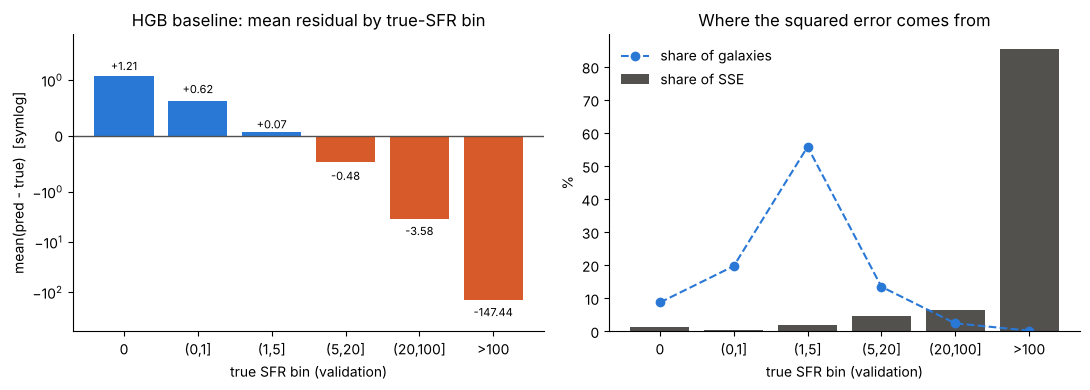

In [39]:
# 그림: 기준선이 어디서 틀리나 — 참 SFR 구간별 평균 잔차(왼쪽)와 SSE 비중(오른쪽). 그림 글자는 영어.
labels = ["0", "(0,1]", "(1,5]", "(5,20]", "(20,100]", ">100"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.bar(labels, baseline_bins["mean_residual"], color=["#2a78d6" if v > 0 else "#d65a2a" for v in baseline_bins["mean_residual"]])
ax.axhline(0, color="#52514e", lw=1)
ax.set_yscale("symlog", linthresh=1)
ax.set_ylim(-600, 8)
ax.set_xlabel("true SFR bin (validation)")
ax.set_ylabel("mean(pred - true)  [symlog]")
ax.set_title("HGB baseline: mean residual by true-SFR bin")
for k, v in enumerate(baseline_bins["mean_residual"]):
    ax.text(k, v * (1.15 if v > 0 else 1.25), f"{v:+.2f}", ha="center", va="bottom" if v > 0 else "top", fontsize=8)
ax = axes[1]
ax.bar(labels, baseline_bins["SSE_share"] * 100, color="#52514e", label="share of SSE")
ax.plot(labels, baseline_bins["n_share"] * 100, "o--", color="#2a78d6", label="share of galaxies")
ax.set_xlabel("true SFR bin (validation)")
ax.set_ylabel("%")
ax.set_title("Where the squared error comes from")
ax.legend(frameon=False)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**무엇을 보여 주나.** 기준선은 작은 SFR을 **과대**, 큰 SFR을 **과소**예측한다. 평균 잔차는 SFR = 0에서 +1.21, (0, 1]에서 +0.62, (20, 100]에서 −3.58, SFR > 100에서 −147.4다. 오른쪽 그림에서 은하의 0.15%(SFR > 100, 61개)가 SSE의 85.5%를 만든다.

**왜.** 제곱 손실 모델은 비슷한 피처를 가진 은하들의 평균 쪽으로 예측을 당긴다. 그래서 0 은하는 주변 양수 은하에 끌려 올라가고, 극단 은하는 내려간다. 트리는 학습에서 본 값의 범위 밖으로 외삽하지 못한다(val 예측 최대 175.6, 참 최대 884.1). 극단 은하는 수가 적고 13개 피처로 구별되지 않는다.

**모델에 주는 결정.** (1) 0 은하의 과대예측은 "0인가"를 따로 모델링해 줄일 수 있다(→ 7절 2단계 모델). (2) 꼬리 과소예측이 RMSE를 지배하므로, 타깃을 압축하는 처리(log1p)는 RMSE에서 불리할 것이라고 실행 전에 예상했다(→ 7절 실험 1). (3) 음수 예측이 19개 있으므로 0으로 자르는 처리를 넣는다. 참값이 0 이상이라 자르면 RMSE는 나빠질 수 없다.

### 6.1 Baseline Interpretation — **STUDENT RESPONSE**

What do the baseline results tell you about the difficulty of the task? Where does the baseline appear to fail?

**Response:**

**과제의 난이도.** 어려운 과제다. 모든 은하에 중앙값을 예측하는 기준선의 val RMSE가 12.35인데, HGB 기준선은 학습을 거쳐도 9.51로 23%만 줄었다(R² 0.39). 반면 MAE는 1.30으로 SFR이 1~5인 보통 은하는 비교적 잘 맞힌다. 이 차이는 극단값 때문이다. RMSE는 오차를 제곱해 평균하므로 큰 오차가 크게 반영되고, 수가 적은 극단 SFR 은하의 오차가 점수를 지배한다. 극단 은하는 학습 데이터에 드물고, 트리 모델은 학습에서 본 값의 범위 밖으로 예측을 늘리지 못하며, 13개 피처로는 극단 은하가 잘 구별되지 않는다. train RMSE 7.32와 val RMSE 9.51의 차이도 꼬리를 일반화하기 어렵다는 것을 보여 준다.

**기준선이 실패하는 곳.** 참 SFR 구간별로 보면 기준선은 작은 SFR을 과대, 큰 SFR을 과소예측한다(평균 잔차: SFR = 0에서 +1.21, (0, 1]에서 +0.62, (20, 100]에서 −3.58, SFR > 100에서 −147.4). 제곱 손실 모델이 비슷한 피처를 가진 은하들의 평균 쪽으로 예측을 당기기 때문이다.
- **긴 꼬리:** 가장 큰 실패다. SFR > 100인 은하 61개(0.15%)가 오차제곱합의 **85.5%**를 차지하고, 이들을 완벽히 맞히면 RMSE가 약 3.6까지 내려간다. 예측 최대값은 175.6인데 참 최대값은 884.1이다. Top 10% 구간의 R²는 0.25다.
- **꺼진 은하:** SFR = 0인 은하 3,610개를 평균 +1.21로 예측한다(SFR = 0 RMSE 3.55). 0이 별도의 과정이라는 것을 반영하지 못한다. 다만 오차제곱합의 1.2%라 공식 점수에는 거의 드러나지 않는다.
- **그 밖:** SFR은 0 이상인데 음수 예측이 19개 있다(최소 −6.54). 또 `max_iter`는 150이지만 early stopping 때문에 실제로는 트리 37개만 쓰였다.

이 실패들을 바탕으로 7절에서 0을 따로 다루는 2단계 모델을 시험하고, 타깃 처리가 꼬리에 주는 영향을 비교했다.

## 7. Preliminary Model / Proposed Method — **STUDENT WORK**

Implement at least one preliminary approach or provide a working prototype of the method you plan to develop. You are free to use conventional ML, neural networks, graph-based methods, ensembles, two-stage models, or other justified approaches.

#### 7절 실험 1 — 같은 HGB, 손실·타깃 처리만 바꾸기 (EDA 3 → "원래 척도 / log1p / 0 분리를 같은 선형 RMSE로 비교")

In [40]:
# 7절 실험 1: 같은 HGB 설정(HGB)에서 손실·타깃 처리만 바꾼다 — 변인 통제. 평가는 공통 분할 val + evaluate_sfr.
preds, models = {}, {}

# (a) 제곱 손실 = 기준선과 같은 모델 (맞히려는 양: E[SFR | x], 공식 지표 RMSE와 같은 양)
models["(a) squared"] = HistGradientBoostingRegressor(**HGB).fit(X_train, y_train)
preds["(a) squared"] = models["(a) squared"].predict(X_val)

# (b) log1p로 학습 후 expm1로 되돌림 (맞히려는 양: exp(E[log(1+SFR)|x]) - 1 ≈ 조건부 중앙값 쪽)
models["(b) log1p"] = HistGradientBoostingRegressor(**HGB).fit(X_train, np.log1p(y_train))
z_hat_val = models["(b) log1p"].predict(X_val)
preds["(b) log1p"] = np.expm1(z_hat_val)

# (b') (b) + Duan smearing 되돌림 보정: 1 + y = exp(z), 훈련 로그 잔차의 exp 평균을 곱한다
resid_log = np.log1p(y_train) - models["(b) log1p"].predict(X_train)
SMEAR = float(np.mean(np.exp(resid_log)))
preds["(b') log1p + smearing"] = np.exp(z_hat_val) * SMEAR - 1

# (c) Poisson 손실 (log 링크, 예측은 항상 양수)
models["(c) poisson"] = HistGradientBoostingRegressor(loss="poisson", **HGB).fit(X_train, y_train)
preds["(c) poisson"] = models["(c) poisson"].predict(X_val)

# (c') Poisson에 트리를 더 준다 / (a') 공정 비교를 위해 제곱 손실에도 같은 큰 설정
BIG = dict(learning_rate=0.05, max_iter=600, max_leaf_nodes=63, random_state=RANDOM_SEED)
models["(c') poisson big"] = HistGradientBoostingRegressor(loss="poisson", **BIG).fit(X_train, y_train)
preds["(c') poisson big"] = models["(c') poisson big"].predict(X_val)
models["(a') squared big"] = HistGradientBoostingRegressor(**BIG).fit(X_train, y_train)
preds["(a') squared big"] = models["(a') squared big"].predict(X_val)

loss_table = pd.concat([evaluate_sfr(y_val, p, k) for k, p in preds.items()], ignore_index=True)
display(loss_table.round(3))

print(f"smearing 계수 {SMEAR:.4f} | 로그 잔차 분산 {resid_log.var():.4f} → 정규 가정 보정 exp(σ²/2) = {np.exp(resid_log.var() / 2):.4f}")
print(f"참 평균(val) {y_val.mean():.3f}")
for k, p in preds.items():
    print(f"  {k:24s} 예측 평균 {p.mean():6.3f} | 최소 {p.min():7.3f} | 최대 {p.max():7.1f} | n_iter_ {models.get(k, models['(b) log1p']).n_iter_}")

,Model,Regime,N,MAE,RMSE,R2
0,(a) squared,All,41688,1.296,9.513,0.388
1,(a) squared,SFR = 0,3610,1.214,3.551,0.000
2,(a) squared,SFR > 0,38078,1.303,9.894,0.390
3,(a) squared,Top 10% SFR,4169,6.583,29.404,0.249
4,(b) log1p,All,41688,1.092,9.810,0.349
5,(b) log1p,SFR = 0,3610,0.264,0.964,0.000
6,(b) log1p,SFR > 0,38078,1.171,10.260,0.344
7,(b) log1p,Top 10% SFR,4169,6.412,30.886,0.171
8,(b') log1p + smearing,All,41688,1.096,9.785,0.353
9,(b') log1p + smearing,SFR = 0,3610,0.300,1.004,0.000


smearing 계수 1.0326 | 로그 잔차 분산 0.0585 → 정규 가정 보정 exp(σ²/2) = 1.0297
참 평균(val) 3.751
  (a) squared              예측 평균  3.654 | 최소  -6.544 | 최대   175.6 | n_iter_ 37
  (b) log1p                예측 평균  3.347 | 최소  -0.297 | 최대   126.3 | n_iter_ 150
  (b') log1p + smearing    예측 평균  3.489 | 최소  -0.274 | 최대   130.4 | n_iter_ 150
  (c) poisson              예측 평균  3.682 | 최소   0.017 | 최대   725.5 | n_iter_ 90
  (c') poisson big         예측 평균  3.603 | 최소   0.014 | 최대   270.6 | n_iter_ 136
  (a') squared big         예측 평균  3.651 | 최소 -10.874 | 최대   180.0 | n_iter_ 61


**결과(같은 설정, val).** All RMSE는 (a) 제곱 9.513 < (b) log1p 9.810 < (c) Poisson 11.379다. MAE와 SFR = 0 줄의 순서는 반대다. (b)가 MAE 1.092, SFR = 0 RMSE 0.964로 가장 좋다. **지표를 바꾸면 승자가 바뀐다.** 판정은 공식 지표인 RMSE로 한다.

**(b) log1p가 RMSE에서 지는 이유.** 로그 척도에서 제곱 손실은 E[log(1+Y)|x]를 맞힌다. Jensen 부등식에 따라 이것을 되돌린 값 exp(E[log(1+Y)|x]) − 1은 E[Y|x]보다 작다. 그래서 예측이 조건부 중앙값 쪽으로 가고 꼬리를 체계적으로 과소예측한다. 예측 평균은 3.347로 참 평균 3.751보다 10.8% 작고, Top 10% RMSE는 30.89다. train 잔차로 Duan smearing 보정(계수 1.033, 정규 가정 보정 1.030과 거의 같음)을 해도 예측 평균은 3.489에 그친다. RMSE는 9.785로 거의 그대로다. 보정 상수가 하나뿐이어서, 로그 잔차의 분산이 x에 따라 다르면(이분산) 꼬리의 편향을 다 고치지 못한다.

**(c) Poisson이 지는 이유.** Poisson deviance는 오차를 대략 (y − μ)²/μ로 잰다. 즉 큰 은하의 **절대** 오차를 RMSE보다 덜 벌한다. 또 log 링크에서는 예측이 곱셈으로 커지므로 꼬리까지 가는 데 트리가 많이 필요하다. 그런데 deviance 기준 early stopping은 90번째 트리에서 멈췄다. 트리를 더 주면(c′: 학습률 0.05, 잎 63, 실제 136개) 9.550으로 같은 큰 설정의 제곱 손실(a′, 9.537)과 같아진다. 즉 패배의 대부분은 최적화 부족이었다. Poisson은 예측이 항상 양수이고 SFR = 0 줄이 좋다(2.02 vs 3.04)는 장점이 있다.

**결정.** 공식 지표가 E[Y|x]를 요구하므로 타깃은 **원래 척도 + 제곱 손실**로 둔다. 0 regime 문제는 손실이 아니라 구조(2단계)로 다룬다.

#### 7절 실험 2 — 2단계(hurdle) 모델 = `FINAL_MODEL` (EDA 1·2 → "0인가"를 따로 배우기)

In [41]:
# 7절: 2단계(hurdle) 모델 — ŷ = P(SFR>0 | x) × E[SFR | SFR>0, x]
# 제곱오차를 최소화하는 예측은 E[SFR|x]이고, 총기대 법칙으로 E[SFR|x] = P(SFR>0|x)·E[SFR|SFR>0,x] (zero-inflated 모형의 (1-π)μ와 같은 식).
# 따라서 "자르기"(P>0.5면 E, 아니면 0)가 아니라 "곱"을 쓴다.
from sklearn.ensemble import HistGradientBoostingClassifier


class TwoStageSFR:
    """분류기 P(y>0|x)와 양수 은하만으로 학습한 회귀기 E[y|y>0,x]를 곱하는 모델."""

    def __init__(self, hgb_params, reg_loss="squared_error", clip_zero=True):
        self.hgb_params = hgb_params
        self.reg_loss = reg_loss
        self.clip_zero = clip_zero

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        pos = y > 0
        self.clf_ = HistGradientBoostingClassifier(**self.hgb_params).fit(X, pos.astype(int))
        self.reg_ = HistGradientBoostingRegressor(loss=self.reg_loss, **self.hgb_params).fit(X[pos], y[pos])
        return self

    def predict_proba_positive(self, X):
        return self.clf_.predict_proba(X)[:, 1]

    def predict_positive_mean(self, X):
        e = self.reg_.predict(X)
        return np.clip(e, 0, None) if self.clip_zero else e  # E[y|y>0] >= 0

    def predict(self, X):
        return self.predict_proba_positive(X) * self.predict_positive_mean(X)


FINAL_MODEL = TwoStageSFR(hgb_params=HGB)  # 두 단계 모두 기준선과 같은 HGB 설정 (변인 통제)

_t0 = time.time()
FINAL_MODEL.fit(X_train, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all()
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")
print(f"n_iter_ — 분류기 {FINAL_MODEL.clf_.n_iter_}, 양수 회귀기 {FINAL_MODEL.reg_.n_iter_}")

Training time: 1.1 s
n_iter_ — 분류기 150, 양수 회귀기 38


In [42]:
# 2단계 모델 진단: 곱 vs 자르기, 양수 회귀기 손실(Poisson) 변형, 분류기 품질·보정
from sklearn.metrics import roc_auc_score, log_loss

p_val = FINAL_MODEL.predict_proba_positive(X_val)
e_val = FINAL_MODEL.predict_positive_mean(X_val)
preds["(d) two-stage P x E"] = VAL_PREDICTIONS
preds["(d-hard) 1[P>0.5] x E"] = np.where(p_val > 0.5, e_val, 0.0)
preds["(d, no clip)"] = p_val * FINAL_MODEL.reg_.predict(X_val)
model_dp = TwoStageSFR(hgb_params=HGB, reg_loss="poisson").fit(X_train, y_train)
preds["(d') two-stage, Poisson reg"] = model_dp.predict(X_val)

keys = ["(a) squared", "(d) two-stage P x E", "(d, no clip)", "(d-hard) 1[P>0.5] x E", "(d') two-stage, Poisson reg"]
display(pd.concat([evaluate_sfr(y_val, preds[k], k) for k in keys], ignore_index=True).round(3))

yv_pos = (y_val.to_numpy() > 0).astype(int)
print(f"분류기 AUC {roc_auc_score(yv_pos, p_val):.4f} | log loss {log_loss(yv_pos, p_val):.4f} "
      f"| 0.1 < p < 0.9인 은하 비율 {((p_val > 0.1) & (p_val < 0.9)).mean():.1%}")
print(f"(d) 예측 평균 {VAL_PREDICTIONS.mean():.3f} vs 참 평균 {y_val.mean():.3f} | 음수 예측 {(VAL_PREDICTIONS < 0).sum()}개")

calib = (pd.DataFrame({"p": p_val, "pos": yv_pos})
         .groupby(pd.cut(p_val, [0, 0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 1.0]), observed=True)
         .agg(n=("pos", "size"), mean_p=("p", "mean"), frac_positive=("pos", "mean")))
print("분류기 보정표 (mean_p ≈ frac_positive이면 확률이 잘 맞는다):")
display(calib.round(3))

,Model,Regime,N,MAE,RMSE,R2
0,(a) squared,All,41688,1.296,9.513,0.388
1,(a) squared,SFR = 0,3610,1.214,3.551,0.000
2,(a) squared,SFR > 0,38078,1.303,9.894,0.390
3,(a) squared,Top 10% SFR,4169,6.583,29.404,0.249
4,(d) two-stage P x E,All,41688,1.240,9.434,0.398
5,(d) two-stage P x E,SFR = 0,3610,0.554,2.913,0.000
6,(d) two-stage P x E,SFR > 0,38078,1.305,9.830,0.398
7,(d) two-stage P x E,Top 10% SFR,4169,6.561,29.149,0.262
8,"(d, no clip)",All,41688,1.241,9.443,0.397
9,"(d, no clip)",SFR = 0,3610,0.556,2.913,0.000


분류기 AUC 0.9945 | log loss 0.0507 | 0.1 < p < 0.9인 은하 비율 6.0%
(d) 예측 평균 3.648 vs 참 평균 3.751 | 음수 예측 0개
분류기 보정표 (mean_p ≈ frac_positive이면 확률이 잘 맞는다):


,n,mean_p,frac_positive
"(0.0, 0.1]",2256,0.039,0.035
"(0.1, 0.3]",984,0.177,0.174
"(0.3, 0.5]",388,0.392,0.371
"(0.5, 0.7]",348,0.602,0.632
"(0.7, 0.9]",761,0.825,0.820
"(0.9, 0.99]",3399,0.964,0.973
"(0.99, 1.0]",33552,0.999,0.999


**결과.** (d) P × E는 All RMSE **9.434**(기준선 9.513), SFR = 0 RMSE **2.913**(3.551), Top 10% 29.149(29.404), 음수 예측 0개다. "곱" 대신 "자르기"(d-hard: P > 0.5면 E, 아니면 0)를 쓰면 All 9.454에 SFR = 0 RMSE가 3.742로 나빠진다. 확실히 0이라고 판단한 은하는 0을 맞히지만, 틀린 은하에서 크게 틀리기 때문이다. 양수 회귀기에 Poisson 손실을 쓰면(d′) 10.373으로 나빠진다. 실험 1의 (c)와 같은 이유다.

**곱과 자르기의 차이가 작은 이유.** 어떤 x에서 상수 c를 예측할 때 기대 제곱오차는 Var(Y|x) + (c − p·e)²다. 따라서 최적값은 c = p·e이고, 자르기는 (1−p)²e² 또는 p²e²만큼 손해를 본다. 분류기는 AUC 0.9945, log loss 0.0507이고 보정표에서 mean_p ≈ frac_positive로 **잘 보정**되어 있다. 그런데 val의 94%가 p < 0.1 또는 p > 0.9인 "확실한" 은하라서, 곱과 자르기는 애매한 나머지 6%에서만 다르다.

**기준선과의 차이가 작은 이유.** 기준선 대비 이득은 오히려 확실한 은하에서 난다. 확실히 꺼진 은하는 p ≈ 0이라 0 근처로 예측되고(기준선은 +1.21), 별을 만드는 은하는 0 은하에 끌려 내려가지 않은 회귀기로 예측된다. 하지만 오차의 약 85%를 만드는 꼬리 은하는 p ≈ 1이라 회귀기가 전부 맡고, 이 회귀기는 기준선과 같은 한계를 가진 HGB다. 그래서 All RMSE가 거의 바뀌지 않는다.

**참고.** 분류기는 `max_iter` 상한 150에 닿았다(`n_iter_` 150). log loss가 계속 조금씩 줄고 있다는 뜻이다. 양수 회귀기는 38개에서 멈췄다. 분류기 트리 수 조정은 최종 보고서 과제로 남긴다.

#### 7절 실험 3 — 모델 구조를 `X_train` 안 5-fold CV로도 비교 (선택은 train 안에서)

In [43]:
# 7절 실험 3: 주요 후보를 5절의 같은 5개 fold(X_train 안)에서도 비교 — val을 보지 않고 고를 수 있었는지 확인.
def fit_predict(kind, Xa, ya, Xb):
    if kind == "(a) squared":
        return HistGradientBoostingRegressor(**HGB).fit(Xa, ya).predict(Xb)
    if kind == "(b) log1p":
        return np.expm1(HistGradientBoostingRegressor(**HGB).fit(Xa, np.log1p(ya)).predict(Xb))
    if kind == "(c) poisson":
        return HistGradientBoostingRegressor(loss="poisson", **HGB).fit(Xa, ya).predict(Xb)
    if kind == "(d) two-stage P x E":
        return TwoStageSFR(hgb_params=HGB).fit(Xa, ya).predict(Xb)
    raise ValueError(kind)

cv_model_rows = []
for kind in ["(a) squared", "(b) log1p", "(c) poisson", "(d) two-stage P x E"]:
    f_all, f_zero, f_le100 = [], [], []
    for tr, te in FOLDS:
        p = fit_predict(kind, Xtr.iloc[tr], ytr.iloc[tr], Xtr.iloc[te])
        yt = ytr.iloc[te].to_numpy()
        f_all.append(rmse(yt, p)); f_zero.append(rmse(yt[yt == 0], p[yt == 0])); f_le100.append(rmse(yt[yt <= 100], p[yt <= 100]))
    cv_model_rows.append({"model": kind, "CV RMSE": np.mean(f_all), "fold SD": np.std(f_all, ddof=1),
                          "fold RMSE": [round(v, 2) for v in f_all],
                          "CV RMSE (SFR=0)": np.mean(f_zero), "CV RMSE (SFR<=100)": np.mean(f_le100)})
cv_models = pd.DataFrame(cv_model_rows)
fold_mat = np.array([r for r in cv_models["fold RMSE"]])
cv_models["(d)보다 나쁜 fold 수"] = [int((fold_mat[i] > fold_mat[3]).sum()) for i in range(len(fold_mat))]
display(cv_models.round(3))

,model,CV RMSE,fold SD,fold RMSE,CV RMSE (SFR=0),CV RMSE (SFR<=100),(d)보다 나쁜 fold 수
0,(a) squared,8.325,3.988,"[14.44, 10.32, 6.01, 5.4, 5.45]",2.722,4.075,1
1,(b) log1p,8.437,4.164,"[14.72, 10.73, 5.76, 5.42, 5.56]",1.194,2.635,2
2,(c) poisson,10.547,3.485,"[14.71, 10.75, 6.86, 13.15, 7.26]",1.884,5.376,5
3,(d) two-stage P x E,8.455,3.841,"[14.24, 10.57, 6.23, 5.55, 5.68]",1.889,3.972,0


**val을 보지 않았어도 같은 결론이었나.** train 안 CV에서도 순서는 val과 같다. (c) Poisson이 10.547로 가장 나쁘다. (a) 8.325, (b) 8.437, (d) 8.455는 fold SD(약 4) 안에서 구별되지 않는다. All RMSE로는 CV가 (d)를 고르지 않는다. (a)가 (d)보다 0.13 낮고, 5개 fold 중 4개에서 (d)가 조금 나쁘다. 반면 꼬리를 뺀 SFR ≤ 100(3.972 vs 4.075)과 SFR = 0(1.889 vs 2.722)에서는 (d)가 (a)보다 좋다. (b)는 이 두 줄에서 가장 좋지만 All에서는 뒤진다.

**결정에 주는 의미.** (d)를 고르는 근거는 "All RMSE가 더 낮아서"가 아니다. 근거는 (1) 공식 지표가 요구하는 E[Y|x]를 그대로 분해한 구조이고, (2) 꼬리가 아닌 영역(0, ≤ 100)에서 CV와 val 모두 일관되게 낫고, (3) All에서는 손해가 구별되지 않는다는 것이다. 7.1의 선택 이유는 이 판단을 따른다.

#### 7절 실험 4 — 기준선과의 차이에 쌍 부트스트랩 95% 구간 붙이기 + EDA 4가 제안한 BH 제외 비교

In [44]:
# 7절 실험 4: 기준선 대비 RMSE 차이의 쌍 부트스트랩 95% 구간 (같은 검증 행을 두 모델에 함께 재표집)
def paired_rmse_ci(pred_a, pred_b, y, B=1000, seed=RANDOM_SEED, chunk=100):
    """RMSE(b) - RMSE(a)의 점추정과 percentile 95% 구간. 재표집 단위 = 검증 은하 한 개."""
    y = np.asarray(y, float)
    ea, eb = (np.asarray(pred_a) - y) ** 2, (np.asarray(pred_b) - y) ** 2
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(B // chunk):
        idx = rng.integers(0, len(y), size=(chunk, len(y)), dtype=np.int32)
        diffs.append(np.sqrt(eb[idx].mean(axis=1)) - np.sqrt(ea[idx].mean(axis=1)))
    diffs = np.concatenate(diffs)
    return float(np.sqrt(eb.mean()) - np.sqrt(ea.mean())), float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))

# 기준선 RMSE 자체가 검증 표본에 따라 얼마나 흔들리나
_rng = np.random.default_rng(RANDOM_SEED)
_e = (baseline_pred - y_val.to_numpy()) ** 2
_boot = np.concatenate([np.sqrt(_e[_rng.integers(0, len(_e), size=(100, len(_e)), dtype=np.int32)].mean(axis=1)) for _ in range(10)])
print(f"기준선 val RMSE {np.sqrt(_e.mean()):.3f}의 부트스트랩: SE {_boot.std(ddof=1):.3f}, 95% [{np.percentile(_boot, 2.5):.2f}, {np.percentile(_boot, 97.5):.2f}]")

# EDA 4의 제안: BH 질량을 빼면 어떻게 되나 (+ 참고로 위치·속도 6열 제외). 기준선 설정 그대로 다시 학습.
POSVEL = [c for c in FINAL_FEATURES if c.startswith(("pos_", "vel_"))]
for name, drop in {"(abl) drop BH": ["log10_BH_mass"], "(abl) drop pos/vel (6)": POSVEL}.items():
    feats = [c for c in FINAL_FEATURES if c not in drop]
    preds[name] = HistGradientBoostingRegressor(**HGB).fit(X_train[feats], y_train).predict(X_val[feats])

ci_rows = []
for name, p in preds.items():
    if name in ["(a) squared", "(d, no clip)"]:
        continue
    d, lo, hi = paired_rmse_ci(baseline_pred, p, y_val)
    ci_rows.append({"model": name, "val RMSE": rmse(y_val, p), "ΔRMSE vs baseline": d, "95% CI low": lo, "95% CI high": hi,
                    "판정": "개선" if hi < 0 else ("악화" if lo > 0 else "동등(구간이 0 포함)")})
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(3))

기준선 val RMSE 9.513의 부트스트랩: SE 1.365, 95% [6.92, 12.31]


,model,val RMSE,ΔRMSE vs baseline,95% CI low,95% CI high,판정
0,(b) log1p,9.810,0.296,-0.113,0.730,동등(구간이 0 포함)
1,(b') log1p + smearing,9.785,0.271,-0.135,0.701,동등(구간이 0 포함)
2,(c) poisson,11.379,1.866,0.280,3.724,악화
3,(c') poisson big,9.550,0.037,-0.429,0.442,동등(구간이 0 포함)
4,(a') squared big,9.537,0.023,-0.129,0.141,동등(구간이 0 포함)
5,(d) two-stage P x E,9.434,-0.079,-0.348,0.184,동등(구간이 0 포함)
6,(d-hard) 1[P>0.5] x E,9.454,-0.059,-0.333,0.209,동등(구간이 0 포함)
7,"(d') two-stage, Poisson reg",10.373,0.860,0.147,1.767,악화
8,(abl) drop BH,9.958,0.445,0.191,0.751,악화
9,(abl) drop pos/vel (6),9.329,-0.184,-0.729,0.392,동등(구간이 0 포함)


**결과.** 기준선 대비 RMSE 차이의 95% 구간이 0을 포함하지 않는 것은 **악화** 셋뿐이다. (c) Poisson +1.87 [+0.28, +3.72], (d′) 2단계 + Poisson 회귀기 +0.86 [+0.15, +1.77], **BH 제외** +0.45 [+0.19, +0.75]. **(d) 2단계 모델은 −0.08 [−0.35, +0.18]로 기준선과 동등**하다. 나머지(log1p, smearing, Poisson big, squared big, 자르기, 위치·속도 제외)도 모두 동등이다.

**EDA와의 연결.** 3절 추가 EDA 4는 "BH는 양수 SFR의 크기 예측 후보이며 BH 제외 비교로 확인한다"고 제안했다. BH 질량을 빼면 All RMSE가 확실히 나빠지고(구간이 0보다 큼), SFR = 0 줄도 3.55 → 4.13으로 나빠진다(아래 요약 표). **BH는 유지한다.** 위치·속도 6열은 빼도 나빠지지 않는다(−0.18, 구간이 0 포함, 경향은 오히려 좋아짐). 그러나 "빼서 개선했다"고 쓸 수는 없다. 피처 선택은 최종 보고서에서 정한다.

**주의.** 이 구간은 같은 val 행을 재표집한 것이라 "이 val 표본에서의 차이"의 불확실성이다. 학습 데이터가 달라질 때의 변동은 포함하지 않는다.

#### 7절 실험 5 — 두 단계가 각각 어느 피처에 기대나 (EDA 1·2·4·5와 맞춰 보기)

,분류기: log loss 증가,분류기 SD,양수 회귀기: RMSE 증가,양수 회귀기 SD,분류기 순위,회귀기 순위
log10_overdensity_plus_1,0.5819,0.0041,-0.0324,0.0155,1,10
log10_halo_mass,0.0749,0.0015,0.0748,0.0020,2,5
log10_main_prog_stellar_mass,0.0216,0.0006,0.0260,0.0012,3,7
log10_mass_ratio,0.0150,0.0008,0.0573,0.0224,4,6
log10_main_prog_mass,0.0109,0.0005,0.7868,0.0092,5,2
log10_stellar_mass,0.0055,0.0003,3.2321,0.0378,6,1
pos_y,0.0049,0.0001,0.0185,0.0794,7,8
pos_x,0.0047,0.0001,0.0860,0.0492,8,4
pos_z,0.0032,0.0001,-0.1000,0.0995,9,12
log10_BH_mass,0.0018,0.0001,0.1623,0.0581,10,3


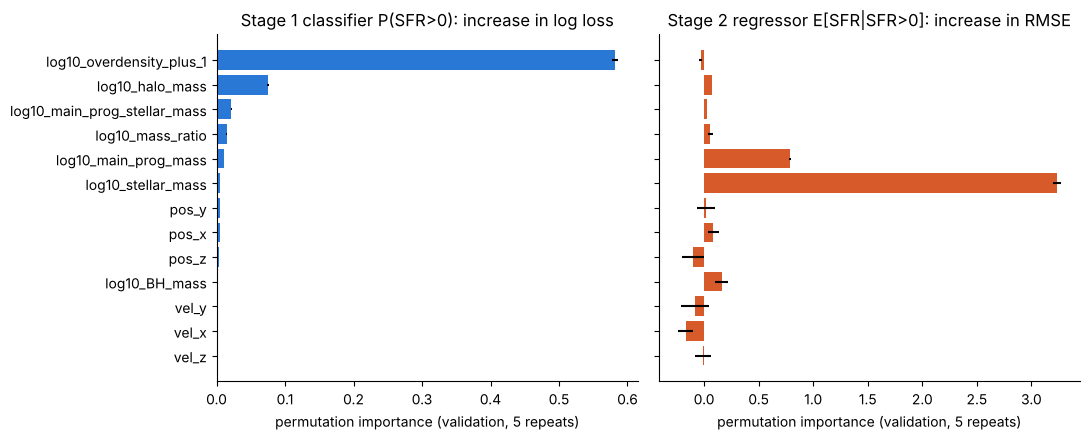

In [45]:
# 7절 실험 5: 2단계 모델의 두 조각이 각각 어떤 피처에 기대는지 — permutation importance (검증 데이터, 5회 반복)
# 해석용이다(모델 선택에 쓰지 않음). 분류기는 log loss 증가, 양수 회귀기는 양수 은하에서의 RMSE 증가로 잰다.
from sklearn.inspection import permutation_importance

imp_clf = permutation_importance(FINAL_MODEL.clf_, X_val, yv_pos, scoring="neg_log_loss",
                                 n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
pos_mask = y_val.to_numpy() > 0
imp_reg = permutation_importance(FINAL_MODEL.reg_, X_val[pos_mask], y_val[pos_mask], scoring="neg_root_mean_squared_error",
                                 n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
importance = pd.DataFrame({
    "분류기: log loss 증가": imp_clf.importances_mean,
    "분류기 SD": imp_clf.importances_std,
    "양수 회귀기: RMSE 증가": imp_reg.importances_mean,
    "양수 회귀기 SD": imp_reg.importances_std,
}, index=FINAL_FEATURES)
importance["분류기 순위"] = importance["분류기: log loss 증가"].rank(ascending=False).astype(int)
importance["회귀기 순위"] = importance["양수 회귀기: RMSE 증가"].rank(ascending=False).astype(int)
display(importance.sort_values("분류기: log loss 증가", ascending=False).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
order = importance.sort_values("분류기: log loss 증가").index
axes[0].barh(order, importance.loc[order, "분류기: log loss 증가"], xerr=importance.loc[order, "분류기 SD"], color="#2a78d6")
axes[0].set_title("Stage 1 classifier P(SFR>0): increase in log loss")
axes[1].barh(order, importance.loc[order, "양수 회귀기: RMSE 증가"], xerr=importance.loc[order, "양수 회귀기 SD"], color="#d65a2a")
axes[1].set_title("Stage 2 regressor E[SFR|SFR>0]: increase in RMSE")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
    a.set_xlabel("permutation importance (validation, 5 repeats)")
plt.tight_layout()
plt.show()

**무엇을 보여 주나.** 두 단계가 **서로 다른 피처**에 기댄다.
- **분류기(꺼졌나)**: 주변 밀도 `log10_overdensity_plus_1`이 압도적이다. 섞으면 log loss가 0.58 늘어나며, 2위인 헤일로 질량(0.075)의 약 8배다.
- **양수 회귀기(얼마나 만드나)**: 항성 질량(섞으면 RMSE +3.23)과 전구체 헤일로 질량(+0.79)이 주로 쓰이고, BH 질량(+0.16)이 그다음이다. 주변 밀도는 회귀기에서는 0(−0.03 ± 0.02)이다.

**EDA와 맞춰 보기.** 3절 EDA 1·2의 "밀도는 SFR = 0과 강하게 연관"이 모델에서도 그대로 나타난다. 그리고 밀도는 "0인가"에만 쓰이고 "얼마나"에는 쓰이지 않는다. EDA 4의 "BH는 0 여부보다 양수 SFR의 크기와 관련"도 같은 방향이다(분류기 10위, 회귀기 3위). EDA 5의 병합 지표 `log10_mass_ratio`는 회귀기에서 작다(+0.06). 병합 은하가 몰려 있는 극단 SFR을 회귀기가 어차피 맞히지 못하기 때문일 수 있다(추정). 위치·속도 6열은 두 단계 모두 거의 0이고, 표준편차보다 작거나 음수다.

**한계.** permutation importance는 "학습된 모델이 그 열에 얼마나 기대나"를 재는 것이지 인과가 아니다. 상관된 질량 피처끼리는 중요도를 나눠 가질 수 있다(예: 항성 질량과 전구체 질량). 해석은 최종 보고서 12절에서 넓힌다.

#### 7절 요약 표

In [46]:
# 7절 요약 표: 공식 지표(All RMSE) + 구간별 지표 + 기준선 대비 구간
order = ["(a) squared", "(b) log1p", "(b') log1p + smearing", "(c) poisson", "(c') poisson big", "(a') squared big",
         "(d) two-stage P x E", "(d-hard) 1[P>0.5] x E", "(d') two-stage, Poisson reg", "(abl) drop BH", "(abl) drop pos/vel (6)"]
rows = []
for k in order:
    t = evaluate_sfr(y_val, preds[k], k).set_index("Regime")
    rows.append({"model": k, "All RMSE": t.loc["All", "RMSE"], "All MAE": t.loc["All", "MAE"], "All R2": t.loc["All", "R2"],
                 "SFR=0 RMSE": t.loc["SFR = 0", "RMSE"], "SFR>0 RMSE": t.loc["SFR > 0", "RMSE"],
                 "Top10% RMSE": t.loc["Top 10% SFR", "RMSE"], "pred mean": preds[k].mean()})
summary = pd.DataFrame(rows).merge(ci_table[["model", "ΔRMSE vs baseline", "95% CI low", "95% CI high", "판정"]], on="model", how="left")
display(summary.round(3))

,model,All RMSE,All MAE,All R2,SFR=0 RMSE,SFR>0 RMSE,Top10% RMSE,pred mean,ΔRMSE vs baseline,95% CI low,95% CI high,판정
0,(a) squared,9.513,1.296,0.388,3.551,9.894,29.404,3.654,NaN,NaN,NaN,NaN
1,(b) log1p,9.810,1.092,0.349,0.964,10.260,30.886,3.347,0.296,-0.113,0.730,동등(구간이 0 포함)
2,(b') log1p + smearing,9.785,1.096,0.353,1.004,10.234,30.799,3.489,0.271,-0.135,0.701,동등(구간이 0 포함)
3,(c) poisson,11.379,1.225,0.125,2.406,11.883,32.078,3.682,1.866,0.280,3.724,악화
4,(c') poisson big,9.550,1.131,0.383,2.021,9.974,29.487,3.603,0.037,-0.429,0.442,동등(구간이 0 포함)
5,(a') squared big,9.537,1.231,0.385,3.035,9.935,29.576,3.651,0.023,-0.129,0.141,동등(구간이 0 포함)
6,(d) two-stage P x E,9.434,1.240,0.398,2.913,9.830,29.149,3.648,-0.079,-0.348,0.184,동등(구간이 0 포함)
7,(d-hard) 1[P>0.5] x E,9.454,1.232,0.396,3.742,9.825,29.117,3.647,-0.059,-0.333,0.209,동등(구간이 0 포함)
8,"(d') two-stage, Poisson reg",10.373,1.174,0.273,2.669,10.823,31.604,3.641,0.860,0.147,1.767,악화
9,(abl) drop BH,9.958,1.566,0.330,4.131,10.342,30.218,3.676,0.445,0.191,0.751,악화


### 7.1 Method Description — **STUDENT RESPONSE**

**Model / method:** 2단계(hurdle) 모델. 예측은 ŷ(x) = P(SFR > 0 | x) × E[SFR | SFR > 0, x]다. 앞의 확률은 HGB 분류기로, 뒤의 기댓값은 SFR > 0인 은하만으로 학습한 HGB 회귀기(제곱 손실)로 추정해 둘을 **곱한다**. 같은 HGB 설정으로 제곱 손실(기준선), log1p 변환, Poisson 손실, "P > 0.5면 E, 아니면 0"으로 자르는 방식 등을 비교했다(val, 기준선 대비 차이와 쌍 부트스트랩 95% 구간).

| 모델 | 타깃 처리 | All RMSE | All MAE | SFR = 0 RMSE | Top 10% RMSE | ΔRMSE [95% 구간] | 판정 |
|---|---|---:|---:|---:|---:|---|---|
| (a) HGB 기준선 | 원래 척도, 제곱 | 9.513 | 1.296 | 3.551 | 29.40 | — | — |
| (b) log1p → expm1 | log1p | 9.810 | **1.092** | **0.964** | 30.89 | +0.30 [−0.11, +0.73] | 동등 |
| (b′) (b) + smearing | log1p, 보정 1.033 | 9.785 | 1.096 | 1.004 | 30.80 | +0.27 [−0.14, +0.70] | 동등 |
| (c) Poisson 손실 | log 링크 | 11.379 | 1.225 | 2.406 | 32.08 | +1.87 [+0.28, +3.72] | **악화** |
| (c′) Poisson, 트리 600·잎 63 | log 링크 | 9.550 | 1.131 | 2.021 | 29.49 | +0.04 [−0.43, +0.44] | 동등 |
| **(d) 2단계 P × E (채택)** | 원래 척도, 제곱 | **9.434** | 1.240 | 2.913 | 29.15 | −0.08 [−0.35, +0.18] | 동등 |
| (d-hard) 1[P > 0.5] × E | 원래 척도, 제곱 | 9.454 | 1.232 | 3.742 | 29.12 | −0.06 [−0.33, +0.21] | 동등 |
| (d′) 2단계, 회귀기 Poisson | log 링크 | 10.373 | 1.174 | 2.669 | 31.60 | +0.86 [+0.15, +1.77] | **악화** |

**Why you chose it:** All RMSE는 기준선과 동등하다(9.434 vs 9.513, 차이의 95% 구간 [−0.35, +0.18]). 그래서 점수 때문이 아니라 다음 이유로 골랐다. 첫째, 기준선의 실패를 줄인다. 꺼진 은하의 과대예측이 줄었고(SFR = 0 RMSE 3.55 → 2.91, train 안 CV에서도 2.72 → 1.89), 물리적으로 불가능한 음수 예측이 19개에서 0개가 되었다. 둘째, 예측을 설명할 수 있다. 분류기는 주변 밀도에 압도적으로 기대고, 양수 회귀기는 밀도를 거의 쓰지 않고 항성 질량에 기댄다(permutation importance). 즉 "밀도가 꺼짐을 정하고, 질량이 만드는 양을 정한다"는 역할 분담이 3절 EDA 1·2의 결과와 일치한다. 또 이 구조는 RMSE가 요구하는 조건부 평균 E[SFR|x]를 P(SFR > 0|x) × E[SFR|SFR > 0, x]로 정확히 나눈 것이라 공식 지표와 같은 목표를 겨냥한다.

**Inputs / engineered features:** 템플릿 기본 13개 피처를 그대로 썼다(`subhalo_id` 제외). 손실과 구조의 효과만 비교하려고 피처 공학은 하지 않았다. 참고로 BH 질량을 빼면 RMSE가 확실히 나빠졌고(+0.45, 95% 구간 [+0.19, +0.75]), 위치·속도 6열은 빼도 차이가 없었다(−0.18, [−0.73, +0.39]). 피처 선택은 최종 보고서에서 정한다.

**Important hyperparameters:** 두 단계 모두 기준선과 같은 HGB 설정이다(learning_rate 0.08, max_leaf_nodes 31, max_iter 150, random_state 42). early stopping이 자동으로 켜지므로 실제 트리 수는 분류기 150개(상한 도달), 양수 회귀기 38개다. train 안 5-fold CV에서 설정 간 차이(≤ 0.2)가 fold 간 흔들림(SD 약 4)보다 훨씬 작아 고를 근거가 없었으므로 기준선 값을 유지했다. 회귀기의 음수 예측은 0으로 자른다. 학습 시간은 약 1.4초(CPU)다.

**Target transformation (if any):** 없음. 원래 척도에서 제곱 손실을 썼다. 비교한 대안은 둘이다. log1p 변환은 로그 척도의 평균을 되돌리면 실제 평균보다 작아져(Jensen 부등식) 예측 평균이 10.8% 작았고, smearing 보정(×1.033)으로도 일부만 회복됐다. 그래서 MAE와 SFR = 0에서는 가장 좋았지만 RMSE에서는 졌다(9.81). Poisson 손실은 큰 은하의 절대 오차를 덜 벌하고 같은 설정에서는 트리가 부족해 RMSE가 가장 나빴다(11.38). 트리를 늘리면 기준선과 동등했다(9.55).

**Current limitations:** 가장 중요한 한계는 2단계 구조가 고친 곳과 점수가 정해지는 곳이 다르다는 점이다. 분류기는 꺼진 은하의 과대예측을 줄였지만 이 은하들은 오차제곱합의 1.2%뿐이다. 반면 오차의 약 85%를 만드는 SFR > 100 은하는 분류기가 거의 확실히 양수로 판단해 회귀기가 전부 맡는데, 이 회귀기는 기준선과 같은 HGB라 같은 한계를 가진다(Top 10% RMSE 29.15 vs 29.40). 그래서 All RMSE는 기준선과 동등하고(차이의 95% 구간 [−0.35, +0.18]) 개선을 주장할 수 없다. 꼬리 은하는 61개뿐이고 트리 모델은 학습 범위 밖으로 예측을 늘리지 못하므로 어느 정도 오차는 피하기 어렵다. 다만 SFR > 100 은하의 89.5%가 병합 후보(3절 추가 EDA 5)라서 피처에 정보가 전혀 없다고 단정할 수는 없다. 그 밖에 분류기가 트리 수 상한에 닿았고, 하이퍼파라미터와 피처를 조정하지 않았으며, 검증 분할이 하나뿐이라 RMSE 자체가 [6.9, 12.3]로 흔들린다.

## 8. Part I — Midterm Summary & Next-Step Plan — **REQUIRED**

Write approximately **200–300 words** summarizing:
1. the most important property of the dataset you discovered;
2. your baseline and preliminary performance;
3. what has and has not worked so far;
4. the main modeling hypothesis you will test before the final submission;
5. concrete next steps.

**Midterm summary:**

**① 가장 중요한 데이터 성질.** 지금까지 발견한 가장 중요한 성질은 극소수의 극단 SFR 은하가 공식 점수를 정한다는 것이다. 검증 데이터에서 SFR > 100인 은하 61개(0.15%)가 기준선 오차제곱합의 85.5%를 차지했고, 가장 좋은 모델들도 이 꼬리를 맞히지 못해 All RMSE가 9.4~9.5에 머물렀다. 대다수 은하를 더 정확히 맞히는 선택지도 있었다. log1p 모델은 MAE가 1.09로 가장 좋았지만(기준선 1.30) 꼬리를 과소예측해 RMSE에서 졌다(9.81). 우리는 공식 지표가 극단값을 크게 반영하는 만큼, 대다수 은하의 정확도를 조금 잃더라도 극단값에 다가가는 방향을 택했다.

**② 기준선과 예비 모델 성능.** 모든 은하에 중앙값을 예측하면 val RMSE가 12.35이고, HGB 기준선은 9.51(MAE 1.30, R² 0.39)이다. 예비 모델인 2단계 모델 P(SFR > 0|x) × E[SFR|SFR > 0, x]는 9.43으로, 차이의 95% 구간 [−0.35, +0.18]이 0을 포함해 기준선과 동등하다.

**③ 된 것과 안 된 것.** 2단계 구조는 꺼진 은하의 과대예측을 줄였고(SFR = 0 RMSE 3.55 → 2.91) 음수 예측을 없앴다(19개 → 0개). 또 분류기는 주변 밀도에, 회귀기는 질량에 기대는 역할 분담을 보였다. BH 질량은 빼면 RMSE가 확실히 나빠져(+0.45) 유지한다. 반면 log1p 변환은 꼬리를 과소예측해 RMSE에서 졌고, Poisson 손실은 같은 설정에서 가장 나빴다(11.38). 어떤 방법도 꼬리 오차는 줄이지 못했다.

**④ 핵심 가설.** 최종 보고서까지 시험할 핵심 가설은 "병합 정보가 극단 SFR을 설명한다"는 것이다. 학습 데이터에서 SFR > 100인 은하의 89.5%가 병합 후보였지만, 현재 양수 회귀기는 병합 지표에 거의 기대지 않는다.

**⑤ 다음 단계.** (1) 현재 모델의 꼬리 오차가 병합 은하에 몰려 있는지 확인하고, 병합 정보로 SFR > 100 은하를 가려내는 꼬리 분류기를 만들어 AUC와 보정을 본다. (2) 신호가 있으면 양수 은하를 보통과 꼬리로 나눠 따로 배우고 확률로 섞는 모델을 만들어 2단계 모델과 쌍 부트스트랩 구간으로 비교한다. 신호가 없으면 그 결과를 그대로 보고한다. (3) 예측과 함께 불확실성(예측 구간)을 내서 극단값에서 모델이 틀릴 가능성을 표시한다. (4) 상한에 닿은 분류기의 트리 수를 train 안 CV로 조정한다. (5) 위치·속도 6열을 빼거나 좌표로 만든 환경 피처(이웃 은하 수 등)로 대체하는 경우를 비교해 피처 선택을 확정한다.

### Midterm submission checklist
- [x] Participant/team information is complete.
- [x] Problem and objective are explained.
- [x] Data quality and EDA are documented.
- [x] Preprocessing choices are justified.
- [x] Validation strategy is explained.
- [x] Required baselines run successfully.
- [x] Preliminary method/results are included.
- [x] Midterm summary and next-step plan are complete.
- [x] Notebook runs in order without relying on hidden state.

---
# Part II — Final Report

Continue from Part I in this **same notebook**. You may improve your earlier analysis, but do not delete Part I. Part II should document your final method, experiments, quantitative results, failure modes, astrophysical interpretation, and reproducibility information.

## 9. Final Modeling & Experiments — **STUDENT WORK**

Present the final modeling pipeline and the experiments that led to it. Your report should make clear **what changed from the midterm and why**. Do not include every failed trial; include experiments that materially informed the final design.

### 9.1 Changes Since Midterm — **STUDENT RESPONSE**

**방향이 바뀐 이유.** 중간 보고서(8절)는 선형 SFR의 RMSE를 기준으로 썼다. 당시에는 SFR > 100인 검증 은하 61개(0.15%)가 기준선 오차제곱합의 85.5%를 차지했기 때문에, 극단 SFR 꼬리를 맞히는 것을 다음 과제로 삼았다. 이후 조교 FAQ Q6에서 1차 평가 지표가 **로그 SFR 공간의 RMSE**로 확인됐다. 로그 공간에서는 같은 61개가 최종 모델 오차제곱합의 5.7%에 그치고, 대다수 은하의 크기 예측과 SFR = 0 판정이 점수를 좌우한다. 그래서 우선순위를 ① 로그 공간의 타깃, ② 0 판정을 돕는 환경 정보, ③ 크기 예측을 돕는 질량 성장 정보로 옮겼다. 로그 변환의 offset은 공지되지 않아 log10(SFR + 1)로 가정했다(13.1절).

**8절 계획의 결과.**

| 8절의 계획 | 결과 |
|---|---|
| 핵심 가설: 병합 정보가 극단 SFR을 설명한다 | **연관은 재확인됐지만 크기를 설명하지는 못했다.** SFR > 100인 검증 은하의 90.2%(61개 중 55개)가 병합 후보였다(양수 은하 전체 17.1%). 그러나 병합 표시와 병합 × 성장 피처를 넣은 최종 모델도 이 은하들을 평균 −0.40 dex 과소예측했고, 병합 후보(−0.39)와 비후보(−0.43)의 차이도 작았다. 회귀기는 병합 피처를 거의 쓰지 않았다(12절). 병합 여부는 "높은 SFR이 가능한 은하"는 알려 주지만 "얼마나 높은가"는 정하지 못한다. |
| (1)(2) 꼬리 분류기, 양수 은하를 보통·꼬리로 나눠 확률로 섞는 모델 | 두 번 시험했고 두 번 다 채택하지 않았다. ① SFR 30을 경계로 나눈 모델은 25-fold에서 −0.0003 dex, 20/25로 미리 정한 규칙의 '경계'였다. ② 팀원이 46개 입력에서 0/보통/꼬리 구조, 꼬리 전용 LightGBM, 극단값 가중치, 두 꼬리 예측의 50:50 혼합까지 시험했다. 같은 46개 입력의 두 단계 모델과 비교하면 전체 점수는 사실상 같고(+0.00002 dex), 꼬리 오차는 오히려 컸다(9.2 보조 (4)). |
| (3) 예측 구간 | 수행하지 못했다(13.1절). |
| (4) 분류기 트리 수 조정 | 상한 150 → 400. 이후 조기 종료를 끄고 400개를 모두 학습하는 설정이 가장 좋았다. |
| (5) 위치·속도 6열의 처리 | 원래 위치·속도 6열은 입력에 그대로 두고, 이를 이용한 환경 요약 17개(이웃 밀도, FoF 그룹, 가장 가까운 거대 헤일로까지의 거리 등)를 더했다. 0 판정에서 크게 기여했다. 이후 가장 가까운 이웃 은하 3개의 거리·질량비·상대 속력 6개도 더했다. 팀원 피처 탐색에서 위치·속도 열을 빼는 경우도 비교했지만 선택되지 않았다. |

**바뀐 것.** 효과는 학습 데이터 내부의 교차검증에서 같은 분할의 짝 차이로 쟀고, 검증셋은 쓰지 않았다. 구조·피처·문턱은 5-fold × 시드 5(25개 분할), 학습기는 5-fold(시드 42, 5개 분할), 추가 피처는 5-fold × 시드 42·7(10개 분할)에서 비교했다. 판단 규칙은 실험 전에 정했다: 평균 차이가 음수이고 22/25 이상 분할에서 나아지면 채택, 19~21이면 '경계'로 보고 단순한 쪽을 남긴다.

| Change | Motivation | Effect on validation performance / understanding |
|---|---|---|
| 1단계 분류기에 환경 요약 17개 | EDA 1·2에서 주변 밀도가 SFR = 0 여부를 강하게 갈랐다. FAQ Q1·Q2가 위치·속도로 만든 환경 피처를 허용했다 | 선형 기준선 0.1467 → 환경 분류기를 쓴 선형 두 단계 0.1285 dex (구조 변경 포함). 0 은하의 오차가 0.303 → 0.192로 가장 크게 줄었다 |
| 양수 회귀의 타깃을 log10(SFR + 1)로 | FAQ Q6의 로그 평가. 로그 RMSE를 최소화하는 예측은 로그 공간의 조건부 평균이다 | **−0.0246 dex, 25/25** (가장 큰 개선) |
| 양수 회귀기에도 환경 요약 17개 | 위성·중심 구분이 SFR 크기에도 정보가 있는지 확인 | −0.0004 dex, 22/25 |
| 트리 상한 150 → 400 (분류기, 회귀기) | 중간 보고서에서 분류기가 상한에 닿았다 | 각각 −0.0003, −0.0004 dex, 22/25 |
| 질량 성장·비율 4개 (두 단계 모두) | 전구체 대비 질량 증가는 최근 별 생성의 누적 흔적이다 | −0.0064 dex, 25/25 (아래 0 문턱 변경 포함) |
| P(SFR = 0) ≥ 0.9이면 정확히 0 출력 | SFR = 0은 연속 분포의 끝이 아니라 이산 상태다. 모델이 "꺼졌다"를 말할 수 있게 한다 | +0.00002 dex, 19/25 악화. 미리 정한 악화 기준(22/25)에 못 미쳐 채택했다 |
| 학습기: 조기 종료 → 트리 400개 고정 | 조기 종료는 학습 행의 10%를 떼어 멈출 시점을 정한다 | 5-fold에서 0.096619 → **0.095340 dex, 5/5** (알고리즘 비교, 9.2 보조 (3)) |
| 추가 피처 12개 (팀원 피처 탐색) | 성장의 의미가 질량에 따라 다르고, 병합 중인 은하와 바로 옆 동반 은하의 정보가 꼬리와 꺼짐에 관련될 수 있다 | 같은 두 단계 구조에서 **−0.0019 dex, 10/10 fold** (9.2 보조 (4)). 검증셋에서도 −0.0013 |
| (미채택) 양수 은하의 꼬리 분리 | 중간 보고서의 핵심 가설 | 25-fold −0.0003 dex(20/25, 경계). 46개 입력에서도 두 단계보다 낫지 않았다 |

**Final modeling rationale:** 최종 모델은 "꺼졌는가"와 "켜져 있다면 얼마나 만드는가"를 따로 배운다. 두 질문이 서로 다른 물리량에 기대기 때문이다. 0 여부는 주변 환경이, 양수 SFR의 크기는 질량과 성장 이력이 주로 정한다(12절). 같은 입력에서 두 단계 구조는 세 알고리즘(HGB·LightGBM·CatBoost) 모두에서 단일 로그 회귀보다 5/5 분할 낮은 오차를 냈다. 반면 양수 은하를 한 번 더 나누는 구조는 두 번의 시험에서 이점이 없었다. 그래서 두 단계 구조를 유지하고, 학습기는 미리 정한 순위 기준의 1위인 HGB 400개 고정, 입력은 46개로 정했다.

### 9.2 Final Model Code

Place the complete code needed to train your final model and generate validation predictions below.

In [47]:
# 수정본 실행 시작: 실제 환경·입력·순서 기록. 패키지 설치나 네트워크 접근은 없다.
import sys, hashlib, importlib.metadata
warnings.resetwarnings()
warnings.simplefilter("default")  # 경고를 표시한다. 비어 있는 필터 목록에 대한 sklearn 병렬 설정 경고도 피한다.
REVISION_RUNTIME = {
    "python": sys.version,
    "matplotlib_backend": plt.get_backend(),
    "packages": {name: importlib.metadata.version(name) for name in
                 ("numpy", "pandas", "scipy", "scikit-learn", "matplotlib")},
    "csv_name": DATA_PATH.name,
    "csv_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "execution_order": "처음부터 Part I → 환경 → 최종 모델/입력계약 → 반복 교차검증 25개 분할 → 대조 실험 5개 분할 → 비교/진단 → RESULTS",
    "selection_policy": "학습 내부 CV의 사전 고정 순위(평균 로그 RMSE)로 구조·피처·알고리즘을 고른다. 검증셋은 보고에만 쓴다.",
}
print(json.dumps(REVISION_RUNTIME, ensure_ascii=False, indent=2))

{
  "python": "3.13.18 (main, Oct 26 2026, 14:08:19) [Clang 23.1.3 ]",
  "matplotlib_backend": "module://matplotlib_inline.backend_inline",
  "packages": {
    "numpy": "2.5.4",
    "pandas": "3.1.1",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2"
  },
  "csv_name": "Galaxy Features with Position and Velocity for Star Formation Rate Prediction.csv",
  "csv_sha256": "ae4eef8fce45b909c5e9af3639721c51edff0f372c5e75cbf1afd36798408806",
  "execution_order": "처음부터 Part I → 환경 → 최종 모델/입력계약 → 반복 교차검증 25개 분할 → 대조 실험 5개 분할 → 비교/진단 → RESULTS",
  "selection_policy": "학습 내부 CV의 사전 고정 순위(평균 로그 RMSE)로 구조·피처·알고리즘을 고른다. 검증셋은 보고에만 쓴다."
}


In [48]:
# 9.2 최종 모델 코드 — (1) 위치·속도에서 환경 피처를 만든다 (타깃 미사용, 전체 은하의 기하만 사용)
# 좌표 자체는 은하의 성질이 아니다. 천문학의 표준 환경 변수(이웃 밀도, FoF 그룹의 중심/위성과 호스트 질량,
# 가장 가까운 거대 헤일로까지의 거리 r/R200과 상대 속도 |Δv|/V200)로 바꿔 쓴다. 자세한 EDA는 work/조장/2026-11-07_위치속도_환경EDA.md.
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

BOX_SIZE = 200.0        # 수치 상자 크기 가정: pos_* 범위와 부합; 단위/스냅샷은 미확정
RHO_CRIT = 2.775e11     # h^2 Msun / Mpc^3
G_KMS = 4.30091e-9      # Mpc km^2 s^-2 Msun^-1


def build_environment_features(frame, box=BOX_SIZE, fof_b=0.2, host_thresholds=(13.5, 14.0)):
    """pos_*, vel_*, log10_halo_mass, log10_stellar_mass만 사용한다. frame과 같은 index의 DataFrame을 돌려준다."""
    pos = frame[["pos_x", "pos_y", "pos_z"]].to_numpy() % box          # 주기 경계 상자 [0, box)
    vel = frame[["vel_x", "vel_y", "vel_z"]].to_numpy()
    mh = frame["log10_halo_mass"].to_numpy()
    n = len(frame)
    tree = cKDTree(pos, boxsize=box)
    out = {}
    # (a) 이웃 밀도: k번째 이웃 거리 밀도(헤일로 안쪽 척도), 고정 반경 이웃 수(더 큰 척도)
    d, _ = tree.query(pos, k=11)
    out["log_rho_5nn"] = np.log10(5 / (4 / 3 * np.pi * d[:, 5] ** 3))
    out["log_rho_10nn"] = np.log10(10 / (4 / 3 * np.pi * d[:, 10] ** 3))
    for r in (1.0, 2.0, 5.0):
        out[f"log1p_N_r{int(r)}"] = np.log1p(tree.query_ball_point(pos, r, return_length=True) - 1)
    # (b) 가장 가까운 거대 헤일로: 거리, r/R200, |Δv|/V200, 호스트 질량
    r200 = lambda logm: (3 * 10 ** logm / (4 * np.pi * 200 * RHO_CRIT)) ** (1 / 3)   # h^-1 Mpc
    v200 = lambda logm: np.sqrt(G_KMS * 10 ** logm / r200(logm))                      # km/s
    for thr in host_thresholds:
        sel = np.where(mh >= thr)[0]
        dist, j = cKDTree(pos[sel], boxsize=box).query(pos, k=1)
        hj = sel[j]
        dv = np.sqrt(((vel - vel[hj]) ** 2).sum(axis=1))
        tag = f"{thr:g}"
        out[f"dist_host{tag}"] = dist
        out[f"r_over_R200_{tag}"] = dist / r200(mh[hj])
        out[f"v_over_V200_{tag}"] = dv / v200(mh[hj])
        if thr == host_thresholds[0]:
            out[f"host_logm_{tag}"] = mh[hj]
    # (c) friends-of-friends 그룹 (Davis et al. 1985): 연결 길이 = b × 평균 간격
    link = fof_b * box / n ** (1 / 3)
    pairs = tree.query_pairs(link, output_type="ndarray")
    _, lab = connected_components(coo_matrix((np.ones(len(pairs)), (pairs[:, 0], pairs[:, 1])), shape=(n, n)), directed=False)
    rich = np.bincount(lab)[lab]
    gmax = pd.Series(mh).groupby(lab).transform("max").to_numpy()
    vmean = pd.DataFrame(vel).groupby(lab).transform("mean").to_numpy()
    dv_grp = np.sqrt(((vel - vmean) ** 2).sum(axis=1))
    dv_grp[rich == 1] = np.nan                                         # 고립 은하는 정의 불가 (HGB는 NaN 처리 가능)
    out["fof_log_richness"] = np.log(rich)
    out["fof_is_central"] = (mh >= gmax - 1e-9).astype(float)          # 그룹 질량 최대를 대리 중심으로 정의; 동률 여러 개 가능
    out["fof_group_max_logm"] = gmax                                   # 호스트 헤일로 질량의 대리
    out["fof_dv_group"] = dv_grp
    # (d) 조석 박탈의 대리
    out["halo_minus_stellar"] = mh - frame["log10_stellar_mass"].to_numpy()
    return pd.DataFrame(out, index=frame.index)


def build_mass_history_features(frame):
    """주어진 질량 열의 차이 4개 (트리는 한 번에 열 하나로만 나눠 차이를 스스로 만들기 어렵다). 타깃 미사용.
    센티널 후보(6.0 등; 공식 의미 미확정)은 그대로 둔다 — 원래 열도 입력에 남아 트리가 따로 가를 수 있다."""
    return pd.DataFrame({
        "dlogMs_growth": frame["log10_stellar_mass"] - frame["log10_main_prog_stellar_mass"],    # 무차원 누적 항성 질량비; 센티널 후보 별도 진단
        "dlogMh_growth": frame["log10_halo_mass"] - frame["log10_main_prog_mass"],               # 무차원 누적 헤일로 질량비
        "bh_to_star": frame["log10_BH_mass"] - frame["log10_stellar_mass"],                      # 블랙홀 상대 질량; 피드백 인과를 직접 측정하지 않음
        "prog_star_to_halo": frame["log10_main_prog_stellar_mass"] - frame["log10_main_prog_mass"],  # 전구체의 항성/헤일로 질량비
    }, index=frame.index)


_t0 = time.time()
_env_order = df[FINAL_FEATURES].sort_values(FINAL_FEATURES, kind="mergesort", na_position="last").index
ENV = build_environment_features(df.loc[_env_order]).reindex(df.index)
ENV_FEATURES = list(ENV.columns)
print(f"환경 피처 {len(ENV_FEATURES)}개, 계산 {time.time() - _t0:.1f} s")
print(ENV_FEATURES)
assert not set(ENV_FEATURES) & set(FINAL_FEATURES)

# 공통 분할의 행은 그대로, 열만 덧붙인다 (index로 결합). 검증 은하의 타깃은 어디에도 쓰이지 않는다.
MASS = build_mass_history_features(df)
MASS_FEATURES = list(MASS.columns)
X_train_env = X_train.join(ENV).join(MASS)
X_val_env = X_val.join(ENV).join(MASS)
assert list(X_train_env.columns) == FINAL_FEATURES + ENV_FEATURES + MASS_FEATURES and len(X_train_env) == len(X_train)

F30 = FINAL_FEATURES + ENV_FEATURES             # 원래 13개 + 환경 17개
CLF_FEATURES = F30 + MASS_FEATURES              # 1단계 분류기 P(SFR>0|x): 30개 + 질량 성장·비율 4개 = 34개
REG_FEATURES = F30 + MASS_FEATURES              # 2단계 로그 회귀기: 같은 34개
# (3) 팀원 피처 탐색에서 고른 추가 피처 12개 (work/팀원/sfr_experiments_20261113/outputs/feature_search). 모두 입력만 쓰고 타깃은 쓰지 않는다.
def build_companion_features(frame, box=BOX_SIZE):
    """가장 가까운 다른 은하 3개(주기 경계). 행 순서는 원래 13개 열의 사전순으로 고정한다."""
    raw = frame[FINAL_FEATURES]
    ordered = raw.loc[raw.sort_values(FINAL_FEATURES, kind="mergesort", na_position="last").index]
    pos = ordered[["pos_x", "pos_y", "pos_z"]].to_numpy() % box
    dist, nbr = cKDTree(pos, boxsize=box).query(pos, k=4)
    assert np.array_equal(nbr[:, 0], np.arange(len(pos))), "자기 자신이 첫 이웃이어야 한다(위치 중복 없음)"
    nbr, dist = nbr[:, 1:], dist[:, 1:]
    vel = ordered[["vel_x", "vel_y", "vel_z"]].to_numpy()
    ms = ordered["log10_stellar_mass"].to_numpy()
    speed = np.linalg.norm(vel[nbr] - vel[:, None, :], axis=2)
    ratio = ms[nbr] - ms[:, None]
    r200_self = (3 * 10.0 ** ordered["log10_halo_mass"].to_numpy() / (4 * np.pi * 200 * RHO_CRIT)) ** (1 / 3)
    return pd.DataFrame({"nn_log_distance": np.log10(dist[:, 0]), "nn_log_stellar_mass_ratio": ratio[:, 0],
                         "nn_relative_speed": speed[:, 0], "nn_r_over_primary_R200": dist[:, 0] / r200_self,
                         "nn3_max_log_stellar_mass_ratio": ratio.max(axis=1), "nn3_min_relative_speed": speed.min(axis=1)},
                        index=ordered.index).reindex(frame.index)


class ExtraFeatures:
    """질량×성장, 병합×성장 3개, 같은 항성 질량대 대비 성장·BH 잔차 2개를 만든다.
    잔차의 기준 곡선(항성 질량 20분위 구간 평균의 선형 보간)은 fit에 준 학습 입력으로만 정한다."""

    @staticmethod
    def _curve(mass, value):
        edges = np.unique(np.quantile(mass, np.linspace(0, 1, 21)[1:-1]))
        g = np.searchsorted(edges, mass, side="right")
        return (np.array([np.median(mass[g == k]) for k in np.unique(g)]), np.array([value[g == k].mean() for k in np.unique(g)]))

    def fit(self, X):
        m = X["log10_stellar_mass"].to_numpy()
        self.growth_curve_ = self._curve(m, X["dlogMs_growth"].to_numpy())
        self.bh_curve_ = self._curve(m, X["log10_BH_mass"].to_numpy())
        return self

    def transform(self, X):
        out = X.copy()
        m, g, r = X["log10_stellar_mass"].to_numpy(), X["dlogMs_growth"].to_numpy(), X["log10_mass_ratio"].to_numpy()
        out["mass_growth_product"] = (m - 10.0) * g
        out["merger_flag"] = (r > -6.0).astype(float)                       # EDA 5의 병합 후보 기준
        out["merger_growth_product"] = (r > -6.0) * g
        out["merger_strength_growth_product"] = np.maximum(r + 6.0, 0.0) * g
        out["stellar_growth_residual_at_mass"] = g - np.interp(m, *self.growth_curve_)
        out["bh_residual_at_stellar_mass"] = X["log10_BH_mass"].to_numpy() - np.interp(m, *self.bh_curve_)
        return out


COMP = build_companion_features(df)
COMPANION_FEATURES = list(COMP.columns)
EXTRA_FEATURES = ["mass_growth_product", "merger_flag", "merger_growth_product", "merger_strength_growth_product",
                  "stellar_growth_residual_at_mass", "bh_residual_at_stellar_mass"] + COMPANION_FEATURES
EXTRA = ExtraFeatures().fit(X_train_env)                 # 기준 곡선은 학습 분할의 입력으로만
X_train_env = EXTRA.transform(X_train_env.join(COMP))
X_val_env = EXTRA.transform(X_val_env.join(COMP))
FINAL_COLS = CLF_FEATURES + EXTRA_FEATURES               # 최종 모델의 46개 입력 (두 단계 공통)
print(f"추가 피처 {len(EXTRA_FEATURES)}개 → 최종 입력 {len(FINAL_COLS)}개")
FINAL_HGB = {**HGB, "max_iter": 400}            # 트리 상한 400, 조기 종료는 sklearn 기본(auto). 9.2 보조의 25-fold 선택 이력에서 쓴 설정
HGB_FIXED400 = {**HGB, "max_iter": 400, "early_stopping": False}   # 최종 모델: 두 단계 모두 트리 400개를 끝까지 학습 (알고리즘 비교의 1위 설정)

환경 피처 17개, 계산 4.5 s
['log_rho_5nn', 'log_rho_10nn', 'log1p_N_r1', 'log1p_N_r2', 'log1p_N_r5', 'dist_host13.5', 'r_over_R200_13.5', 'v_over_V200_13.5', 'host_logm_13.5', 'dist_host14', 'r_over_R200_14', 'v_over_V200_14', 'fof_log_richness', 'fof_is_central', 'fof_group_max_logm', 'fof_dv_group', 'halo_minus_stellar']


추가 피처 12개 → 최종 입력 46개


In [49]:
# 9.2 최종 모델 코드 — (2) 로그 공간의 2단계 모델
# 1차 평가 지표가 로그 SFR 공간의 RMSE로 확인됐다(조교 FAQ Q6, 2026-11-11). 로그 RMSE를 최소화하는 예측은
# 조건부 평균 E[z | x] (z = 로그로 바꾼 SFR)이고, 총기대 법칙으로
#     E[z | x] = P(SFR > 0 | x) · E[z | SFR > 0, x] + (1 − P(SFR > 0 | x)) · z(0).
# 그래서 1단계 분류기는 그대로 두고 2단계 회귀기의 타깃만 z(SFR)로 바꾸며, 두 단계를 로그 공간에서 합친다.
# 공지에 SFR = 0의 로그 처리가 없어 z(SFR) = log10(SFR + LOG_EPS)로 두고 LOG_EPS = 1(= log10(1 + SFR))을 기본으로 쓴다.
# 정의가 확인되면 LOG_EPS와 학습·평가를 맞춰 전체 재실행하고, train 내부에서 문턱도 재검토해야 한다.
# 0.9는 D1에서 고른 값으로 다른 offset에서 최적임을 보장하지 않는다. 전달 척도는 미확정이며 여기서는 선형 SFR로 반환한다.
LOG_EPS = 1.0
# 0일 확률 P(SFR = 0 | x) = 1 − p가 ZERO_THRESHOLD 이상이면 SFR = 0을 그대로 낸다(그 밖은 위 기대값). 문턱은 학습 분할 안
# 25-fold에서 '악화 판정이 아닌 가장 낮은 문턱'으로 골랐다(후보 0.5·0.7·0.8·0.9·0.95·0.99).
# 0.9는 34개 피처 모델에서 평균 +0.0000193 dex, 19/25 악화의 경계 후보다.
# 30개 피처 모델에서는 0.8, 34개 피처 모델에서는 같은 규칙으로 0.9였다.
ZERO_THRESHOLD = 0.9


def to_log(sfr, eps=LOG_EPS):
    return np.log10(np.asarray(sfr, dtype=float) + eps)


def from_log(z, eps=LOG_EPS):
    return np.clip(10 ** np.asarray(z, dtype=float) - eps, 0, None)


def log_rmse(y_true, pred, eps):
    """선형 SFR 예측을 0 이상 절단 후 같은 offset으로 평가한다. eps는 반드시 명시한다."""
    import math
    if not math.isfinite(eps) or eps <= 0:
        raise ValueError("eps must be finite and positive")
    truth, prediction = list(y_true), list(pred)
    if not truth or len(truth) != len(prediction):
        raise ValueError("nonempty matched arrays required")
    if any(not math.isfinite(float(v)) or v < 0 for v in truth):
        raise ValueError("true SFR must be finite and nonnegative")
    if any(not math.isfinite(float(v)) for v in prediction):
        raise ValueError("predictions must be finite")
    return math.sqrt(math.fsum((math.log10(float(t) + eps) - math.log10(max(float(p), 0.0) + eps)) ** 2
                              for t, p in zip(truth, prediction)) / len(truth))


class TwoStageLogSFR:
    """ẑ(x) = P(SFR>0|x)·E[z|SFR>0,x] + (1 − P)·z(0). 두 단계가 서로 다른 피처 열을 쓸 수 있다. predict는 선형 SFR.
    zero_threshold가 있으면 P(SFR=0|x) ≥ zero_threshold인 은하는 z(0), 즉 SFR = 0을 그대로 낸다."""

    def __init__(self, hgb_params, clf_cols, reg_cols, eps=LOG_EPS, clf_params=None, zero_threshold=None):
        self.hgb_params, self.clf_cols, self.reg_cols, self.eps = hgb_params, list(clf_cols), list(reg_cols), eps
        self.zero_threshold = zero_threshold
        self.clf_params = hgb_params if clf_params is None else clf_params

    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        pos = y > 0
        self.clf_ = HistGradientBoostingClassifier(**self.clf_params).fit(X[self.clf_cols], pos.astype(int))
        self.reg_ = HistGradientBoostingRegressor(**self.hgb_params).fit(X.loc[pos, self.reg_cols], to_log(y[pos], self.eps))
        return self

    def predict_proba_positive(self, X):
        return self.clf_.predict_proba(X[self.clf_cols])[:, 1]

    def predict_log_positive(self, X):
        return self.reg_.predict(X[self.reg_cols])

    def predict_log(self, X):
        p = self.predict_proba_positive(X)
        z0 = float(to_log(0.0, self.eps))
        z = p * self.predict_log_positive(X) + (1 - p) * z0
        return z if self.zero_threshold is None else np.where(1 - p >= self.zero_threshold, z0, z)

    def predict(self, X):
        return from_log(self.predict_log(X), self.eps)


print("실행 설정:", {"algorithm": "HistGradientBoosting (sklearn)", "LOG_EPS": LOG_EPS,
                  "ZERO_THRESHOLD": ZERO_THRESHOLD, "HGB": HGB_FIXED400,
                  "features (both stages)": FINAL_COLS})
# 두 단계 모두 같은 HGB 설정(트리 400개 고정, 조기 종료 없음)과 같은 46개 입력을 쓴다.
FINAL_MODEL = TwoStageLogSFR(HGB_FIXED400, FINAL_COLS, FINAL_COLS, zero_threshold=ZERO_THRESHOLD)

_t0 = time.time()
FINAL_MODEL.fit(X_train_env, y_train)
FINAL_TRAIN_SECONDS = time.time() - _t0
VAL_LOG_PREDICTIONS = FINAL_MODEL.predict_log(X_val_env)
VAL_PREDICTIONS = FINAL_MODEL.predict(X_val_env)

assert len(VAL_PREDICTIONS) == len(y_val)
assert np.isfinite(VAL_PREDICTIONS).all() and (VAL_PREDICTIONS >= 0).all()
_zero_out = VAL_PREDICTIONS == 0
print(f"Training time: {FINAL_TRAIN_SECONDS:.1f} s")
print(f"n_iter_ — 분류기 {FINAL_MODEL.clf_.n_iter_} (피처 {len(FINAL_COLS)}개), 로그 양수 회귀기 {FINAL_MODEL.reg_.n_iter_} (피처 {len(FINAL_COLS)}개)")
print(f"SFR = 0을 그대로 낸 val 은하 {_zero_out.sum():,}개 (실제 0 은하의 {np.mean(_zero_out[y_val.to_numpy() == 0]):.1%}, SFR > 0인데 0으로 낸 은하 {int((_zero_out & (y_val.to_numpy() > 0)).sum())}개)")
print(f"val 선택 로그 RMSE log10(SFR + {LOG_EPS:g}): {log_rmse(y_val, VAL_PREDICTIONS, LOG_EPS):.6f} dex | 선형 RMSE {rmse(y_val, VAL_PREDICTIONS):.3f}")
assert FINAL_MODEL.clf_.n_iter_ == FINAL_MODEL.reg_.n_iter_ == 400


실행 설정: {'algorithm': 'HistGradientBoosting (sklearn)', 'LOG_EPS': 1.0, 'ZERO_THRESHOLD': 0.9, 'HGB': {'learning_rate': 0.08, 'max_iter': 400, 'max_leaf_nodes': 31, 'random_state': 42, 'early_stopping': False}, 'features (both stages)': ['log10_halo_mass', 'log10_stellar_mass', 'log10_BH_mass', 'log10_main_prog_mass', 'log10_main_prog_stellar_mass', 'log10_mass_ratio', 'log10_overdensity_plus_1', 'pos_x', 'pos_y', 'pos_z', 'vel_x', 'vel_y', 'vel_z', 'log_rho_5nn', 'log_rho_10nn', 'log1p_N_r1', 'log1p_N_r2', 'log1p_N_r5', 'dist_host13.5', 'r_over_R200_13.5', 'v_over_V200_13.5', 'host_logm_13.5', 'dist_host14', 'r_over_R200_14', 'v_over_V200_14', 'fof_log_richness', 'fof_is_central', 'fof_group_max_logm', 'fof_dv_group', 'halo_minus_stellar', 'dlogMs_growth', 'dlogMh_growth', 'bh_to_star', 'prog_star_to_halo', 'mass_growth_product', 'merger_flag', 'merger_growth_product', 'merger_strength_growth_product', 'stellar_growth_residual_at_mass', 'bh_residual_at_stellar_mass', 'nn_log_distance',

Training time: 6.5 s
n_iter_ — 분류기 400 (피처 46개), 로그 양수 회귀기 400 (피처 46개)
SFR = 0을 그대로 낸 val 은하 2,923개 (실제 0 은하의 79.7%, SFR > 0인데 0으로 낸 은하 46개)
val 선택 로그 RMSE log10(SFR + 1): 0.094063 dex | 선형 RMSE 7.759


In [50]:
# 9.2 라벨 없는 표의 입력 계약: 같은 상자의 고유 은하 합집합으로 환경을 계산한다.
def prepare_prediction_union(new_table, reference, *, assume_disjoint=False):
    """겹칠 수 있는 표에는 고유 ID 필수. 같은 ID의 입력이 다르면 조용히 대체하지 않고 거부한다.
    assume_disjoint=True는 ID 없는 표가 완전히 새 은하라는 호출자의 명시적 계약이다.
    배치를 나눌 때도 reference에 전체 질의 은하를 포함해 동일한 합집합을 유지해야 한다."""
    for label, table in (("new_table", new_table), ("reference", reference)):
        missing = set(FINAL_FEATURES) - set(table.columns)
        if missing:
            raise ValueError(f"{label}: missing features {sorted(missing)}")
        if ID_COLUMN in table.columns:
            if table[ID_COLUMN].isna().any() or table[ID_COLUMN].duplicated().any():
                raise ValueError(f"{label}: null/duplicate ID")
        elif len(table) and not assume_disjoint:
            raise ValueError(f"{label}: ID required; disjoint ID-less tables need explicit assume_disjoint=True")
    new = new_table[FINAL_FEATURES].reset_index(drop=True)
    ref = reference[FINAL_FEATURES].copy()
    if ID_COLUMN in new_table.columns and ID_COLUMN in reference.columns:
        ni = new_table.set_index(ID_COLUMN)[FINAL_FEATURES]
        ri = reference.set_index(ID_COLUMN)[FINAL_FEATURES]
        common = ni.index.intersection(ri.index)
        left, right = ni.loc[common], ri.loc[common]
        same = left.eq(right) | (left.isna() & right.isna())
        if not same.to_numpy().all():
            raise ValueError("same ID has different feature values")
        ref = ref.loc[~reference[ID_COLUMN].isin(new_table[ID_COLUMN]).to_numpy()]
    # ID 확인 후 피처의 사전순으로 정렬해 동일 합집합의 행 순서를 고정한다.
    # 최근접 거리가 동률인 경우에도 같은 기준 순서를 사용한다.
    both = pd.concat([ref, new], ignore_index=True)
    order = both.sort_values(FINAL_FEATURES, kind="mergesort", na_position="last").index.to_numpy()
    locations = np.empty(len(both), dtype=int)
    locations[order] = np.arange(len(both))
    return both.iloc[order].reset_index(drop=True), locations[len(ref):]


def predict_sfr(new_table, model=FINAL_MODEL, reference=None, return_log=False, *, assume_disjoint=False):
    """타깃 없는 입력에서 new_table 원래 순서로 반환. ID는 식별·충돌 확인에만 사용한다.
    참고 표 기본값은 df. 평가표 전체를 한 번에 전달하거나 동일 합집합을 reference로 고정한다.
    ID 없는 기존 행을 disjoint로 선언하면 중복을 판별할 수 없으므로 호출자 책임이다."""
    reference = df if reference is None else reference
    both, locations = prepare_prediction_union(new_table, reference, assume_disjoint=assume_disjoint)
    env = build_environment_features(both)
    mass = build_mass_history_features(both)
    X_new = EXTRA.transform(both.join(env).join(mass).join(build_companion_features(both))).iloc[locations]
    return model.predict_log(X_new) if return_log else model.predict(X_new)


_val_table = df.loc[X_val.index].drop(columns=[TARGET])
_check = predict_sfr(_val_table)
assert np.allclose(_check, VAL_PREDICTIONS, rtol=1e-6, atol=1e-9), "validation reproduction failed"
_reversed = predict_sfr(_val_table.iloc[::-1])
assert np.allclose(_reversed[::-1], _check, rtol=1e-6, atol=1e-9)
# 동일 전체 합집합을 참고로 고정한 분할 배치 두 개를 검사한다.
_cut = len(_val_table) // 2
_batched = np.concatenate([predict_sfr(_val_table.iloc[:_cut]), predict_sfr(_val_table.iloc[_cut:])])
assert np.allclose(_batched, _check, rtol=1e-6, atol=1e-9)


def expect_input_error(table, reference=None, **kwargs):
    try:
        prepare_prediction_union(table, df if reference is None else reference, **kwargs)
    except ValueError:
        return
    raise AssertionError("invalid input was accepted")


expect_input_error(pd.concat([_val_table.iloc[:1], _val_table.iloc[:1]]))
expect_input_error(_val_table.drop(columns=[ID_COLUMN]))
_null = _val_table.iloc[:1].copy(); _null[ID_COLUMN] = np.nan
expect_input_error(_null)
_changed = _val_table.iloc[:1].copy(); _changed[FINAL_FEATURES[0]] += 1
expect_input_error(_changed)
# ID 없는 완전히 새로운 표라는 명시 계약만 허용하는 분기도 확인한다(예측 성능 주장이 아님).
prepare_prediction_union(_val_table.iloc[:1].drop(columns=[ID_COLUMN]), df.iloc[:0], assume_disjoint=True)
PREDICTION_CONTRACT_CHECKS = {"validation_reproduction": True, "row_order": True, "fixed_union_batches": True,
                              "duplicate_null_missing_conflicting_ID_rejected": True}
print(PREDICTION_CONTRACT_CHECKS)
print(f"predict_sfr val 재현 최대 차이: {np.abs(_check - VAL_PREDICTIONS).max():.2e}")
_alone = predict_sfr(_val_table, reference=_val_table.iloc[:0])
print("선택 로그 RMSE (전체 합집합 / val만):", log_rmse(y_val, _check, LOG_EPS), log_rmse(y_val, _alone, LOG_EPS))

{'validation_reproduction': True, 'row_order': True, 'fixed_union_batches': True, 'duplicate_null_missing_conflicting_ID_rejected': True}
predict_sfr val 재현 최대 차이: 0.00e+00


선택 로그 RMSE (전체 합집합 / val만): 0.09406262241424572 0.1343464463529986


In [51]:
# 9.2 보조 (1): 최종 구조를 고른 반복 CV — 학습 분할 안 5-fold × seed 5 = 25 fold. 선택 지표 log10(SFR + LOG_EPS)의 RMSE(기존 선택은 D1). 이 CV에서 검증 타깃은 쓰지 않는다.
# 판단 규칙(실험 전에 정함): 같은 fold의 짝 차이 Δ = RMSE(후보) − RMSE(기준). 평균 Δ < 0이고 Δ < 0인 fold가 22개 이상이면 '낫다',
# 문턱 20 ± 1인 19~21개는 '경계'로 보고 단순한 쪽을 남긴다. fold끼리 독립이 아니어서 구간은 내지 않는다.
# 같은 계산을 D2·D3 정의까지 넓힌 원본: work/조장/log_model_cv_2026-11-11/(log_model_cv.py, q4_reg_trees.py). 약 5~6분.
CV_SEEDS, T_TAIL = (42, 7, 11, 23, 101), 30.0
_Xcv, _ycv = X_train_env.reset_index(drop=True), y_train.to_numpy(float)
_zcv, _z0 = to_log(_ycv), float(to_log(0.0))
_HGBC, _HGBR = HistGradientBoostingClassifier, HistGradientBoostingRegressor
_t0 = time.time()
cv_rows, gate_rows = [], []
for seed in CV_SEEDS:
    for k, (tr, te) in enumerate(KFold(n_splits=5, shuffle=True, random_state=seed).split(_Xcv)):
        Xa, Xb, ya = _Xcv.iloc[tr], _Xcv.iloc[te], _ycv[tr]
        pos = ya > 0
        tail = ya[pos] > T_TAIL
        zp = to_log(ya[pos])
        p150 = _HGBC(**HGB).fit(Xa[F30], pos.astype(int)).predict_proba(Xb[F30])[:, 1]
        p400 = _HGBC(**FINAL_HGB).fit(Xa[F30], pos.astype(int)).predict_proba(Xb[F30])[:, 1]
        base = np.clip(_HGBR(**HGB).fit(Xa[FINAL_FEATURES], ya).predict(Xb[FINAL_FEATURES]), 0, None)
        lin13 = np.clip(_HGBR(**HGB).fit(Xa.loc[pos, FINAL_FEATURES], ya[pos]).predict(Xb[FINAL_FEATURES]), 0, None)
        e13 = _HGBR(**HGB).fit(Xa.loc[pos, FINAL_FEATURES], zp).predict(Xb[FINAL_FEATURES])
        e30 = _HGBR(**HGB).fit(Xa.loc[pos, F30], zp).predict(Xb[F30])
        e30_400 = _HGBR(**FINAL_HGB).fit(Xa.loc[pos, F30], zp).predict(Xb[F30])
        p34 = _HGBC(**FINAL_HGB).fit(Xa[CLF_FEATURES], pos.astype(int)).predict_proba(Xb[CLF_FEATURES])[:, 1]
        e34 = _HGBR(**FINAL_HGB).fit(Xa.loc[pos, REG_FEATURES], zp).predict(Xb[REG_FEATURES])
        Xp = Xa.loc[pos, F30]
        q = _HGBC(**HGB).fit(Xp, tail.astype(int)).predict_proba(Xb[F30])[:, 1]
        e_tail = q * _HGBR(**HGB).fit(Xp[tail], zp[tail]).predict(Xb[F30]) \
            + (1 - q) * _HGBR(**HGB).fit(Xp[~tail], zp[~tail]).predict(Xb[F30])
        mix = lambda p, e: p * e + (1 - p) * _z0
        cands = {"선형 기준선 (13개)": to_log(base), "환경 분류기 + 선형 회귀기 (30 / 13개)": to_log(p150 * lin13),
                 "환경 분류기 + 로그 회귀기 (30 / 13개)": mix(p150, e13), "환경 분류기 + 로그 회귀기 (30 / 30개)": mix(p150, e30),
                 "30개 모델 + SFR > 30 꼬리 분리": mix(p150, e_tail), "30개 모델 + 분류기 상한 400": mix(p400, e30),
                 "30개 모델 + 양쪽 상한 400": mix(p400, e30_400),
                 "30개 모델 + 양쪽 상한 400 + 문턱 0.8": np.where(1 - p400 >= 0.8, _z0, mix(p400, e30_400)),
                 "34개 모델 (조기 종료, 문턱 0.9)": np.where(1 - p34 >= ZERO_THRESHOLD, _z0, mix(p34, e34)),
                 "로그 회귀기 13개 + 양수 확률 0.5 분기": np.where(p150 > 0.5, e13, _z0)}
        # 같은 34개 모델의 출력을 바꿔 문턱 후보별 비용만 계산한다(추가 학습 없음).
        soft34 = mix(p34, e34)
        for tau in (None, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99):
            zg = soft34 if tau is None else np.where(1 - p34 >= tau, _z0, soft34)
            yg = from_log(zg)
            gate_rows.append({"seed": seed, "fold": k, "rule": "soft" if tau is None else f"tau{tau}",
                              "selected": log_rmse(_ycv[te], yg, LOG_EPS),
                              "D1": log_rmse(_ycv[te], yg, 1.0), "D2": log_rmse(_ycv[te], yg, 0.01)})
        zt = _zcv[te]
        cv_rows += [{"seed": seed, "fold": k, "model": m, "rmse": log_rmse(_ycv[te], from_log(p), LOG_EPS),
                     "rmse SFR=0": log_rmse(_ycv[te][_ycv[te] == 0], from_log(p)[_ycv[te] == 0], LOG_EPS), "rmse SFR>0": log_rmse(_ycv[te][_ycv[te] > 0], from_log(p)[_ycv[te] > 0], LOG_EPS)}
                    for m, p in cands.items()]
cv_log = pd.DataFrame(cv_rows)
print(f"반복 CV {time.time() - _t0:.0f} s")
display(cv_log.groupby("model", sort=False)[["rmse", "rmse SFR=0", "rmse SFR>0"]].mean().round(4)
        .rename(columns=lambda c: f"selected eps={LOG_EPS:g} {c} (25-fold mean)"))


def cv_pair(cand, ref):
    a = cv_log[cv_log.model == cand].set_index(["seed", "fold"])["rmse"]
    b = cv_log[cv_log.model == ref].set_index(["seed", "fold"])["rmse"]
    d = (a - b).to_numpy()
    n_neg = int((d < 0).sum())
    verdict = "낫다" if d.mean() < 0 and n_neg >= 22 else ("경계 (단순한 쪽 유지)" if d.mean() < 0 and n_neg >= 19 else "낫지 않다")
    return {"후보 − 기준": f"{cand} − {ref}", "평균 Δ (dex)": d.mean(), "SD": d.std(ddof=1),
            "최소": d.min(), "최대": d.max(), "Δ<0 fold 수 (/25)": n_neg, "판정": verdict}


_m = list(cv_log.model.unique())
cv_decisions = pd.DataFrame([cv_pair(_m[3], _m[2]), cv_pair(_m[4], _m[3]), cv_pair(_m[5], _m[3]), cv_pair(_m[6], _m[5]),
                             cv_pair(_m[7], _m[6]), cv_pair(_m[8], _m[7]), cv_pair(_m[2], _m[1]), cv_pair(_m[9], _m[2]),
                             cv_pair(_m[8], _m[1])]).set_index("후보 − 기준")
# 0 문턱은 설명을 위한 선택이라 기준이 '나빠지지 않음'이다: 나빠짐 = 평균 Δ > 0이고 Δ > 0인 fold가 22개 이상
_d7 = (cv_log[cv_log.model == _m[7]].set_index(["seed", "fold"])["rmse"] - cv_log[cv_log.model == _m[6]].set_index(["seed", "fold"])["rmse"]).to_numpy()
cv_decisions.loc[f"{_m[7]} − {_m[6]}", "판정"] = "나빠짐" if _d7.mean() > 0 and (_d7 > 0).sum() >= 22 else f"악화 판정 기준 미충족; 동일성 증거 아님 (Δ>0 fold {(_d7 > 0).sum()}/25)"
display(cv_decisions.round(4))
# 34개 문턱 후보 전체 비용표. 선택은 기존 D1 기록이며 이번 실행에서 자동 재선택하지 않는다.
gate_cv = pd.DataFrame(gate_rows)
_gate_soft = gate_cv[gate_cv.rule == "soft"].set_index(["seed", "fold"])["selected"]
gate_summary_rows = []
for rule, tab in gate_cv.groupby("rule", sort=False):
    d = tab.set_index(["seed", "fold"])["selected"] - _gate_soft
    up, dn = int((d > 0).sum()), int((d < 0).sum())
    verdict = "기준" if rule == "soft" else ("나빠짐" if d.mean() > 0 and up >= 22 else
              ("좋아짐" if d.mean() < 0 and dn >= 22 else ("경계" if max(up, dn) >= 19 else "구별 못함")))
    gate_summary_rows.append({"rule": rule, "selected RMSE": tab.selected.mean(), "D1 RMSE": tab.D1.mean(),
                              "D2 RMSE": tab.D2.mean(), "selected delta vs soft": d.mean(), "worse/25": up,
                              "better/25": dn, "운영 규칙 판정": verdict})
gate_summary = pd.DataFrame(gate_summary_rows).set_index("rule")
display(gate_summary.round(8))

반복 CV 285 s


,selected eps=1 rmse (25-fold mean),selected eps=1 rmse SFR=0 (25-fold mean),selected eps=1 rmse SFR>0 (25-fold mean)
model,,,
선형 기준선 (13개),0.1467,0.3030,0.1217
환경 분류기 + 선형 회귀기 (30 / 13개),0.1285,0.1916,0.1208
환경 분류기 + 로그 회귀기 (30 / 13개),0.1038,0.1187,0.1023
환경 분류기 + 로그 회귀기 (30 / 30개),0.1034,0.1184,0.1019
30개 모델 + SFR > 30 꼬리 분리,0.1031,0.1188,0.1015
30개 모델 + 분류기 상한 400,0.1031,0.1173,0.1017
30개 모델 + 양쪽 상한 400,0.1028,0.1168,0.1013
30개 모델 + 양쪽 상한 400 + 문턱 0.8,0.1029,0.1148,0.1016
"34개 모델 (조기 종료, 문턱 0.9)",0.0965,0.1082,0.0952


,평균 Δ (dex),SD,최소,최대,Δ<0 fold 수 (/25),판정
후보 − 기준,,,,,,
환경 분류기 + 로그 회귀기 (30 / 30개) − 환경 분류기 + 로그 회귀기 (30 / 13개),-0.0004,0.0004,-0.0012,0.0007,22,낫다
30개 모델 + SFR > 30 꼬리 분리 − 환경 분류기 + 로그 회귀기 (30 / 30개),-0.0003,0.0005,-0.0016,0.0005,20,경계 (단순한 쪽 유지)
30개 모델 + 분류기 상한 400 − 환경 분류기 + 로그 회귀기 (30 / 30개),-0.0003,0.0002,-0.0008,0.0000,22,낫다
30개 모델 + 양쪽 상한 400 − 30개 모델 + 분류기 상한 400,-0.0004,0.0002,-0.0009,0.0000,22,낫다
30개 모델 + 양쪽 상한 400 + 문턱 0.8 − 30개 모델 + 양쪽 상한 400,0.0001,0.0001,-0.0001,0.0004,6,악화 판정 기준 미충족; 동일성 증거 아님 (Δ>0 fold 19/25)
"34개 모델 (조기 종료, 문턱 0.9) − 30개 모델 + 양쪽 상한 400 + 문턱 0.8",-0.0064,0.0008,-0.0081,-0.0045,25,낫다
환경 분류기 + 로그 회귀기 (30 / 13개) − 환경 분류기 + 선형 회귀기 (30 / 13개),-0.0246,0.0050,-0.0348,-0.0171,25,낫다
로그 회귀기 13개 + 양수 확률 0.5 분기 − 환경 분류기 + 로그 회귀기 (30 / 13개),0.0030,0.0005,0.0024,0.0041,0,낫지 않다
"34개 모델 (조기 종료, 문턱 0.9) − 환경 분류기 + 선형 회귀기 (30 / 13개)",-0.0320,0.0049,-0.0422,-0.0249,25,낫다


,selected RMSE,D1 RMSE,D2 RMSE,selected delta vs soft,worse/25,better/25,운영 규칙 판정
rule,,,,,,,
soft,0.096433,0.096433,0.290742,0.000000e+00,0,0,기준
tau0.5,0.097606,0.097606,0.261579,1.173630e-03,25,0,나빠짐
tau0.7,0.096753,0.096753,0.260700,3.198400e-04,25,0,나빠짐
tau0.8,0.096512,0.096512,0.265101,7.912000e-05,22,3,나빠짐
tau0.9,0.096452,0.096452,0.275772,1.930000e-05,19,6,경계
tau0.95,0.096434,0.096434,0.282828,1.080000e-06,15,10,구별 못함
tau0.99,0.096433,0.096433,0.290092,2.400000e-07,9,16,구별 못함


**반복 교차검증 결과 읽는 법.** 위 첫 표는 후보별 25개 분할의 평균 로그 RMSE, 둘째 표는 같은 분할의 짝 차이와 판정, 셋째 표는 0 출력 문턱 후보별 비용이다. 이 단계에서 구조·피처·문턱을 정했다. 여기서 "34개 모델"은 sklearn 기본 조기 종료를 쓴 설정이다. 학습기 설정(조기 종료 여부)은 다음 알고리즘 비교에서 따로 정했다.

0 출력 문턱은 점수를 올리려는 선택이 아니라 출력 정책이다. 그래서 기준을 "나빠지지 않을 것"(평균 차이가 양수이면서 22/25 이상 악화하면 기각)으로 두고, 그 기준을 통과하는 가장 낮은 문턱을 골랐다. 30개 피처 모델에서는 0.8이었고, 34개 피처 모델에서는 0.8이 22/25 악화로 기각되어 0.9가 됐다(평균 +0.0000193 dex, 19/25 악화). 이는 손해가 없다는 증거가 아니라, 미리 정한 기각 기준에 해당하지 않는다는 뜻이다.

#### 9.2 보조 (2) — 두 단계 구조와 피처 묶음의 기여

같은 34개 입력에서 두 단계 구조가 단일 로그 회귀보다 나은지, 그리고 환경 요약(E, 17개)과 질량 성장·비율(H, 4개)이 각각 얼마나 기여하는지를 학습 내부 5개 분할(시드 42, 문턱 0.9, 트리 상한 400, 조기 종료 기본값)에서 비교했다. 두 묶음이 겹치는 정도는 MSE 차이 **I = L11 − L10 − L01 + L00**로 요약했다. I > 0이면 두 묶음의 개선이 일부 겹친다는 뜻이다.

In [52]:
# 고정 조건의 학습 내부 5개 분할 진단만 실행한다. val 타깃에 접근하지 않는다.
DIAG_EPS, DIAG_TAU = 1.0, 0.9
DIAG_HGB = {**HGB, "max_iter": 400}
_diag_sets = {"E0H0_13": FINAL_FEATURES, "E0H1_17": FINAL_FEATURES + MASS_FEATURES,
              "E1H0_30": F30, "E1H1_34": CLF_FEATURES}
_diag_rows = []
for fold, (tr, te) in enumerate(KFold(n_splits=5, shuffle=True, random_state=42).split(X_train_env)):
    Xa, Xb = X_train_env.iloc[tr], X_train_env.iloc[te]
    ya, yt = y_train.iloc[tr].to_numpy(float), y_train.iloc[te].to_numpy(float)
    for name, columns in _diag_sets.items():
        model = TwoStageLogSFR(DIAG_HGB, columns, columns, eps=DIAG_EPS, zero_threshold=DIAG_TAU).fit(Xa, ya)
        pred = model.predict(Xb)
        zero, outzero = yt == 0, pred == 0
        _diag_rows.append({"fold": fold, "model": name, "n_features": len(columns),
                           "RMSE": log_rmse(yt, pred, DIAG_EPS), "MSE": log_rmse(yt, pred, DIAG_EPS) ** 2,
                           "zero_recall": np.mean(outzero[zero]),
                           "zero_precision": np.mean(zero[outzero]) if outzero.any() else np.nan,
                           "positive_set_zero": int((outzero & ~zero).sum()),
                           "classifier_trees": model.clf_.n_iter_, "regressor_trees": model.reg_.n_iter_})
    direct = HistGradientBoostingRegressor(**DIAG_HGB).fit(Xa[CLF_FEATURES], to_log(ya, DIAG_EPS))
    pred = from_log(direct.predict(Xb[CLF_FEATURES]), DIAG_EPS)
    zero, outzero = yt == 0, pred == 0
    _diag_rows.append({"fold": fold, "model": "single_log_34", "n_features": len(CLF_FEATURES),
                       "RMSE": log_rmse(yt, pred, DIAG_EPS), "MSE": log_rmse(yt, pred, DIAG_EPS) ** 2,
                       "zero_recall": np.mean(outzero[zero]),
                       "zero_precision": np.mean(zero[outzero]) if outzero.any() else np.nan,
                       "positive_set_zero": int((outzero & ~zero).sum()),
                       "classifier_trees": 0, "regressor_trees": direct.n_iter_})
DIAGNOSTIC_CV = pd.DataFrame(_diag_rows)
_L = DIAGNOSTIC_CV.pivot(index="fold", columns="model", values="MSE")
DIAGNOSTIC_INTERACTION = pd.DataFrame({"MSE interaction": _L.E1H1_34 - _L.E1H0_30 - _L.E0H1_17 + _L.E0H0_13,
                                       "single34 minus hurdle34 MSE": _L.single_log_34 - _L.E1H1_34})
print("학습 내부 5개 분할 대조: eps = 1, 문턱 = 0.9, 트리 상한 = 400, 시드 = 42")
display(DIAGNOSTIC_CV.round(7))
display(DIAGNOSTIC_CV.groupby("model", sort=False).mean(numeric_only=True).drop(columns="fold").round(7))
display(DIAGNOSTIC_INTERACTION.round(8))
print("5개 분할의 평균 결합 차이:", DIAGNOSTIC_INTERACTION.mean().to_dict())

학습 내부 5개 분할 대조: eps = 1, 문턱 = 0.9, 트리 상한 = 400, 시드 = 42


,fold,model,n_features,RMSE,MSE,zero_recall,zero_precision,positive_set_zero,classifier_trees,regressor_trees
0,0,E0H0_13,13,0.107690,0.011597,0.623386,0.976051,45,212,222
1,0,E0H1_17,17,0.101357,0.010273,0.635282,0.975470,47,131,172
2,0,E1H0_30,30,0.103938,0.010803,0.723657,0.984281,34,172,239
3,0,E1H1_34,34,0.097168,0.009442,0.757988,0.983245,38,200,222
4,0,single_log_34,34,0.101022,0.010205,0.314072,0.994618,5,0,279
5,1,E0H0_13,13,0.107444,0.011544,0.636395,0.967454,62,278,182
6,1,E0H1_17,17,0.101218,0.010245,0.682320,0.969578,62,299,91
7,1,E1H0_30,30,0.102821,0.010572,0.762431,0.986155,31,270,224
8,1,E1H1_34,34,0.096297,0.009273,0.792472,0.982028,42,341,121
9,1,single_log_34,34,0.101539,0.010310,0.315262,0.992391,7,0,181


,n_features,RMSE,MSE,zero_recall,zero_precision,positive_set_zero,classifier_trees,regressor_trees
model,,,,,,,,
E0H0_13,13.0,0.107726,0.011606,0.622909,0.971065,53.6,202.8,211.8
E0H1_17,17.0,0.100933,0.010188,0.668854,0.973813,52.0,241.4,148.4
E1H0_30,30.0,0.102938,0.010597,0.746775,0.984660,33.6,211.2,216.4
E1H1_34,34.0,0.096619,0.009336,0.770869,0.984017,36.2,227.8,167.4
single_log_34,34.0,0.100443,0.010091,0.321827,0.992112,7.4,0.0,236.0


,MSE interaction,single34 minus hurdle34 MSE
fold,,
0,-3.746000e-05,0.000764
1,1.400000e-07,0.001037
2,4.961800e-04,0.000518
3,2.896200e-04,0.000516
4,3.363000e-05,0.000941


5개 분할의 평균 결합 차이: {'MSE interaction': 0.00015642191966611235, 'single34 minus hurdle34 MSE': 0.0007550983238706916}


**결과.**

| 입력·구조 | 평균 로그 RMSE | 실제 0 재현율 | 0 출력 정밀도 |
|---|---:|---:|---:|
| 두 단계: 기본 13개 | 0.107726 | 62.29% | 97.11% |
| 두 단계: 13 + H 4 | 0.100933 | 66.89% | 97.38% |
| 두 단계: 13 + E 17 | 0.102938 | 74.68% | 98.47% |
| 두 단계: 13 + E 17 + H 4 | **0.096619** | 77.09% | 98.40% |
| 단일 로그 회귀: 같은 34개 | 0.100443 | 32.18% | 99.21% |

- **두 단계 구조가 낫다.** 같은 34개 입력에서 5개 분할 모두 단일 회귀보다 낮았다(평균 차이 0.003824 dex). 단일 회귀는 정확한 0을 거의 내지 못한다(재현율 32%).
- **두 묶음 모두 기여하고, 함께 쓸 때 가장 좋다.** H는 크기 예측을, E는 0 판정을 주로 개선했다(E를 더하면 0 재현율이 62% → 75%). I의 평균은 +0.000156으로 4/5 분할에서 양수였다. 두 묶음의 개선이 일부 겹친다.
- 두 단계 모델은 분류기를 하나 더 학습하므로 총 학습량까지 같은 비교는 아니다.

#### 9.2 보조 (3) — 학습 알고리즘 비교

구조와 입력을 정한 뒤, 같은 34개 입력과 학습 내부 5-fold(시드 42)에서 세 알고리즘(HGB, LightGBM, CatBoost)과 두 구조(단일 로그 회귀, 두 단계)의 6개 조합을 비교했다. 모두 학습률 0.08, 트리 400개, 조기 종료 없이 학습했고 두 단계의 문턱은 0.9로 고정했다. 기존 조기 종료 HGB도 기준으로 함께 재현했다. **순위 기준(5-fold 평균 로그 RMSE)은 결과를 보기 전에 `protocol.json`에 고정했다.** 아래 기록은 `work/조장/model_comparison_2026-11-12/`의 실행 결과이며, 이 셀에서는 새로 학습하지 않는다.

In [53]:
# 9.2 알고리즘 비교: 이미 측정한 7구성×5-fold의 기록. 새 학습이나 외부 val 채점은 하지 않는다.
ALGORITHM_COMPARISON = json.loads(r'''{"records": [{"model": "hgb_single_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.1001381424713579, "rmse_log_zero": 0.13474133566636212, "rmse_log_positive": 0.0961316663079208, "rmse_log_high_gt100": 0.5859615078138289, "zero_recall": 0.31713120326308636, "zero_precision": 0.9925531914893617, "positive_predicted_zero_count": 7, "training_seconds": 5.682072999996308, "prediction_seconds": 0.22838710000360152, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "hgb_single_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09942128788711024, "rmse_log_zero": 0.11566922100143269, "rmse_log_positive": 0.09773566082301548, "rmse_log_high_gt100": 0.605597008894696, "zero_recall": 0.337707182320442, "zero_precision": 0.9888776541961577, "positive_predicted_zero_count": 11, "training_seconds": 5.1467903000011574, "prediction_seconds": 0.2793383000025642, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "hgb_single_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09927371595400912, "rmse_log_zero": 0.12535661904583764, "rmse_log_positive": 0.0964714407607597, "rmse_log_high_gt100": 0.5602331288371886, "zero_recall": 0.3404553415061296, "zero_precision": 0.9918367346938776, "positive_predicted_zero_count": 8, "training_seconds": 5.676168799996958, "prediction_seconds": 0.35066299999743933, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "hgb_single_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09726488213805323, "rmse_log_zero": 0.11513872554874459, "rmse_log_positive": 0.09538952733866277, "rmse_log_high_gt100": 0.4978956076497712, "zero_recall": 0.33471359558316083, "zero_precision": 0.9877800407331976, "positive_predicted_zero_count": 12, "training_seconds": 5.377642500003276, "prediction_seconds": 0.33070730000326876, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "hgb_single_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.09897684269896011, "rmse_log_zero": 0.1290126298458018, "rmse_log_positive": 0.09569352342163655, "rmse_log_high_gt100": 0.6284459034788659, "zero_recall": 0.32314717246224095, "zero_precision": 0.989247311827957, "positive_predicted_zero_count": 10, "training_seconds": 5.2984390999990865, "prediction_seconds": 0.3244918000054895, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "hgb_two_stage_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09586358253259156, "rmse_log_zero": 0.11216196037555634, "rmse_log_positive": 0.09413710598635616, "rmse_log_high_gt100": 0.5721981835457577, "zero_recall": 0.7987763426240653, "zero_precision": 0.9820309235269536, "positive_predicted_zero_count": 43, "training_seconds": 17.532132599997567, "prediction_seconds": 0.6058890000058454, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "hgb_two_stage_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.0954078032854313, "rmse_log_zero": 0.09368378084437033, "rmse_log_positive": 0.09557012855882335, "rmse_log_high_gt100": 0.630101808085549, "zero_recall": 0.8097375690607734, "zero_precision": 0.9836409395973155, "positive_predicted_zero_count": 39, "training_seconds": 12.682072600000538, "prediction_seconds": 0.5974122999978135, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "hgb_two_stage_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09644693222779795, "rmse_log_zero": 0.1056848768840592, "rmse_log_positive": 0.0955363396519762, "rmse_log_high_gt100": 0.5587631466179721, "zero_recall": 0.8007005253940456, "zero_precision": 0.9819587628865979, "positive_predicted_zero_count": 42, "training_seconds": 12.254719799995655, "prediction_seconds": 0.5230861000018194, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "hgb_two_stage_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09377126196249205, "rmse_log_zero": 0.09349786280591399, "rmse_log_positive": 0.0937972387836356, "rmse_log_high_gt100": 0.45096834804618796, "zero_recall": 0.8105590062111802, "zero_precision": 0.9828451882845188, "positive_predicted_zero_count": 41, "training_seconds": 12.228565600002185, "prediction_seconds": 0.5974375000005239, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "hgb_two_stage_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.095210612033548, "rmse_log_zero": 0.10929208252560833, "rmse_log_positive": 0.09378845836317623, "rmse_log_high_gt100": 0.5795941377876537, "zero_recall": 0.804004214963119, "zero_precision": 0.9786233433091065, "positive_predicted_zero_count": 50, "training_seconds": 12.49058309999964, "prediction_seconds": 0.5463640999951167, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "lightgbm_single_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.10046067448603226, "rmse_log_zero": 0.13552078702671705, "rmse_log_positive": 0.09639437420372568, "rmse_log_high_gt100": 0.589081157496005, "zero_recall": 0.32256968048946294, "zero_precision": 0.9916405433646813, "positive_predicted_zero_count": 8, "training_seconds": 3.370485599996755, "prediction_seconds": 0.27295910000248114, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "lightgbm_single_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09946510546767112, "rmse_log_zero": 0.11684702902915549, "rmse_log_positive": 0.09765121799084697, "rmse_log_high_gt100": 0.6074153599507874, "zero_recall": 0.33529005524861877, "zero_precision": 0.9918283963227783, "positive_predicted_zero_count": 8, "training_seconds": 3.2483327000009012, "prediction_seconds": 0.2717225000014878, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "lightgbm_single_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.0994437198166097, "rmse_log_zero": 0.12594977634356305, "rmse_log_positive": 0.0965905209702416, "rmse_log_high_gt100": 0.5571499080723022, "zero_recall": 0.3404553415061296, "zero_precision": 0.9898167006109979, "positive_predicted_zero_count": 10, "training_seconds": 3.214786099997582, "prediction_seconds": 0.25952650000544963, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "lightgbm_single_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09719360840447153, "rmse_log_zero": 0.11495789282003636, "rmse_log_positive": 0.0953307029751232, "rmse_log_high_gt100": 0.5094655393544243, "zero_recall": 0.3305728088336784, "zero_precision": 0.9917184265010351, "positive_predicted_zero_count": 8, "training_seconds": 3.2065164999949047, "prediction_seconds": 0.2530087999984971, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "lightgbm_single_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.09947645417288603, "rmse_log_zero": 0.13085938340334388, "rmse_log_positive": 0.09602530709568907, "rmse_log_high_gt100": 0.664622570965681, "zero_recall": 0.3378995433789954, "zero_precision": 0.9917525773195877, "positive_predicted_zero_count": 8, "training_seconds": 3.217919400005485, "prediction_seconds": 0.24965589999919757, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "lightgbm_two_stage_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.0959202799026121, "rmse_log_zero": 0.11364049892187152, "rmse_log_positive": 0.09402882210259719, "rmse_log_high_gt100": 0.5656259346647464, "zero_recall": 0.7946974847042828, "zero_precision": 0.9811162400335711, "positive_predicted_zero_count": 45, "training_seconds": 6.811424100000295, "prediction_seconds": 0.5494644000064, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "lightgbm_two_stage_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09550445864709606, "rmse_log_zero": 0.09425736451906824, "rmse_log_positive": 0.09562220325233481, "rmse_log_high_gt100": 0.6296716481289161, "zero_recall": 0.8066298342541437, "zero_precision": 0.9811003779924401, "positive_predicted_zero_count": 45, "training_seconds": 6.610974000002898, "prediction_seconds": 0.5451246999946306, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "lightgbm_two_stage_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09588578080903648, "rmse_log_zero": 0.10795685281977616, "rmse_log_positive": 0.0946769084028896, "rmse_log_high_gt100": 0.5447125786516489, "zero_recall": 0.7989492119089316, "zero_precision": 0.9819199311235471, "positive_predicted_zero_count": 42, "training_seconds": 6.62813570000435, "prediction_seconds": 0.5574649999980466, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "lightgbm_two_stage_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.0941113560004853, "rmse_log_zero": 0.09807772470735517, "rmse_log_positive": 0.09372514524670605, "rmse_log_high_gt100": 0.43521909055829533, "zero_recall": 0.8043478260869565, "zero_precision": 0.9806478754732857, "positive_predicted_zero_count": 46, "training_seconds": 6.89241359999869, "prediction_seconds": 0.5629590999960783, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "lightgbm_two_stage_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.09541383986647618, "rmse_log_zero": 0.11010031829175378, "rmse_log_positive": 0.09392592965504995, "rmse_log_high_gt100": 0.5899434759587909, "zero_recall": 0.8106779065683175, "zero_precision": 0.979210861264319, "positive_predicted_zero_count": 49, "training_seconds": 6.845598699997936, "prediction_seconds": 0.5496272999953362, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "catboost_single_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.1030640997907287, "rmse_log_zero": 0.14328354916337568, "rmse_log_positive": 0.0983036337403151, "rmse_log_high_gt100": 0.6198296602881159, "zero_recall": 0.3218898708361659, "zero_precision": 0.993704092339979, "positive_predicted_zero_count": 6, "training_seconds": 9.216916499994113, "prediction_seconds": 0.020206299996061716, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "catboost_single_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.10255749080889161, "rmse_log_zero": 0.12681709417910997, "rmse_log_positive": 0.09994440231011247, "rmse_log_high_gt100": 0.6413396119277681, "zero_recall": 0.3259668508287293, "zero_precision": 0.9833333333333333, "positive_predicted_zero_count": 16, "training_seconds": 9.048365299997386, "prediction_seconds": 0.01639199999772245, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "catboost_single_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.10213837864235185, "rmse_log_zero": 0.13801044890981787, "rmse_log_positive": 0.09811080364769664, "rmse_log_high_gt100": 0.5566264580972395, "zero_recall": 0.31558669001751316, "zero_precision": 0.9901098901098901, "positive_predicted_zero_count": 9, "training_seconds": 9.067484400002286, "prediction_seconds": 0.015330000001995359, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "catboost_single_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.10111662682018252, "rmse_log_zero": 0.1266897882331316, "rmse_log_positive": 0.0983369708027593, "rmse_log_high_gt100": 0.5191667530465849, "zero_recall": 0.3119392684610076, "zero_precision": 0.9901423877327492, "positive_predicted_zero_count": 9, "training_seconds": 9.162197700003162, "prediction_seconds": 0.018197500001406297, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "catboost_single_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.10250262317223466, "rmse_log_zero": 0.13922971167897316, "rmse_log_positive": 0.0983774368476376, "rmse_log_high_gt100": 0.7016888836202294, "zero_recall": 0.3245521601685985, "zero_precision": 0.9914163090128756, "positive_predicted_zero_count": 8, "training_seconds": 8.965574699999706, "prediction_seconds": 0.014714799995999783, "classifier_iterations": 0, "regressor_iterations": 400}, {"model": "catboost_two_stage_fixed400", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09900126924391014, "rmse_log_zero": 0.12371580798818245, "rmse_log_positive": 0.0962740918368545, "rmse_log_high_gt100": 0.6203759658777974, "zero_recall": 0.7256968048946295, "zero_precision": 0.9838709677419355, "positive_predicted_zero_count": 35, "training_seconds": 20.315325100003975, "prediction_seconds": 0.031783799997356255, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "catboost_two_stage_fixed400", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09984466044531605, "rmse_log_zero": 0.11913689207937837, "rmse_log_positive": 0.09781215168729541, "rmse_log_high_gt100": 0.6518484195455126, "zero_recall": 0.7327348066298343, "zero_precision": 0.9814986123959297, "positive_predicted_zero_count": 40, "training_seconds": 19.977532999997493, "prediction_seconds": 0.02823039999930188, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "catboost_two_stage_fixed400", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09863763230017675, "rmse_log_zero": 0.12066672844423366, "rmse_log_positive": 0.09631764058049601, "rmse_log_high_gt100": 0.5535923741991234, "zero_recall": 0.7394045534150613, "zero_precision": 0.9814039981403998, "positive_predicted_zero_count": 40, "training_seconds": 20.068313299998408, "prediction_seconds": 0.03213479999976698, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "catboost_two_stage_fixed400", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09754252014226437, "rmse_log_zero": 0.11286482916355557, "rmse_log_positive": 0.09595694100715225, "rmse_log_high_gt100": 0.5185377873283284, "zero_recall": 0.7401656314699793, "zero_precision": 0.9821428571428571, "positive_predicted_zero_count": 39, "training_seconds": 20.589947100001154, "prediction_seconds": 0.029016299995419104, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "catboost_two_stage_fixed400", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.09843050130341258, "rmse_log_zero": 0.12334762220388554, "rmse_log_positive": 0.09577458047718063, "rmse_log_high_gt100": 0.6308549746589112, "zero_recall": 0.7425360028099754, "zero_precision": 0.984171322160149, "positive_predicted_zero_count": 34, "training_seconds": 20.35541419999936, "prediction_seconds": 0.033766800006560516, "classifier_iterations": 400, "regressor_iterations": 400}, {"model": "hgb_two_stage_reference", "fold": 0, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09716834069071412, "rmse_log_zero": 0.11543657678448649, "rmse_log_positive": 0.09521509417452902, "rmse_log_high_gt100": 0.58746973598143, "zero_recall": 0.7579877634262406, "zero_precision": 0.9832451499118166, "positive_predicted_zero_count": 38, "training_seconds": 6.878875099995639, "prediction_seconds": 0.30272409999452066, "classifier_iterations": 200, "regressor_iterations": 222}, {"model": "hgb_two_stage_reference", "fold": 1, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09629687345549166, "rmse_log_zero": 0.09966929695591424, "rmse_log_positive": 0.09597000504487034, "rmse_log_high_gt100": 0.5934671978211241, "zero_recall": 0.7924723756906077, "zero_precision": 0.982028241335045, "positive_predicted_zero_count": 42, "training_seconds": 7.971645799996622, "prediction_seconds": 0.3339780000023893, "classifier_iterations": 341, "regressor_iterations": 121}, {"model": "hgb_two_stage_reference", "fold": 2, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.0966863419063933, "rmse_log_zero": 0.10887592978296075, "rmse_log_positive": 0.09546548323552632, "rmse_log_high_gt100": 0.5876940589493398, "zero_recall": 0.7803852889667251, "zero_precision": 0.9849690539345711, "positive_predicted_zero_count": 34, "training_seconds": 8.000491099999635, "prediction_seconds": 0.3535083000024315, "classifier_iterations": 275, "regressor_iterations": 224}, {"model": "hgb_two_stage_reference", "fold": 3, "n_train": 133399, "n_eval": 33350, "rmse_log": 0.09575858609781603, "rmse_log_zero": 0.10373583506574106, "rmse_log_positive": 0.09496450807250464, "rmse_log_high_gt100": 0.4237287139663456, "zero_recall": 0.7567287784679089, "zero_precision": 0.9873930661864025, "positive_predicted_zero_count": 28, "training_seconds": 5.12247650000063, "prediction_seconds": 0.2206034999981057, "classifier_iterations": 153, "regressor_iterations": 126}, {"model": "hgb_two_stage_reference", "fold": 4, "n_train": 133400, "n_eval": 33349, "rmse_log": 0.09718487129145426, "rmse_log_zero": 0.11556838778391675, "rmse_log_positive": 0.09528819155793879, "rmse_log_high_gt100": 0.6169814989356829, "zero_recall": 0.7667720407446434, "zero_precision": 0.9824482448244825, "positive_predicted_zero_count": 39, "training_seconds": 5.790506299999834, "prediction_seconds": 0.24616629999945872, "classifier_iterations": 170, "regressor_iterations": 144}], "summary": [{"model": "hgb_single_fixed400", "library": "sklearn", "kind": "single", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09901497422989812, "sd_rmse_log": 0.001067452728466999, "min_rmse_log": 0.09726488213805323, "max_rmse_log": 0.1001381424713579, "mean_rmse_log_zero": 0.12398370622163579, "mean_rmse_log_positive": 0.09628436373039907, "mean_rmse_log_high_gt100": 0.5756266313348701, "mean_zero_recall": 0.330630899027012, "mean_zero_precision": 0.9900589865881102, "total_positive_predicted_zero": 48, "mean_training_seconds": 5.436222739999357, "total_training_seconds": 27.181113699996786, "mean_prediction_seconds": 0.30271750000247266, "mean_classifier_iterations": 0.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.09901957754278748, "oof_rmse_log_zero": 0.12423150171403526, "oof_rmse_log_positive": 0.0962877276048147, "oof_rmse_log_high_gt100": 0.5802249058962028, "oof_zero_recall": 0.33058595373320404, "oof_zero_precision": 0.9900435594275047, "oof_positive_predicted_zero_count": 48, "rank_mean_rmse_log": 5.0, "promising_vs_reference": false}, {"model": "hgb_two_stage_fixed400", "library": "sklearn", "kind": "two_stage", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09534003840837217, "sd_rmse_log": 0.000997711779485795, "min_rmse_log": 0.09377126196249205, "max_rmse_log": 0.09644693222779795, "mean_rmse_log_zero": 0.10286411268710163, "mean_rmse_log_positive": 0.09456585426879352, "mean_rmse_log_high_gt100": 0.5583251248166242, "mean_zero_recall": 0.8047555316506367, "mean_zero_precision": 0.9818198315208985, "total_positive_predicted_zero": 215, "mean_training_seconds": 13.437614739999116, "total_training_seconds": 67.18807369999558, "mean_prediction_seconds": 0.5740378000002238, "mean_classifier_iterations": 400.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.09534421544814418, "oof_rmse_log_zero": 0.10316281819805824, "oof_rmse_log_positive": 0.09456953175813561, "oof_rmse_log_high_gt100": 0.5670449302454863, "oof_zero_recall": 0.8047513506025765, "oof_zero_precision": 0.9818320094642555, "oof_positive_predicted_zero_count": 215, "rank_mean_rmse_log": 1.0, "promising_vs_reference": true}, {"model": "lightgbm_single_fixed400", "library": "lightgbm", "kind": "single", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09920791246953412, "sd_rmse_log": 0.0012063065039794852, "min_rmse_log": 0.09719360840447153, "max_rmse_log": 0.10046067448603226, "mean_rmse_log_zero": 0.12482697372456317, "mean_rmse_log_positive": 0.09639842464712531, "mean_rmse_log_high_gt100": 0.58554690716784, "mean_zero_recall": 0.333357485891377, "mean_zero_precision": 0.991351328823816, "total_positive_predicted_zero": 42, "mean_training_seconds": 3.2516080599991257, "total_training_seconds": 16.258040299995628, "mean_prediction_seconds": 0.2613745600014227, "mean_classifier_iterations": 0.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.09921377789338137, "oof_rmse_log_zero": 0.12508829308773686, "oof_rmse_log_positive": 0.09640136683186343, "oof_rmse_log_high_gt100": 0.5895131115546342, "oof_zero_recall": 0.33328715888627236, "oof_zero_precision": 0.9913473423980222, "oof_positive_predicted_zero_count": 42, "rank_mean_rmse_log": 6.0, "promising_vs_reference": false}, {"model": "lightgbm_two_stage_fixed400", "library": "lightgbm", "kind": "two_stage", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09536714304514123, "sd_rmse_log": 0.0007370520304598057, "min_rmse_log": 0.0941113560004853, "max_rmse_log": 0.0959202799026121, "mean_rmse_log_zero": 0.10480655185196497, "mean_rmse_log_positive": 0.09439580173191553, "mean_rmse_log_high_gt100": 0.5530345455924796, "mean_zero_recall": 0.8030604527045264, "mean_zero_precision": 0.9807990571774325, "total_positive_predicted_zero": 227, "mean_training_seconds": 6.757709220000834, "total_training_seconds": 33.78854610000417, "mean_prediction_seconds": 0.5529280999980983, "mean_classifier_iterations": 400.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.095369421295971, "oof_rmse_log_zero": 0.10506796131579128, "oof_rmse_log_positive": 0.09439837858959373, "oof_rmse_log_high_gt100": 0.5627262935654729, "oof_zero_recall": 0.8030198088377891, "oof_zero_precision": 0.9807968868962017, "oof_positive_predicted_zero_count": 227, "rank_mean_rmse_log": 2.0, "promising_vs_reference": true}, {"model": "catboost_single_fixed400", "library": "catboost", "kind": "single", "n_folds": 5, "complete": true, "mean_rmse_log": 0.10227584384687786, "sd_rmse_log": 0.0007271145205661885, "min_rmse_log": 0.10111662682018252, "max_rmse_log": 0.1030640997907287, "mean_rmse_log_zero": 0.13480611843288165, "mean_rmse_log_positive": 0.09861464946970423, "mean_rmse_log_high_gt100": 0.6077302733959875, "mean_zero_recall": 0.3199869680624029, "mean_zero_precision": 0.9897412025057655, "total_positive_predicted_zero": 48, "mean_training_seconds": 9.09210771999933, "total_training_seconds": 45.46053859999665, "mean_prediction_seconds": 0.01696811999863712, "mean_classifier_iterations": 0.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.10227791020082826, "oof_rmse_log_zero": 0.1349804619286975, "oof_rmse_log_positive": 0.09861682015538731, "oof_rmse_log_high_gt100": 0.6147250757952616, "oof_zero_recall": 0.31998891813270536, "oof_zero_precision": 0.9897172236503856, "oof_positive_predicted_zero_count": 48, "rank_mean_rmse_log": 7.0, "promising_vs_reference": false}, {"model": "catboost_two_stage_fixed400", "library": "catboost", "kind": "two_stage", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09869131668701599, "sd_rmse_log": 0.0008391830240303188, "min_rmse_log": 0.09754252014226437, "max_rmse_log": 0.09984466044531605, "mean_rmse_log_zero": 0.11994637597584712, "mean_rmse_log_positive": 0.09642708111779576, "mean_rmse_log_high_gt100": 0.5950419043219346, "mean_zero_recall": 0.7361075598438959, "mean_zero_precision": 0.9826175515162543, "total_positive_predicted_zero": 188, "mean_training_seconds": 20.261306540000078, "total_training_seconds": 101.30653270000039, "mean_prediction_seconds": 0.030986419999680947, "mean_classifier_iterations": 400.0, "mean_regressor_iterations": 400.0, "oof_rmse_log": 0.09869417249075987, "oof_rmse_log_zero": 0.12000831295520979, "oof_rmse_log_positive": 0.09642959525824704, "oof_rmse_log_high_gt100": 0.6040216935806889, "oof_zero_recall": 0.7360437733758138, "oof_zero_precision": 0.9826167360147943, "oof_positive_predicted_zero_count": 188, "rank_mean_rmse_log": 4.0, "promising_vs_reference": false}, {"model": "hgb_two_stage_reference", "library": "sklearn", "kind": "two_stage", "n_folds": 5, "complete": true, "mean_rmse_log": 0.09661900268837387, "sd_rmse_log": 0.0006063410836804752, "min_rmse_log": 0.09575858609781603, "max_rmse_log": 0.09718487129145426, "mean_rmse_log_zero": 0.10865720527460385, "mean_rmse_log_positive": 0.09538065641707383, "mean_rmse_log_high_gt100": 0.5618682411307845, "mean_zero_recall": 0.7708692494592253, "mean_zero_precision": 0.9840167512384635, "total_positive_predicted_zero": 181, "mean_training_seconds": 6.752798959998472, "total_training_seconds": 33.76399479999236, "mean_prediction_seconds": 0.2913960399993812, "mean_classifier_iterations": 227.8, "mean_regressor_iterations": 167.4, "oof_rmse_log": 0.09662052134090035, "oof_rmse_log_zero": 0.10883730930777526, "oof_rmse_log_positive": 0.09538129635191461, "oof_rmse_log_high_gt100": 0.5694320547701224, "oof_zero_recall": 0.7708131320127442, "oof_zero_precision": 0.9839964633068081, "oof_positive_predicted_zero_count": 181, "rank_mean_rmse_log": 3.0, "promising_vs_reference": false}], "decision": {"selected_model": "hgb_two_stage_fixed400", "rule": "protocol.json에 결과 전에 고정한 순위 기준(5-fold 평균 로그 RMSE, 낮을수록 좋음)의 1위", "decision_after_benchmark": false}, "source_commit": "6bc3988dd7effb7694192ce059f515fa496fa499", "notebook_sha256_before_revision": "0bdb1881dcdf87295985f570d5b84a6bf45752c4b6acbdf43e198b06a2ca320b", "csv_sha256": "ae4eef8fce45b909c5e9af3639721c51edff0f372c5e75cbf1afd36798408806", "protocol_sha256": "75dc8df3725cdce5675625e848ee545ee26dc9bdc2e098dc8cc66dc1284e4d5a", "benchmark_script_sha256": "e13287923cb41723922cfe7b8d9c7a7b59bc9b03d0a165c3e65e07e01e211b22", "comparison_scope": "같은 학습 내부 5-fold, 34개 피처, log10(SFR+1), 알고리즘·구조당 고정 설정 하나"}''')
assert ALGORITHM_COMPARISON['csv_sha256'] == REVISION_RUNTIME['csv_sha256']
ALGORITHM_CV = pd.DataFrame(ALGORITHM_COMPARISON['records'])
ALGORITHM_SUMMARY = pd.DataFrame(ALGORITHM_COMPARISON['summary']).set_index('model')
assert len(ALGORITHM_CV) == 35 and not ALGORITHM_CV.duplicated(['model','fold']).any()
display(ALGORITHM_SUMMARY[['mean_rmse_log','sd_rmse_log','mean_training_seconds']].sort_values('mean_rmse_log').round(6))
print('선택:', ALGORITHM_COMPARISON['decision'])
# 상위 두 후보의 같은 fold 짝 차이 (LightGBM − HGB). fold끼리 독립이 아니어서 구간은 내지 않는다.
_top = ALGORITHM_CV.pivot(index='fold', columns='model', values='rmse_log')[['hgb_two_stage_fixed400', 'lightgbm_two_stage_fixed400', 'catboost_two_stage_fixed400']]
_top['LightGBM − HGB'] = _top.lightgbm_two_stage_fixed400 - _top.hgb_two_stage_fixed400
display(_top.round(6))
print(f"LightGBM − HGB: 평균 {_top['LightGBM − HGB'].mean():+.6f}, SD {_top['LightGBM − HGB'].std(ddof=1):.6f}, HGB가 낮은 fold {(_top['LightGBM − HGB'] > 0).sum()}/5")
# 구조 비교: 같은 알고리즘에서 두 단계 − 단일
for _a in ('hgb', 'lightgbm', 'catboost'):
    _d = ALGORITHM_CV.pivot(index='fold', columns='model', values='rmse_log')
    _d = _d[f'{_a}_two_stage_fixed400'] - _d[f'{_a}_single_fixed400']
    print(f"{_a}: 두 단계 − 단일 평균 {_d.mean():+.6f} dex, 두 단계가 낮은 fold {(_d < 0).sum()}/5")


,mean_rmse_log,sd_rmse_log,mean_training_seconds
model,,,
hgb_two_stage_fixed400,0.095340,0.000998,13.437615
lightgbm_two_stage_fixed400,0.095367,0.000737,6.757709
hgb_two_stage_reference,0.096619,0.000606,6.752799
catboost_two_stage_fixed400,0.098691,0.000839,20.261307
hgb_single_fixed400,0.099015,0.001067,5.436223
lightgbm_single_fixed400,0.099208,0.001206,3.251608
catboost_single_fixed400,0.102276,0.000727,9.092108


선택: {'selected_model': 'hgb_two_stage_fixed400', 'rule': 'protocol.json에 결과 전에 고정한 순위 기준(5-fold 평균 로그 RMSE, 낮을수록 좋음)의 1위', 'decision_after_benchmark': False}


model,hgb_two_stage_fixed400,lightgbm_two_stage_fixed400,catboost_two_stage_fixed400,LightGBM − HGB
fold,,,,
0,0.095864,0.095920,0.099001,0.000057
1,0.095408,0.095504,0.099845,0.000097
2,0.096447,0.095886,0.098638,-0.000561
3,0.093771,0.094111,0.097543,0.000340
4,0.095211,0.095414,0.098431,0.000203


LightGBM − HGB: 평균 +0.000027, SD 0.000347, HGB가 낮은 fold 4/5
hgb: 두 단계 − 단일 평균 -0.003675 dex, 두 단계가 낮은 fold 5/5
lightgbm: 두 단계 − 단일 평균 -0.003841 dex, 두 단계가 낮은 fold 5/5
catboost: 두 단계 − 단일 평균 -0.003585 dex, 두 단계가 낮은 fold 5/5


**결과.** 미리 정한 기준의 1위는 **HGB 두 단계, 트리 400개 고정**(0.095340)이었고 이를 최종 학습기로 정했다(이 비교는 34개 입력에서 했다). 2위 LightGBM(0.095367)과의 평균 차이는 +0.000027 dex로 같은 분할 짝 차이의 표준편차(0.000347)보다 훨씬 작아 사실상 동률이지만, 5개 분할 중 4개에서 HGB가 낮았다. CatBoost는 0.098691로 뒤처졌다. 기존 조기 종료 HGB(0.096619)보다는 5/5 분할에서 나았다. 조기 종료가 학습 행의 10%를 떼어 내고 일찍 멈추는 것보다, 400개를 모두 학습하는 편이 이 데이터에서는 나았다.

**구조에 대한 결론이 알고리즘과 무관하다.** 같은 알고리즘끼리 두 단계에서 단일 회귀를 빼면 HGB −0.0037, LightGBM −0.0038, CatBoost −0.0036 dex로, 세 알고리즘 모두 5/5 분할에서 두 단계가 나았다. 두 단계 구조의 이점은 특정 학습기의 성질이 아니다.

평균 학습 시간(HGB 두 단계 13.4초, LightGBM 6.8초, 6스레드)은 참고로만 기록했고 선택 기준에 넣지 않았다. 이 정도 차이는 이 과제에서 실질적인 제약이 아니다.

#### 9.2 보조 (4) — 추가 피처 12개 (팀원 피처 탐색)

팀원은 34개 입력에 피처 묶음 5개를 더하거나 빼는 탐색을 했다(`work/팀원/sfr_experiments_20261113/outputs/feature_search/`). 시드 42의 처음 두 fold로 후보를 거르고, 시드 42 전체 5-fold로 고른 뒤, 시드 7에서 고정한 채 확인했다. 선택된 구성은 12개를 모두 더한 46개다. 아래 칸은 같은 2단계 HGB 구조에서 **입력만 34개 → 46개로 바꿨을 때**를 두 시드 10개 fold에서 다시 잰다. 잔차 피처의 기준 곡선은 fold마다 그 학습 행으로 다시 맞춘다.

In [54]:
# 9.2 보조 (4): 같은 2단계 HGB(트리 400개 고정, 문턱 0.9)에서 입력 34개 대 46개. 학습 분할 안 5-fold × 시드 42·7, 검증 타깃 미사용.
_Xf, _yf = X_train_env.reset_index(drop=True), y_train.to_numpy(float)
_rows = []
_t0 = time.time()
for seed in (42, 7):
    for k, (tr, te) in enumerate(KFold(n_splits=5, shuffle=True, random_state=seed).split(_Xf)):
        _ex = ExtraFeatures().fit(_Xf.iloc[tr])                 # 잔차 기준 곡선은 이 fold의 학습 행으로만
        Xa, Xb = _ex.transform(_Xf.iloc[tr]), _ex.transform(_Xf.iloc[te])
        for name, cols in (("34개 (직전 최종)", CLF_FEATURES), ("46개 (최종)", FINAL_COLS)):
            pred = TwoStageLogSFR(HGB_FIXED400, cols, cols, zero_threshold=ZERO_THRESHOLD).fit(Xa, _yf[tr]).predict(Xb)
            yt = _yf[te]
            _rows.append({"seed": seed, "fold": k, "model": name, "rmse": log_rmse(yt, pred, LOG_EPS),
                          "zero_sq": float(((to_log(pred) - to_log(yt))[yt == 0] ** 2).sum()), "n_zero": int((yt == 0).sum()),
                          "tail_sq": float(((to_log(pred) - to_log(yt))[yt > 100] ** 2).sum()), "n_tail": int((yt > 100).sum())})
FEATURE46_CV = pd.DataFrame(_rows)
print(f"추가 피처 CV {time.time() - _t0:.0f} s")
_g = FEATURE46_CV.groupby(["seed", "model"])
_summary = pd.DataFrame({"fold 평균 로그 RMSE": _g.rmse.mean(),
                         "SFR = 0 (모은 OOF)": np.sqrt(_g.zero_sq.sum() / _g.n_zero.sum()),
                         "SFR > 100 (모은 OOF)": np.sqrt(_g.tail_sq.sum() / _g.n_tail.sum())})
display(_summary.round(6))
_d = (FEATURE46_CV[FEATURE46_CV.model == "46개 (최종)"].set_index(["seed", "fold"]).rmse
      - FEATURE46_CV[FEATURE46_CV.model == "34개 (직전 최종)"].set_index(["seed", "fold"]).rmse)
print(f"46개 − 34개: 평균 {_d.mean():+.6f} dex, SD {_d.std(ddof=1):.6f}, 46개가 낮은 fold {(_d < 0).sum()}/{len(_d)}")

추가 피처 CV 104 s


fold 평균 로그 RMSE  SFR = 0 (모은 OOF)  SFR > 100 (모은 OOF)
seed model                                                             
7    34개 (직전 최종)         0.095709          0.104994            0.561686
     46개 (최종)            0.093771          0.104234            0.503446
42   34개 (직전 최종)         0.095340          0.103163            0.567045
     46개 (최종)            0.093387          0.102236            0.511607

46개 − 34개: 평균 -0.001946 dex, SD 0.000381, 46개가 낮은 fold 10/10


**결과.** 입력만 46개로 바꾸자 두 시드 10개 fold 모두에서 낮아졌다(평균 −0.0019 dex, 짝 차이 SD 0.0004). 꼬리(SFR > 100)는 0.567 → 0.512(시드 42), 0.562 → 0.503(시드 7)으로, 꺼진 은하는 0.103 → 0.102, 0.105 → 0.104로 줄었다.

**꼬리 단계를 더 나누는 구조와의 비교.** 팀원의 최종 후보는 같은 46개 입력에서 ① 0/양수 분류기, ② 양수 안에서 SFR > 10인지 가르는 분류기, ③ 보통 회귀기, ④ 꼬리 회귀기 두 개(LightGBM 무가중치와 SFR > 100 가중치 3배)의 50:50 로그 혼합을 쓴다. 팀원 코드로 같은 fold에서 다시 학습해 비교했다(`work/조장/teammate_review_2026-11-13/`).

| 모델 (46개 입력) | CV 시드 42 | CV 시드 7 | SFR > 100 (시드 42 / 7) | 검증셋 로그 RMSE | 검증셋 SFR > 100 |
|---|---:|---:|---:|---:|---:|
| **두 단계 (최종)** | 0.093387 | 0.093771 | **0.512 / 0.503** | **0.094063** | **0.586** |
| 0/보통/꼬리 + 꼬리 50:50 혼합 | 0.093367 | 0.093836 | 0.513 / 0.518 | 0.094205 | 0.638 |

전체 점수는 사실상 같고(평균 차이 +0.00002 dex), 꼬리는 두 단계가 더 낫다. 꼬리를 더 맞히려고 단계를 늘리는 복잡성을 정당화할 근거가 없어, 두 단계 구조에 피처만 더했다. 34개 입력에서도 0/보통/꼬리 3분류는 두 단계보다 나빴다(0.095962 대 0.095340, 팀원 기록).

**주의.** 46개 구성은 팀원이 시드 42의 fold에서 여러 후보를 보고 골랐으므로 위 CV 개선 폭은 다소 낙관적일 수 있다. 팀원의 탐색은 공통 검증셋을 쓰지 않았고, 검증셋에서도 34개 대비 −0.00125 dex(부트스트랩 95% 구간 [−0.0022, −0.0003])로 개선이 확인됐다.

### 9.3 Final Method Description — **STUDENT RESPONSE**

**구조.** z = log10(SFR + 1)이라 두면, 로그 RMSE를 최소화하는 예측은 조건부 평균 E[z | x]다. 총기대 법칙으로

E[z | x] = p(x) · m(x) + (1 − p(x)) · z(0),  p(x) = P(SFR > 0 | x),  m(x) = E[z | SFR > 0, x],  z(0) = 0

이다. 1단계 분류기가 p를, 2단계 회귀기가 m을 추정해 위 식으로 합친다. 단, 0일 확률 1 − p가 0.9 이상인 은하에는 정확히 SFR = 0을 낸다. 출력은 10^z − 1을 0 이상으로 자른 선형 SFR이다.

**입력 (두 단계 모두 46개).**
- 원래 13개: 질량 5개, 병합 지표, 주변 밀도, 위치·속도 6개.
- 환경 요약 17개(위치·속도와 헤일로 질량에서 계산, 타깃 미사용, 주기 경계 상자 200): 5·10번째 이웃 밀도, 반경 1·2·5 안의 이웃 수, 헤일로 질량 13.5·14 이상인 가장 가까운 은하까지의 거리·r/R200·|Δv|/V200·그 질량, FoF 그룹(연결 길이 0.2 × 평균 간격)의 크기·중심 여부·그룹 최대 헤일로 질량·그룹 내 상대 속력, 헤일로 − 항성 로그 질량.
- 질량 성장·비율 4개: 항성·헤일로의 전구체 대비 로그 질량 증가, BH/항성 질량비, 전구체 항성/헤일로 질량비.
- 추가 12개(팀원 피처 탐색): (log M* − 10) × 항성 성장; 병합 후보 표시(`log10_mass_ratio` > −6), 병합 표시 × 성장, max(mass_ratio + 6, 0) × 성장; 같은 항성 질량대 평균 대비 항성 성장 잔차와 BH 질량 잔차; 가장 가까운 다른 은하까지의 거리(로그)·항성 질량비·상대 속력·거리/자신의 R200, 가까운 3개 중 최대 항성 질량비와 최소 상대 속력. 잔차의 기준 곡선(항성 질량 20분위 구간 평균의 선형 보간)은 학습 분할의 입력으로만 정한다.
- 스케일링·결측 대체·행 삭제는 하지 않았다. 트리 모델이라 스케일링이 필요 없고, 고립 은하의 그룹 상대 속력(정의 불가)만 NaN으로 두어 HGB가 따로 처리한다.

**학습.** 두 단계 모두 sklearn `HistGradientBoosting`(학습률 0.08, 트리 400개, 잎 최대 31개, 조기 종료 없음, 시드 42)을 쓴다. 분류기는 학습 은하 전체로 "SFR > 0인가"를, 회귀기는 실제 SFR > 0인 은하만으로 z를 배운다. 앙상블은 쓰지 않는다.

**선택 절차.** 구조·피처·문턱은 학습 내부 25-fold(5-fold × 시드 5), 학습 알고리즘은 학습 내부 5-fold(시드 42), 추가 피처는 학습 내부 5-fold × 시드 42·7(10개 분할)에서 골랐고, 판단 규칙은 결과 전에 정했다. 공통 검증셋(41,688개)은 Part I부터 비교 보고에 썼으므로, Part II에서는 선택에 쓰지 않고 최종 성능 보고와 진단에만 썼다.

**라벨 없는 표에 적용.** 환경과 이웃 피처는 주변 은하에 따라 달라진다. 그래서 `predict_sfr`는 같은 상자의 기존 은하와 새 은하를 합친 고유 집합으로 환경과 이웃을 계산하고, 잔차 피처는 학습 때 정한 기준 곡선을 그대로 쓴다. 겹칠 수 있는 표에는 고유 ID가 필요하며, 같은 ID에 다른 입력이 들어오면 거부한다. 위 셀에서 검증셋을 이 함수로 다시 예측해 같은 값을 얻었고, 행 순서를 뒤집거나 둘로 나눠 넣어도 결과가 같음을 확인했다.

## 10. Results & Model Comparison — **REQUIRED**

Compare the baseline and the models that materially contributed to your final decision. Use the same validation data/metric when making direct comparisons.

In [55]:
# DO NOT MODIFY — standardized final evaluation
final_results = evaluate_sfr(y_val, VAL_PREDICTIONS, "Final model")
comparison = pd.concat([dummy_results, baseline_results, final_results], ignore_index=True)
display(comparison)

FINAL_SCORE = float(final_results.loc[final_results["Regime"] == "All", "RMSE"].iloc[0])
print("FINAL_SCORE (validation RMSE):", FINAL_SCORE)

,Model,Regime,N,MAE,RMSE,R2
0,Median baseline,All,41688,2.915509,12.345089,-0.030337
1,Median baseline,SFR = 0,3610,1.632815,1.632815,0.000000
2,Median baseline,SFR > 0,38078,3.037116,12.907243,-0.038139
3,Median baseline,Top 10% SFR,4169,18.678901,38.733401,-0.303030
4,HGB baseline,All,41688,1.295678,9.513444,0.388120
5,HGB baseline,SFR = 0,3610,1.214297,3.550815,0.000000
6,HGB baseline,SFR > 0,38078,1.303394,9.893973,0.390000
7,HGB baseline,Top 10% SFR,4169,6.582616,29.403706,0.249091
8,Final model,All,41688,0.899722,7.758755,0.593018
9,Final model,SFR = 0,3610,0.115335,0.569037,0.000000


FINAL_SCORE (validation RMSE): 7.758754506049273


In [56]:
# 10절 보조: 이미 사용한 공통 val의 비교·민감도 진단. 이 표로 모델을 재선택하지 않는다.
# 모든 모델을 선형 SFR 예측으로 받아 같은 방식으로 로그로 옮긴다(평가 측은 선형 예측을 받는다고 본다).
# 선택 주 지표는 LOG_EPS를 따르고 D1 eps1 / D2 eps0.01은 고정된 민감도 열이다.
# 선형 지표는 원래 예측(음수 포함)을 쓰며, 로그 지표만 0 이상 절단한다.
def log_scores(pred, y_true=y_val, eps=None):
    """선택 offset의 주 지표와 이름이 고정된 민감도 지표. 선형 지표는 절단 전 예측."""
    eps = LOG_EPS if eps is None else eps
    truth, raw = list(y_true), list(pred)
    selected = log_rmse(truth, raw, eps)
    def subset(is_zero):
        pairs = [(t, p) for t, p in zip(truth, raw) if (t == 0) == is_zero]
        return log_rmse([t for t, p in pairs], [p for t, p in pairs], eps) if pairs else float("nan")
    return {"selected log RMSE": selected, "selected | SFR=0": subset(True), "selected | SFR>0": subset(False),
            "D1 log RMSE": log_rmse(truth, raw, 1.0), "D2 log RMSE": log_rmse(truth, raw, 0.01),
            "linear MAE": mean_absolute_error(truth, raw), "linear RMSE": rmse(truth, raw), "linear R2": r2_score(truth, raw)}



def selected_log_result_fields(scores, eps):
    return {"log_metric_definition": f"log10(SFR + {eps:g})",
            "validation_log_rmse": float(scores["selected log RMSE"]),
            "zero_sfr_log_rmse": float(scores["selected | SFR=0"]),
            "positive_sfr_log_rmse": float(scores["selected | SFR>0"]),
            "validation_log_rmse_eps1": float(scores["D1 log RMSE"]),
            "validation_log_rmse_eps0.01": float(scores["D2 log RMSE"])}



_pos = y_train.to_numpy() > 0
_p150 = HistGradientBoostingClassifier(**HGB).fit(X_train_env[F30], _pos.astype(int)).predict_proba(X_val_env[F30])[:, 1]
_lin13 = np.clip(HistGradientBoostingRegressor(**HGB).fit(X_train.loc[_pos], y_train[_pos]).predict(X_val), 0, None)
# 팀원 꼬리 분리(T = 30)를 로그 회귀기에 얹은 변형: ẑ₊ = q·ẑ_꼬리 + (1 − q)·ẑ_보통, q = P(SFR > 30 | x, SFR > 0)
_Xp, _yp = X_train_env.loc[_pos, REG_FEATURES], y_train[_pos].to_numpy()
_tail = _yp > 30.0
_q = HistGradientBoostingClassifier(**HGB).fit(_Xp, _tail.astype(int)).predict_proba(X_val_env[REG_FEATURES])[:, 1]
_e_tail = _q * HistGradientBoostingRegressor(**HGB).fit(_Xp[_tail], to_log(_yp[_tail])).predict(X_val_env[REG_FEATURES]) \
    + (1 - _q) * HistGradientBoostingRegressor(**HGB).fit(_Xp[~_tail], to_log(_yp[~_tail])).predict(X_val_env[REG_FEATURES])
PREVIOUS_HGB_MODEL = TwoStageLogSFR(FINAL_HGB, CLF_FEATURES, REG_FEATURES, zero_threshold=ZERO_THRESHOLD).fit(X_train_env, y_train)
_PREVIOUS_HGB_PREDICTIONS = PREVIOUS_HGB_MODEL.predict(X_val_env)
_p_previous_hgb = PREVIOUS_HGB_MODEL.predict_proba_positive(X_val_env)
_p_fin = FINAL_MODEL.predict_proba_positive(X_val_env)
_z_soft = _p_fin * FINAL_MODEL.predict_log_positive(X_val_env) + (1 - _p_fin) * to_log(0.0)   # 최종 모델에서 0 문턱만 뺀 것
val_models = {
    "Baseline (HGB 13, linear target)": baseline_pred,
    "Midterm 7(b): log1p direct regression (13)": preds["(b) log1p"],
    "Midterm 7(d): two-stage, linear (13 / 13)": preds["(d) two-stage P x E"],
    "Part II draft (11-07): env clf x linear reg (30 / 13)": _p150 * _lin13,
    "로그 두 단계 (분류기 30개 / 회귀기 13개)": TwoStageLogSFR(HGB, F30, FINAL_FEATURES).fit(X_train_env, y_train).predict(X_val_env),
    "로그 두 단계 (30개, 트리 상한 400, 문턱 0.8)": TwoStageLogSFR(FINAL_HGB, F30, F30, zero_threshold=0.8).fit(X_train_env, y_train).predict(X_val_env),
    "34개 모델 (조기 종료, 문턱 0.9)": _PREVIOUS_HGB_PREDICTIONS,
    "34개 모델 (트리 400개 고정, 문턱 0.9)": TwoStageLogSFR(HGB_FIXED400, CLF_FEATURES, REG_FEATURES, zero_threshold=ZERO_THRESHOLD).fit(X_train_env, y_train).predict(X_val_env),
    "최종 모델 (46개, 트리 400개 고정, 문턱 0.9)": VAL_PREDICTIONS,
    "ref: FINAL without zero threshold": from_log(_z_soft),
    "ref: early-stopping 34 + tail split T=30": from_log(_p_previous_hgb * _e_tail + (1 - _p_previous_hgb) * to_log(0.0)),
    "ref: FINAL with hard gate p>0.5": from_log(np.where(_p_fin > 0.5, FINAL_MODEL.predict_log_positive(X_val_env), to_log(0.0))),
    "ref: FINAL retrained for D2 (LOG_EPS = 0.01)": TwoStageLogSFR(HGB_FIXED400, FINAL_COLS, FINAL_COLS, eps=0.01, zero_threshold=ZERO_THRESHOLD)
                                                     .fit(X_train_env, y_train).predict(X_val_env),
}
_z_selected = lambda p: to_log(np.clip(np.asarray(p, float), 0, None), LOG_EPS)
rows = []
for k, p in val_models.items():
    d_b, lo_b, hi_b = paired_rmse_ci(_z_selected(baseline_pred), _z_selected(p), _z_selected(y_val))
    d_d, lo_d, hi_d = paired_rmse_ci(_z_selected(val_models["Part II draft (11-07): env clf x linear reg (30 / 13)"]), _z_selected(p), _z_selected(y_val))
    rows.append({"model": k, **log_scores(p), "selected Δ vs baseline [95%]": f"{d_b:+.4f} [{lo_b:+.4f}, {hi_b:+.4f}]",
                 "selected Δ vs Part II draft [95%]": f"{d_d:+.4f} [{lo_d:+.4f}, {hi_d:+.4f}]"})
log_table = pd.DataFrame(rows).set_index("model")
with pd.option_context("display.max_colwidth", None, "display.max_columns", None):
    display(log_table.round(6))

,selected log RMSE,selected | SFR=0,selected | SFR>0,D1 log RMSE,D2 log RMSE,linear MAE,linear RMSE,linear R2,selected Δ vs baseline [95%],selected Δ vs Part II draft [95%]
model,,,,,,,,,,
"Baseline (HGB 13, linear target)",0.153823,0.330939,0.124585,0.153823,0.610192,1.295678,9.513444,0.388120,"+0.0000 [+0.0000, +0.0000]","+0.0218 [+0.0199, +0.0237]"
Midterm 7(b): log1p direct regression (13),0.113057,0.139443,0.110228,0.113057,0.378595,1.092473,9.809760,0.349410,"-0.0408 [-0.0432, -0.0385]","-0.0189 [-0.0216, -0.0166]"
"Midterm 7(d): two-stage, linear (13 / 13)",0.135890,0.213181,0.126128,0.135890,0.459737,1.239502,9.434212,0.398269,"-0.0179 [-0.0196, -0.0162]","+0.0039 [+0.0031, +0.0047]"
Part II draft (11-07): env clf x linear reg (30 / 13),0.131991,0.192083,0.124801,0.131991,0.406864,1.227014,9.431299,0.398641,"-0.0218 [-0.0237, -0.0199]","+0.0000 [+0.0000, +0.0000]"
로그 두 단계 (분류기 30개 / 회귀기 13개),0.105947,0.118206,0.104710,0.105947,0.316129,1.066350,9.732308,0.359642,"-0.0479 [-0.0502, -0.0457]","-0.0260 [-0.0284, -0.0241]"
"로그 두 단계 (30개, 트리 상한 400, 문턱 0.8)",0.103992,0.114989,0.102888,0.103992,0.280957,1.043478,9.624836,0.373707,"-0.0498 [-0.0522, -0.0477]","-0.0280 [-0.0304, -0.0260]"
"34개 모델 (조기 종료, 문턱 0.9)",0.096362,0.105012,0.095501,0.096362,0.276136,0.949659,8.820961,0.473955,"-0.0575 [-0.0599, -0.0550]","-0.0356 [-0.0382, -0.0334]"
"34개 모델 (트리 400개 고정, 문턱 0.9)",0.095314,0.101500,0.094706,0.095314,0.265411,0.938713,8.741747,0.483361,"-0.0585 [-0.0611, -0.0561]","-0.0367 [-0.0392, -0.0344]"
"최종 모델 (46개, 트리 400개 고정, 문턱 0.9)",0.094063,0.097979,0.093683,0.094063,0.261999,0.899722,7.758755,0.593018,"-0.0598 [-0.0624, -0.0571]","-0.0379 [-0.0406, -0.0356]"


### 10.1 Required Comparison Table — **STUDENT RESPONSE**

같은 공통 검증셋(41,688개)에서 계산했다. 마지막 열의 로그 RMSE가 1차 평가 지표에 대응하는 값이다(log10(SFR + 1) 가정). 선형 지표는 템플릿 형식을 따라 함께 적었다. 모델 선택은 9절의 학습 내부 교차검증으로 했고, 이 표로는 다시 고르지 않았다.

| Model | Key features / preprocessing | Target treatment | Validation MAE | Validation RMSE | R² | Notes (로그 RMSE, dex) |
|---|---|---|---:|---:|---:|---|
| Baseline | HGB, 원래 13개 | 선형 SFR | 1.2957 | 9.5134 | 0.3881 | 0.1538 |
| 중간 7(b) | HGB, 원래 13개 | ln(1 + SFR) 회귀 후 역변환 | 1.0925 | 9.8098 | 0.3494 | 0.1131 |
| 중간 7(d) | 두 단계, 13 / 13개 | 선형 SFR, 확률 × 양수 기댓값 | 1.2395 | 9.4342 | 0.3983 | 0.1359 |
| Model 1 | 두 단계, 분류기 30개(환경 포함) / 회귀기 13개 | 로그 공간 결합 | 1.0664 | 9.7323 | 0.3596 | 0.1059 |
| Model 2 | 두 단계, 34 / 34개(성장 포함), 조기 종료 | 로그 공간 결합, 0 문턱 0.9 | 0.9497 | 8.8210 | 0.4740 | 0.0964 |
| Model 3 | 두 단계, 34 / 34개, 트리 400개 고정 | 로그 공간 결합, 0 문턱 0.9 | 0.9387 | 8.7417 | 0.4834 | 0.0953 |
| **Final model** | **두 단계, 46 / 46개(추가 12개), 트리 400개 고정** | **로그 공간 결합, 0 문턱 0.9** | **0.8997** | **7.7588** | **0.5930** | **0.0941** (기준선 대비 −0.0598 [−0.0624, −0.0571]) |

대괄호는 검증 행을 다시 뽑은 쌍 부트스트랩 95% 구간이다. 적합된 모델과 이 표본에 조건부인 구간이며, 공간 상관과 모델 선택의 변동은 반영하지 않는다.

### 10.2 Results Discussion

**Response:** 개선은 네 단계로 왔다.
1. **로그 공간으로의 전환이 가장 컸다.** 중간 두 단계 모델(0.1359)에서 환경 분류기와 로그 회귀기를 쓴 Model 1(0.1059)로 가며 0.030 dex 줄었다. 학습 내부 25-fold에서도 타깃만 바꾼 효과가 −0.0246 dex(25/25)로 가장 컸다.
2. **질량 성장·비율 피처가 다음이다.** Model 1에서 Model 2로 가며 0.0095 dex 줄었다. 이 단계에는 회귀기의 환경 피처와 트리 수 증가도 함께 들어 있다.
3. **학습기 설정은 작게 기여했다.** 조기 종료를 끄고 트리 400개를 모두 학습하자 0.0964 → 0.0953이 됐다.
4. **추가 피처 12개도 작지만 분명히 기여했다.** 0.0953 → 0.0941이다. 개선은 평범한 은하보다 크게 틀리던 은하에서 왔다: SFR > 100의 로그 RMSE가 0.614 → 0.586, 꺼진 은하가 0.102 → 0.098로 줄었다.

**SFR 구간별로 일관된가.** 대부분은 그렇다. 기준선 대비 로그 RMSE가 SFR = 0에서 0.331 → 0.098, 0.1 < SFR ≤ 1에서 0.152 → 0.085, 1 < SFR ≤ 5에서 0.096 → 0.083, 5 < SFR ≤ 20에서 0.146 → 0.107로 모두 줄었다(11절 표). 가장 크게 좋아진 곳은 꺼진 은하다. SFR > 100인 61개는 0.672 → 0.586으로 줄었지만, 여전히 평균 0.40 dex 과소예측된다.

**선형 지표.** 로그 공간에 맞춘 모델이지만 선형 RMSE도 9.51 → 7.76, MAE도 1.30 → 0.90으로 기준선보다 좋다. 추가 피처가 극단 SFR의 과소예측을 줄여 선형 RMSE가 8.74 → 7.76으로 크게 줄었다. 중간 보고서에서는 로그 변환(7(b))이 선형 RMSE를 오히려 나쁘게 했는데, 두 단계 결합과 피처를 더한 뒤에는 두 지표가 함께 좋아졌다.

**로그 정의에 대한 민감도.** 같은 최종 예측을 log10(SFR + 0.01)로 재면 0.2620이고, 그 정의로 다시 학습한 모델은 0.2336이다. offset이 작아지면 작은 SFR과 0의 차이가 커져, 다른 정의에는 다른 학습이 필요하다(13.1절).

## 11. Error Analysis — **REQUIRED**

Go beyond a single aggregate score. Analyze where your final model succeeds and fails. At minimum, discuss **zero/quiescent**, **positive-SFR**, and **high-SFR** behavior. Additional physically motivated subsets are encouraged.

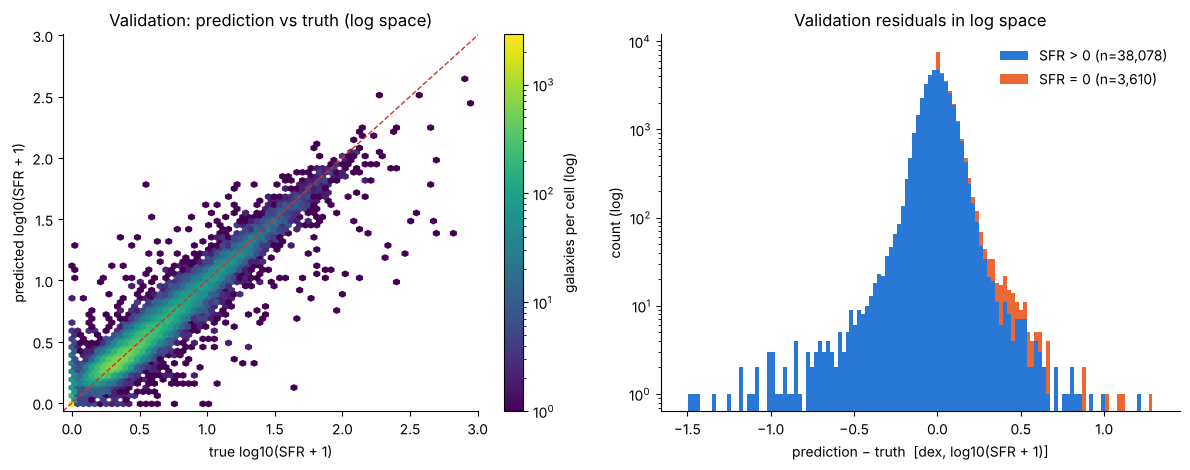

In [57]:
# Starter diagnostic plots — 로그 기준(선택 정의 = log10(SFR + LOG_EPS))으로 바꿨다. 은하가 41,688개라 점 대신 육각 밀도로 그린다.
zt_val = to_log(y_val)
residual = VAL_LOG_PREDICTIONS - zt_val

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ax = axes[0]
hb = ax.hexbin(zt_val, VAL_LOG_PREDICTIONS, gridsize=70, bins="log", mincnt=1, cmap="viridis")
_plot_low = float(min(zt_val.min(), VAL_LOG_PREDICTIONS.min()))
_plot_high = float(max(zt_val.max(), VAL_LOG_PREDICTIONS.max()))
_plot_pad = max(_plot_high - _plot_low, 1e-6) * 0.02
lims = [_plot_low - _plot_pad, _plot_high + _plot_pad]
ax.plot(lims, lims, "--", color="#d0332f", lw=1)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel(f"true log10(SFR + {LOG_EPS:g})"); ax.set_ylabel(f"predicted log10(SFR + {LOG_EPS:g})")
ax.set_title("Validation: prediction vs truth (log space)")
fig.colorbar(hb, ax=ax, label="galaxies per cell (log)")
ax = axes[1]
zero = y_val.to_numpy() == 0
ax.hist([residual[~zero], residual[zero]], bins=120, range=(min(-1.2, float(residual.min()) * 1.02), max(1.2, float(residual.max()) * 1.02)), stacked=True, color=["#2a78d6", "#eb6834"],
        label=[f"SFR > 0 (n={(~zero).sum():,})", f"SFR = 0 (n={zero.sum():,})"])
ax.set_yscale("log")
ax.set_xlabel(f"prediction − truth  [dex, log10(SFR + {LOG_EPS:g})]"); ax.set_ylabel("count (log)")
ax.set_title("Validation residuals in log space")
ax.legend(frameon=False)
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [58]:
# 11절 보조: 선택 로그 공간에서 최종 모델의 오차 구성 — 참 SFR 구간별, 0 판정, 물리적 부분집합(중심/위성 × 호스트 질량)
yv = y_val.to_numpy()
zt, zp = to_log(yv), VAL_LOG_PREDICTIONS
z_base = to_log(np.clip(baseline_pred, 0, None))
z_draft = to_log(val_models["Part II draft (11-07): env clf x linear reg (30 / 13)"])
sfr_bin = pd.cut(yv, [-0.001, 0, 0.1, 1, 5, 20, 100, 3000])


def bin_stats(pred_z, groups):
    t = pd.DataFrame({"g": groups, "res": pred_z - zt, "sq": (pred_z - zt) ** 2})
    return t.groupby("g", observed=True).agg(n=("res", "size"), mean_residual_dex=("res", "mean"),
                                             RMSE_dex=("sq", lambda s: np.sqrt(s.mean())), SSE_share=("sq", lambda s: s.sum() / t["sq"].sum()))


log_bins = bin_stats(zp, sfr_bin)
log_bins["baseline RMSE_dex"] = bin_stats(z_base, sfr_bin)["RMSE_dex"]
log_bins["Part II draft RMSE_dex"] = bin_stats(z_draft, sfr_bin)["RMSE_dex"]
log_bins.index.name = "true SFR bin"
display(log_bins.round(4))

# 0 판정: 꺼진 은하의 오차는 ẑ 자체다. 어느 은하가 그 오차를 만드나
p_fin = FINAL_MODEL.predict_proba_positive(X_val_env)
out0 = VAL_PREDICTIONS == 0
print(f"최종 SFR = 0 출력 (0 문턱과 역변환 절단 포함): 실제 0 {int((out0 & (yv == 0)).sum())}/{int((yv == 0).sum())}개 ({np.mean(out0[yv == 0]):.1%}), "
      f"실제 양수 {int((out0 & (yv > 0)).sum())}개 (실제 SFR 중앙값 {np.median(yv[out0 & (yv > 0)]):.2f}, 최대 {yv[out0 & (yv > 0)].max():.1f})")
pred_zero = p_fin <= 0.5
zero = yv == 0
sq = (zp - zt) ** 2
print(f"분류 (p>0.5 기준): 실제 0→0 {int((pred_zero & zero).sum())}, 실제 0→양수 {int((~pred_zero & zero).sum())}, "
      f"실제 양수→0 {int((pred_zero & ~zero).sum())} (실제 SFR 중앙값 {np.median(yv[pred_zero & ~zero]):.2f}), 실제 양수→양수 {int((~pred_zero & ~zero).sum())}")
print(f"SFR = 0 은하의 오차제곱합 중 p > 0.5로 놓친 {int((~pred_zero & zero).sum())}개의 몫: {sq[zero & ~pred_zero].sum() / sq[zero].sum():.1%} | "
      f"전체 SSE 중 SFR = 0 몫 {sq[zero].sum() / sq.sum():.1%}, 0 < SFR ≤ 1 몫 {sq[(yv > 0) & (yv <= 1)].sum() / sq.sum():.1%}")
dens_val = X_val["log10_overdensity_plus_1"].to_numpy()
LOW = dens_val <= 1.3647506592            # 11-06 실험에서 SFR = 0 비율로 나눈 낮은 밀도 경계
zl = LOW & zero
print(f"낮은 밀도(≤1.365) 실제 0 은하 {zl.sum()}개: FoF 위성 {1 - X_val_env.loc[zl, 'fof_is_central'].mean():.1%} "
      f"(낮은 밀도 전체 {1 - X_val_env.loc[LOW, 'fof_is_central'].mean():.1%}), 0 판정 {np.mean(p_fin[zl] <= 0.5):.1%}, "
      f"이들의 평균 오차 {np.mean(zp[zl] - zt[zl]):+.3f} dex")

# 물리적 부분집합: 중심/위성 × 호스트(그룹 최대) 헤일로 질량
cen = np.where(X_val_env["fof_is_central"].to_numpy() == 1, "central", "satellite")
host = pd.cut(X_val_env["fof_group_max_logm"].to_numpy(), [8, 12, 13, 13.5, 14, 16])
env_err = pd.DataFrame({"central": cen, "host logM": host, "zero": zero, "res": zp - zt, "sq": sq,
                        "base_sq": (z_base - zt) ** 2}).groupby(["central", "host logM"], observed=True).agg(
    n=("res", "size"), zero_frac=("zero", "mean"), mean_residual_dex=("res", "mean"),
    RMSE_dex=("sq", lambda s: np.sqrt(s.mean())), baseline_RMSE_dex=("base_sq", lambda s: np.sqrt(s.mean())),
    SSE_share=("sq", lambda s: s.sum() / sq.sum()))
display(env_err.round(4))
top = yv > 100
print(f"SFR > 100 은하 {top.sum()}개: 평균 오차 {np.mean(zp[top] - zt[top]):+.3f} dex, 로그 SSE 몫 {sq[top].sum() / sq.sum():.2%} "
      f"(선형 RMSE에서는 SSE의 85%였다)")

,n,mean_residual_dex,RMSE_dex,SSE_share,baseline RMSE_dex,Part II draft RMSE_dex
true SFR bin,,,,,,
"(-0.001, 0.0]",3610,0.0320,0.0980,0.0940,0.3309,0.1921
"(0.0, 0.1]",62,0.1723,0.2102,0.0074,0.3890,0.3658
"(0.1, 1.0]",8136,0.0460,0.0849,0.1588,0.1516,0.1569
"(1.0, 5.0]",23244,-0.0119,0.0831,0.4347,0.0963,0.0948
"(5.0, 20.0]",5594,-0.0276,0.1074,0.1750,0.1456,0.1405
"(20.0, 100.0]",981,-0.0562,0.1661,0.0733,0.1828,0.1807
"(100.0, 3000.0]",61,-0.3957,0.5860,0.0568,0.6718,0.7376


최종 SFR = 0 출력 (0 문턱과 역변환 절단 포함): 실제 0 2877/3610개 (79.7%), 실제 양수 46개 (실제 SFR 중앙값 0.53, 최대 9.4)
분류 (p>0.5 기준): 실제 0→0 3336, 실제 0→양수 274, 실제 양수→0 207 (실제 SFR 중앙값 0.85), 실제 양수→양수 37871
SFR = 0 은하의 오차제곱합 중 p > 0.5로 놓친 274개의 몫: 80.2% | 전체 SSE 중 SFR = 0 몫 9.4%, 0 < SFR ≤ 1 몫 16.6%
낮은 밀도(≤1.365) 실제 0 은하 115개: FoF 위성 93.0% (낮은 밀도 전체 36.4%), 0 판정 21.7%, 이들의 평균 오차 +0.221 dex


n  zero_frac  mean_residual_dex  RMSE_dex  \
central   host logM                                                     
central   (8.0, 12.0]   18103     0.0043             0.0010    0.0756   
          (12.0, 13.0]   4280     0.0044            -0.0030    0.0987   
          (13.0, 13.5]    377     0.0027            -0.0105    0.2174   
          (13.5, 14.0]    112     0.0000            -0.0202    0.4705   
          (14.0, 16.0]     26     0.0000            -0.2057    0.6301   
satellite (8.0, 12.0]    3171     0.0145             0.0031    0.0741   
          (12.0, 13.0]   6719     0.0118            -0.0005    0.0920   
          (13.0, 13.5]   3620     0.0326             0.0033    0.1018   
          (13.5, 14.0]   3022     0.3898            -0.0044    0.1141   
          (14.0, 16.0]   2258     0.9265            -0.0032    0.0931   

                        baseline_RMSE_dex  SSE_share  
central   host logM                                   
central   (8.0, 12.0]              0.0924     0.2807  
          (12.0, 13.0]             0.1355     0.1130  
          (13.0, 13.5]             0.3205     0.0483  
          (13.5, 14.0]             0.6761     0.0672  
          (14.0, 16.0]             0.7695     0.0280  
satellite (8.0, 12.0]              0.1002     0.0473  
          (12.0, 13.0]             0.1330     0.1541  
          (13.0, 13.5]             0.1637     0.1016  
          (13.5, 14.0]             0.2589     0.1067  
          (14.0, 16.0]             0.2960     0.0531

SFR > 100 은하 61개: 평균 오차 -0.396 dex, 로그 SSE 몫 5.68% (선형 RMSE에서는 SSE의 85%였다)


In [59]:
# 11절 보조 (2): 0 판정 오류는 어디서 나는가 — 주변 밀도 구간별 (val 진단, 모델을 다시 고르지 않음)
# 놓친 0 = 실제 0인데 0을 내지 않음, 잘못 끈 은하 = 실제 양수인데 0을 냄. AUC는 같은 밀도 구간 안에서 0 은하를 가려내는 순위 성능이다.
from sklearn.metrics import roc_auc_score
_dens_bin = pd.cut(X_val["log10_overdensity_plus_1"].to_numpy(), [-np.inf, 1.3647506592, 1.7, 2.0, np.inf])
_rows = []
for _b in _dens_bin.categories:
    _m = np.asarray(_dens_bin == _b)
    _z, _o = zero[_m], out0[_m]
    _rows.append({"log density bin": str(_b), "n": int(_m.sum()), "zero_frac": _z.mean(),
                  "missed_zero": int((_z & ~_o).sum()), "wrongly_zeroed": int((~_z & _o).sum()),
                  "missed_zero_SSE_share_of_all": sq[_m][_z & ~_o].sum() / sq.sum(),
                  "AUC model P(0)": roc_auc_score(_z, 1 - p_fin[_m]),
                  "AUC density only": roc_auc_score(_z, dens_val[_m])})
ZERO_ERROR_BY_DENSITY = pd.DataFrame(_rows).set_index("log density bin")
display(ZERO_ERROR_BY_DENSITY.round(4))
_mz = zero & ~out0
print(f"놓친 0 은하 {_mz.sum()}개: 예측 SFR 중앙값 {np.median(VAL_PREDICTIONS[_mz]):.3f}, P(0) < 0.5인 은하 {int((_mz & (p_fin > 0.5)).sum())}개 | "
      f"잘못 끈 은하 {int((~zero & out0).sum())}개: 실제 SFR 중앙값 {np.median(yv[~zero & out0]):.2f}")
print(f"전체 AUC — 모델 {roc_auc_score(zero, 1 - p_fin):.4f}, 밀도만 {roc_auc_score(zero, dens_val):.4f}")

# 11절 보조 (3): 중간 보고서 8절의 핵심 가설 "병합 정보가 극단 SFR을 설명한다"의 확인 (병합 후보 = log10_mass_ratio > −6, EDA 5와 같은 정의)
_merger = X_val["log10_mass_ratio"].to_numpy() > -6
_res = zp - zt
_tail_rows = []
for _name, _m in {"SFR > 100": yv > 100, "30 < SFR ≤ 100": (yv > 30) & (yv <= 100), "0 < SFR ≤ 30": (yv > 0) & (yv <= 30)}.items():
    for _g, _gm in {"병합 후보": _merger, "비후보": ~_merger}.items():
        _k = _m & _gm
        _tail_rows.append({"true SFR": _name, "group": _g, "n": int(_k.sum()),
                           "mean_residual_dex": _res[_k].mean() if _k.any() else np.nan,
                           "RMSE_dex": np.sqrt(np.mean(_res[_k] ** 2)) if _k.any() else np.nan})
MERGER_TAIL = pd.DataFrame(_tail_rows).set_index(["true SFR", "group"])
display(MERGER_TAIL.round(4))
print(f"SFR > 100 val 은하 {int((yv > 100).sum())}개 중 병합 후보 {int((_merger & (yv > 100)).sum())}개 ({np.mean(_merger[yv > 100]):.1%}); "
      f"양수 은하 전체의 병합 후보 비율 {np.mean(_merger[yv > 0]):.1%}")

,n,zero_frac,missed_zero,wrongly_zeroed,missed_zero_SSE_share_of_all,AUC model P(0),AUC density only
log density bin,,,,,,,
"(-inf, 1.365]",34664,0.0033,104,0,0.0234,0.9836,0.8652
"(1.365, 1.7]",3729,0.1668,348,4,0.0393,0.9795,0.8077
"(1.7, 2.0]",2095,0.8296,210,22,0.0238,0.9678,0.5878
"(2.0, inf]",1200,0.9458,71,20,0.0074,0.8978,0.5226


놓친 0 은하 733개: 예측 SFR 중앙값 0.290, P(0) < 0.5인 은하 274개 | 잘못 끈 은하 46개: 실제 SFR 중앙값 0.53
전체 AUC — 모델 0.9976, 밀도만 0.9856


n  mean_residual_dex  RMSE_dex
true SFR       group                                    
SFR > 100      병합 후보     55            -0.3917    0.5689
               비후보        6            -0.4324    0.7239
30 < SFR ≤ 100 병합 후보    353            -0.0637    0.1824
               비후보      121            -0.0954    0.2244
0 < SFR ≤ 30   병합 후보   6100             0.0045    0.1016
               비후보    31443            -0.0030    0.0860

SFR > 100 val 은하 61개 중 병합 후보 55개 (90.2%); 양수 은하 전체의 병합 후보 비율 17.1%


### 11.1 Error-Analysis Discussion — **STUDENT RESPONSE**

**Zero / quiescent galaxies:** 실제 SFR = 0인 3,610개 중 2,877개(79.7%)에 정확히 0을 냈고, 0을 낸 2,923개 중 98.4%가 실제 0이었다. 이 집단의 로그 RMSE는 0.098 dex(기준선 0.331)이며 전체 로그 오차제곱합의 9.4%를 차지한다. 0을 내지 못한 733개("놓친 0")에는 대부분 작은 값을 냈다(예측 중앙값 0.29). 그중 분류기가 "켜져 있다"(P(SFR > 0) > 0.5)고 판단한 274개가 0 은하 오차의 80.2%를 만든다. 반대로 양수인데 0을 낸 46개는 실제 SFR이 작은 은하들이다(중앙값 0.53, 최대 9.4).

**Positive-SFR galaxies:** 로그 RMSE는 0.094 dex다. 오차는 대부분의 은하가 있는 1 < SFR ≤ 5 구간(23,244개, 오차제곱합의 43.5%)에서 나온다. 작은 SFR은 과대예측(0.1 < SFR ≤ 1에서 평균 +0.046 dex)하고 큰 SFR은 과소예측(20 < SFR ≤ 100에서 −0.056 dex)한다. 조건부 평균을 예측하는 회귀에서 흔한, 가운데로 당겨지는 경향이다.

**High-SFR tail:** SFR > 100인 61개는 평균 −0.396 dex 과소예측된다(RMSE 0.586). 선형 RMSE에서는 오차의 85%를 차지했지만 로그 공간에서는 5.7%다. 이 중 55개(90.2%)가 병합 후보(`log10_mass_ratio` > −6)로, 양수 은하 전체의 병합 후보 비율 17.1%보다 훨씬 높다. 그런데 병합 후보(−0.39 dex)와 비후보(−0.43 dex, 6개) 모두 비슷하게 과소예측됐다. **중간 보고서의 핵심 가설에 대한 답은 이렇다:** 병합은 극단 SFR이 나오는 은하를 가리키지만, 병합 은하 대부분은 그렇게까지 높지 않아 크기를 정하지 못한다. 병합 × 성장 피처를 더해도, 꼬리를 따로 배우는 구조를 써도 이 과소예측은 남았다.

**Largest or most systematic failure mode:** 두 가지다. (1) 극단 SFR의 체계적 과소예측. (2) 0 판정의 오류가 **0과 양수가 섞이는 중간 밀도에 몰리는 것**이다. 위 셀의 밀도 구간표에서 놓친 0 은하 733개 중 348개가 log 밀도 1.365~1.7 구간(0 비율 17%)에 있고, 이 구간의 놓친 0이 전체 오차제곱합의 3.9%로 가장 크다.

**Likely explanation:** (1)은 극단 SFR을 정하는 정보(예: 병합의 진행 단계, 중심부 가스량)가 입력에 없기 때문으로 보인다. 병합 지표는 병합 여부와 질량비만 담는다. (2)는 모델이 밀도 하나에만 기대서가 아니다. 같은 밀도 구간 안에서도 분류기의 AUC는 0.90~0.98로, 밀도만 쓴 AUC(0.52~0.87)보다 훨씬 높다. 문제는 **사전 확률**이다. 가장 낮은 밀도 구간에서는 0이 0.3%(34,664개 중 115개)뿐이라 순위를 잘 매겨도 확률이 0.9 문턱에 닿기 어렵다. 이 115개는 93.0%가 FoF 위성으로(같은 밀도 전체는 36.4%), 작은 그룹에서 이미 꺼진 위성으로 보인다.

### 11.2 정확한 0 출력의 손익과 입력 진단

**0 출력 문턱의 손익.** 문턱이 있는 행에서 문턱 전후의 제곱오차 차이는 a = p(m − z0), t = z_true − z0로 두면 **2at − a²**다. 실제 0이면 −a²만큼 줄고, 실제 양수이면 t > a/2일 때 는다. 최종 모델에서 문턱으로 0을 낸 행은 실제 0이 2,876개, 실제 양수가 46개였고, 전체 MSE 변화는 각각 −0.0000085와 +0.0000089, 합계 +0.0000004였다. 로그 RMSE로는 +0.000002 dex로, 문턱 없는 예측(0.094060)과 사실상 같다. **점수를 거의 잃지 않고 2,876개 은하에 "별 생성이 꺼졌다"는 이산적인 답을 준다.** 문턱 근처(P(0) = 0.88~0.92)의 157개 중 실제 0은 144개(91.7%), 평균 예측 확률은 90.1%로 확률이 그 근처에서 잘 맞았다.

**전구체 특수값과 극단적 성장.** 전구체 항성 로그 질량이 정확히 6.0인 은하 772개는 모두 항성 질량 증가가 2 dex를 넘는 782개 안에 있다. 즉 극단 성장값의 대부분은 실제 성장이 아니라 특수값일 가능성이 크다. 검증셋에서 이 은하들(152개)의 로그 RMSE는 0.177 dex로 나머지(0.094)의 약 두 배다. 원래 열을 함께 넣어 트리가 특수값을 따로 가를 수 있게 했지만, 오차는 남았다.

**거대 헤일로에 대한 방사 운동.** 헤일로 로그 질량 14 이상의 가장 가까운 은하에 대해 상대 속도의 방사 성분 부호를 계산했다. R200 안에서는 방향과 관계없이 98~99%가 0이다. 1~3 R200에서는 수치상 멀어지는 은하의 0 비율(81.8%)이 가까워지는 은하(57.0%)보다 높다. 이미 호스트를 통과해 나오는 은하(backsplash)가 더 많이 꺼져 있다는 해석과 일관되지만, 속도의 정의가 공개되지 않아 부호의 물리적 의미는 확정하지 않는다. 모델의 평균 오차는 두 방향 모두 0에 가깝다.

In [60]:
# (a) gate 손실 회계: 기존 최종 모델을 재학습하지 않는다.
_p = FINAL_MODEL.predict_proba_positive(X_val_env)
_m = FINAL_MODEL.predict_log_positive(X_val_env)
_z0 = float(to_log(0.0, LOG_EPS))
_soft = to_log(from_log(_p * _m + (1 - _p) * _z0), LOG_EPS)  # 선형 출력의 비음수 절단과 일치
_gate = (1 - _p) >= ZERO_THRESHOLD
_a, _t = _soft - _z0, to_log(y_val, LOG_EPS) - _z0
_delta = np.where(_gate, 2 * _a * _t - _a ** 2, 0.0)
_direct_delta = (to_log(VAL_PREDICTIONS) - to_log(y_val)) ** 2 - (_soft - to_log(y_val)) ** 2
assert np.allclose(_delta, _direct_delta, atol=1e-12, rtol=1e-10)
_cost = pd.DataFrame({"true_zero": y_val.to_numpy() == 0, "gated": _gate, "p0": 1 - _p,
                      "positive_log_gap": _m - _z0, "delta_SSE": _delta})
GATE_COST = _cost.groupby(["gated", "true_zero"]).agg(n=("delta_SSE", "size"), delta_SSE=("delta_SSE", "sum"))
GATE_COST["delta_MSE_all_rows"] = GATE_COST.delta_SSE / len(y_val)
display(GATE_COST)
print("gate-soft MSE delta:", _delta.mean(), "RMSE delta:",
      log_rmse(y_val, VAL_PREDICTIONS, LOG_EPS) - log_rmse(y_val, from_log(_soft), LOG_EPS))
_cost["p0_bin"] = pd.cut(_cost.p0, [0, .5, .8, .88, .9, .92, .95, 1], include_lowest=True)
_cost["positive_size_bin"] = pd.qcut(_cost.positive_log_gap, 4, duplicates="drop")
display(_cost.groupby(["p0_bin", "positive_size_bin"], observed=True).agg(
    n=("p0", "size"), true_zero_fraction=("true_zero", "mean"), p0_mean=("p0", "mean"), delta_SSE=("delta_SSE", "sum")))
display(_cost.loc[_cost.p0.between(.88, .92)].groupby("true_zero").agg(
    n=("p0", "size"), p0_mean=("p0", "mean"), positive_gap_mean=("positive_log_gap", "mean"), delta_SSE=("delta_SSE", "sum")))

# (b) 입력만의 센티널 후보 교차표와 같은 val의 잔차표; 학습 피처는 변경하지 않는다.
_SENTINEL = df["log10_main_prog_stellar_mass"] == 6.0
_EXTREME = MASS["dlogMs_growth"] > 2
SENTINEL_CROSSTAB = pd.crosstab(_SENTINEL.rename("progenitor_star_6_candidate"), _EXTREME.rename("growth_gt2dex"))
display(SENTINEL_CROSSTAB)
_sv = pd.DataFrame({"sentinel_candidate": _SENTINEL.loc[y_val.index].to_numpy(),
                    "growth_gt2dex": _EXTREME.loc[y_val.index].to_numpy(),
                    "res": VAL_LOG_PREDICTIONS - to_log(y_val),
                    "sq": (VAL_LOG_PREDICTIONS - to_log(y_val)) ** 2})
display(_sv.groupby(["sentinel_candidate", "growth_gt2dex"]).agg(n=("res", "size"),
    bias=("res", "mean"), RMSE=("sq", lambda s: np.sqrt(s.mean())), SSE=("sq", "sum")))

# (c) 방사 상대속도 수치 부호: 타깃 없이 후보 선정·주기 거리 계산.
_rp = df[["pos_x", "pos_y", "pos_z"]].to_numpy() % BOX_SIZE
_rv = df[["vel_x", "vel_y", "vel_z"]].to_numpy()
_rmh = df["log10_halo_mass"].to_numpy()
_sel = np.flatnonzero(_rmh >= 14.0)
assert len(_sel), "no massive candidate for radial diagnostic"
_dist, _j = cKDTree(_rp[_sel], boxsize=BOX_SIZE).query(_rp, k=1)
_hj = _sel[_j]
_dr = ((_rp - _rp[_hj] + BOX_SIZE / 2) % BOX_SIZE) - BOX_SIZE / 2
_radius = np.linalg.norm(_dr, axis=1)
_ur = np.full(len(df), np.nan)
_valid = _radius > 0
_ur[_valid] = np.einsum("ij,ij->i", (_rv - _rv[_hj])[_valid], _dr[_valid]) / _radius[_valid]
_r200 = (3 * 10 ** _rmh[_hj] / (4 * np.pi * 200 * RHO_CRIT)) ** (1 / 3)
_direction = np.where(~_valid, "zero_distance", np.where(_ur < 0, "approaching_numeric", np.where(_ur > 0, "receding_numeric", "zero_component")))
RADIAL_INPUT_COUNTS = pd.Series(_direction).value_counts()
print("방사 부호 입력 집계(물리 속도 정의 미확정):"); display(RADIAL_INPUT_COUNTS)
_radial = pd.DataFrame({"direction": _direction, "r_R200": _radius / _r200}, index=df.index).loc[y_val.index]
_radial["radius_bin"] = pd.cut(_radial.r_R200, [-.001, 0, 1, 3, np.inf])
_radial["zero"] = y_val.to_numpy() == 0
_radial["res"] = VAL_LOG_PREDICTIONS - to_log(y_val)
_radial["sq"] = _radial.res ** 2
RADIAL_ERROR = _radial.groupby(["radius_bin", "direction"], observed=True).agg(
    n=("res", "size"), zero_fraction=("zero", "mean"), bias=("res", "mean"), RMSE=("sq", lambda s: np.sqrt(s.mean())))
display(RADIAL_ERROR.round(6))

n  delta_SSE  delta_MSE_all_rows
gated true_zero                                      
False False      38032   0.000000            0.000000
      True         734   0.000000            0.000000
True  False         46   0.372523            0.000009
      True        2876  -0.354340           -0.000008

gate-soft MSE delta: 4.361643484172622e-07 RMSE delta: 2.318507142898274e-06


n  true_zero_fraction   p0_mean  \
p0_bin        positive_size_bin                                        
(-0.001, 0.5] (-0.168, 0.308]     8104            0.019743  0.016818   
              (0.308, 0.424]      9878            0.004556  0.004461   
              (0.424, 0.631]      9975            0.003910  0.003929   
              (0.631, 2.644]     10188            0.002945  0.002506   
(0.5, 0.8]    (-0.168, 0.308]      180            0.655556  0.655242   
              (0.308, 0.424]        67            0.716418  0.660842   
              (0.424, 0.631]        63            0.682540  0.662916   
              (0.631, 2.644]        57            0.614035  0.667267   
(0.8, 0.88]   (-0.168, 0.308]       77            0.805195  0.844263   
              (0.308, 0.424]        44            0.886364  0.843321   
              (0.424, 0.631]        37            0.837838  0.844965   
              (0.631, 2.644]        29            0.827586  0.845168   
(0.88, 0.9]   (-0.168, 0.308]       22            0.863636  0.891787   
              (0.308, 0.424]        18            0.888889  0.888594   
              (0.424, 0.631]        17            1.000000  0.890550   
              (0.631, 2.644]        10            0.800000  0.890292   
(0.9, 0.92]   (-0.168, 0.308]       45            0.933333  0.909443   
              (0.308, 0.424]        17            0.941176  0.908661   
              (0.424, 0.631]        20            0.900000  0.910239   
              (0.631, 2.644]         8            1.000000  0.907739   
(0.92, 0.95]  (-0.168, 0.308]       63            1.000000  0.936326   
              (0.308, 0.424]        48            0.937500  0.934746   
              (0.424, 0.631]        41            0.951220  0.937368   
              (0.631, 2.644]        15            1.000000  0.934012   
(0.95, 1.0]   (-0.168, 0.308]     1931            0.988607  0.993067   
              (0.308, 0.424]       350            0.991429  0.987638   
              (0.424, 0.631]       269            0.962825  0.984099   
              (0.631, 2.644]       115            1.000000  0.982549   

                                 delta_SSE  
p0_bin        positive_size_bin             
(-0.001, 0.5] (-0.168, 0.308]     0.000000  
              (0.308, 0.424]      0.000000  
              (0.424, 0.631]      0.000000  
              (0.631, 2.644]      0.000000  
(0.5, 0.8]    (-0.168, 0.308]     0.000000  
              (0.308, 0.424]      0.000000  
              (0.424, 0.631]      0.000000  
              (0.631, 2.644]      0.000000  
(0.8, 0.88]   (-0.168, 0.308]     0.000000  
              (0.308, 0.424]      0.000000  
              (0.424, 0.631]      0.000000  
              (0.631, 2.644]      0.000000  
(0.88, 0.9]   (-0.168, 0.308]     0.000000  
              (0.308, 0.424]      0.000000  
              (0.424, 0.631]      0.000000  
              (0.631, 2.644]      0.000000  
(0.9, 0.92]   (-0.168, 0.308]     0.011868  
              (0.308, 0.424]      0.010178  
              (0.424, 0.631]      0.052577  
              (0.631, 2.644]     -0.063845  
(0.92, 0.95]  (-0.168, 0.308]    -0.012549  
              (0.308, 0.424]      0.010832  
              (0.424, 0.631]      0.050674  
              (0.631, 2.644]     -0.049880  
(0.95, 1.0]   (-0.168, 0.308]     0.027311  
              (0.308, 0.424]     -0.001192  
              (0.424, 0.631]      0.015814  
              (0.631, 2.644]     -0.033606

,n,p0_mean,positive_gap_mean,delta_SSE
true_zero,,,,
False,13,0.897964,0.423912,0.146951
True,144,0.901539,0.391123,-0.136173


growth_gt2dex,False,True
progenitor_star_6_candidate,,
False,207655,10
True,0,772


,,n,bias,RMSE,SSE
sentinel_candidate,growth_gt2dex,,,,
False,False,41536,-0.000260,0.093627,364.107471
True,True,152,0.012839,0.176566,4.738709


방사 부호 입력 집계(물리 속도 정의 미확정):


approaching_numeric    135073
receding_numeric        73231
zero_distance             133
Name: count, dtype: int64

n  zero_fraction      bias      RMSE
radius_bin    direction                                                    
(-0.001, 0.0] zero_distance           27       0.000000 -0.227052  0.636374
(0.0, 1.0]    approaching_numeric    735       0.989116 -0.000289  0.047376
              receding_numeric       606       0.983498 -0.002356  0.047307
(1.0, 3.0]    approaching_numeric   1063       0.570085 -0.002194  0.159270
              receding_numeric       384       0.817708 -0.001886  0.111015
(3.0, inf]    approaching_numeric  25405       0.035977  0.000011  0.091488
              receding_numeric     13468       0.033635  0.000126  0.090607

#### 11.3 입력 진단 — FoF 그룹 연결의 민감도

FoF 그룹은 연결 길이 안의 은하를 사슬처럼 이어 만든다. 그래서 은하 하나가 두 무리를 잇는 다리일 수 있다. 가장 큰 연결 성분 10개에서 이런 다리(관절점) 137개를 찾고, 하나씩 빼면 은하 10개 이상인 무리 둘로 갈라지는 경우를 셌더니 19개였다. 예를 들어 338개 은하의 성분에서 한 은하를 빼면 309개와 28개로 갈라지고, 28개 은하의 그룹 최대 질량과 1개의 중심 여부가 바뀐다. 은하 하나의 포함 여부가 다른 은하들의 환경 피처까지 바꿀 수 있다는 뜻이다. 입력만 본 진단이며, 이것이 예측 오차를 얼마나 바꾸는지는 재지 않았다.

In [61]:
def diagnose_fof_articulations(frame, box, fof_b=0.2, top_k=10, min_side=10):
    """Input-only graph diagnostic; fixed linking length and no row/model changes."""
    import networkx as nx
    positions = frame[['pos_x', 'pos_y', 'pos_z']].to_numpy() % box
    velocities = frame[['vel_x', 'vel_y', 'vel_z']].to_numpy()
    masses = frame['log10_halo_mass'].to_numpy()
    link = fof_b * box / len(frame) ** (1 / 3)
    pairs = cKDTree(positions, boxsize=box).query_pairs(link, output_type='ndarray')
    graph = nx.Graph()
    graph.add_nodes_from(range(len(frame)))
    graph.add_edges_from(pairs)
    components = sorted(nx.connected_components(graph), key=lambda c: (-len(c), min(c)))[:top_k]
    rows, cases = [], []
    for rank, members in enumerate(components):
        subgraph = graph.subgraph(members)
        articulations = sorted(nx.articulation_points(subgraph))
        count = 0
        for removed in articulations:
            parts = list(nx.connected_components(subgraph.subgraph(members - {removed})))
            sizes = sorted((len(part) for part in parts), reverse=True)
            if sum(size >= min_side for size in sizes) >= 2:
                count += 1
                cases.append({'component_rank': rank, 'removed_row': int(removed),
                              'before_size': len(members), 'after_sizes': sizes})
        rows.append({'component_min_row': int(min(members)), 'n_members': len(members),
                     'n_articulation_points': len(articulations), 'two_large_side_cases': count})
    result = {'link_fixed': link, 'top10_components': rows, 'min_side': min_side,
              'tested_articulations': sum(row['n_articulation_points'] for row in rows),
              'two_large_side_cases': cases, 'two_large_side_case_count': len(cases),
              'scope': 'Only the largest ten components; input-only, fixed link, no data deletion or model refit.'}
    if not cases:
        result['example'] = None
        return result
    # Largest qualifying component first, then smallest original row index; no SFR/residual selection.
    selected = cases[0]
    members = components[selected['component_rank']]
    removed = selected['removed_row']
    parts = list(nx.connected_components(graph.subgraph(members - {removed})))
    oldmax = masses[list(members)].max()
    old_velocity_mean = velocities[list(members)].mean(axis=0)
    changed_max = changed_central = 0
    velocity_changes = []
    for part in parts:
        idx = np.array(sorted(part), dtype=int)
        newmax = masses[idx].max()
        changed_max += len(idx) if newmax != oldmax else 0
        changed_central += int(np.sum((masses[idx] >= oldmax - 1e-9) != (masses[idx] >= newmax - 1e-9)))
        if len(idx) > 1:
            old_dv = np.linalg.norm(velocities[idx] - old_velocity_mean, axis=1)
            new_dv = np.linalg.norm(velocities[idx] - velocities[idx].mean(axis=0), axis=1)
            velocity_changes.extend(np.abs(new_dv - old_dv).tolist())
    result['example'] = {**selected, 'removed_subhalo_id': int(frame.iloc[removed]['subhalo_id']),
                         'remaining_group_max_changed': changed_max,
                         'remaining_central_indicator_changed': changed_central,
                         'median_abs_dv_group_change_non_singletons': float(np.median(velocity_changes)),
                         'selection': 'Largest qualifying component, then smallest original row index.'}
    return result


FOF_DIAGNOSTIC = diagnose_fof_articulations(df, BOX_SIZE)
print(json.dumps(FOF_DIAGNOSTIC, indent=2))


{
  "link_fixed": 0.6746342514621309,
  "top10_components": [
    {
      "component_min_row": 0,
      "n_members": 338,
      "n_articulation_points": 16,
      "two_large_side_cases": 3
    },
    {
      "component_min_row": 412,
      "n_members": 241,
      "n_articulation_points": 8,
      "two_large_side_cases": 0
    },
    {
      "component_min_row": 1611,
      "n_members": 239,
      "n_articulation_points": 14,
      "two_large_side_cases": 4
    },
    {
      "component_min_row": 915,
      "n_members": 235,
      "n_articulation_points": 14,
      "two_large_side_cases": 2
    },
    {
      "component_min_row": 1385,
      "n_members": 234,
      "n_articulation_points": 20,
      "two_large_side_cases": 0
    },
    {
      "component_min_row": 664,
      "n_members": 226,
      "n_articulation_points": 18,
      "two_large_side_cases": 0
    },
    {
      "component_min_row": 2677,
      "n_members": 204,
      "n_articulation_points": 11,
      "two_large_side_cas

## 12. Model Interpretation & Astrophysical Discussion — **REQUIRED**

Use an interpretation method appropriate for your model (for example, permutation importance, SHAP, ablation, partial dependence, learned graph/environmental analysis, or another justified method). The goal is not merely to rank features, but to connect the model behavior to the underlying astrophysics.

1단계 분류기 (상위 12개):


,분류기: log loss 증가,SD
log10_overdensity_plus_1,0.2506,0.0031
dlogMh_growth,0.0167,0.0008
log_rho_5nn,0.0103,0.0007
dlogMs_growth,0.0081,0.0004
stellar_growth_residual_at_mass,0.0079,0.0002
prog_star_to_halo,0.0055,0.0001
fof_log_richness,0.0046,0.0003
fof_group_max_logm,0.0044,0.0001
host_logm_13.5,0.0036,0.0001
merger_growth_product,0.0030,0.0002


2단계 로그 회귀기 (상위 12개):


,로그 회귀기: RMSE 증가 (dex),SD
log10_main_prog_mass,0.1455,0.0005
mass_growth_product,0.0600,0.0004
log10_stellar_mass,0.0595,0.0002
bh_to_star,0.0216,0.0004
dlogMh_growth,0.0147,0.0002
stellar_growth_residual_at_mass,0.0119,0.0001
dlogMs_growth,0.0103,0.0004
log10_BH_mass,0.0046,0.0002
halo_minus_stellar,0.0021,0.0001
bh_residual_at_stellar_mass,0.0019,0.0001


질량 성장·비율 피처 — 분류기: {'dlogMs_growth': 0.0081, 'dlogMh_growth': 0.0167, 'bh_to_star': 0.0002, 'prog_star_to_halo': 0.0055}
질량 성장·비율 피처 — 로그 회귀기: {'dlogMs_growth': 0.0103, 'dlogMh_growth': 0.0147, 'bh_to_star': 0.0216, 'prog_star_to_halo': 0.0009}
추가 피처 12개 — 분류기: {'mass_growth_product': 0.0002, 'merger_flag': 0.0, 'merger_growth_product': 0.003, 'merger_strength_growth_product': 0.0, 'stellar_growth_residual_at_mass': 0.0079, 'bh_residual_at_stellar_mass': 0.0001, 'nn_log_distance': 0.0006, 'nn_log_stellar_mass_ratio': 0.0003, 'nn_relative_speed': 0.0006, 'nn_r_over_primary_R200': 0.0022, 'nn3_max_log_stellar_mass_ratio': 0.0006, 'nn3_min_relative_speed': 0.0002}
추가 피처 12개 — 로그 회귀기: {'mass_growth_product': 0.06, 'merger_flag': 0.0, 'merger_growth_product': 0.0, 'merger_strength_growth_product': 0.0, 'stellar_growth_residual_at_mass': 0.0119, 'bh_residual_at_stellar_mass': 0.0019, 'nn_log_distance': 0.0015, 'nn_log_stellar_mass_ratio': 0.0009, 'nn_relative_speed': 0.0002, 'nn_r_over_prima

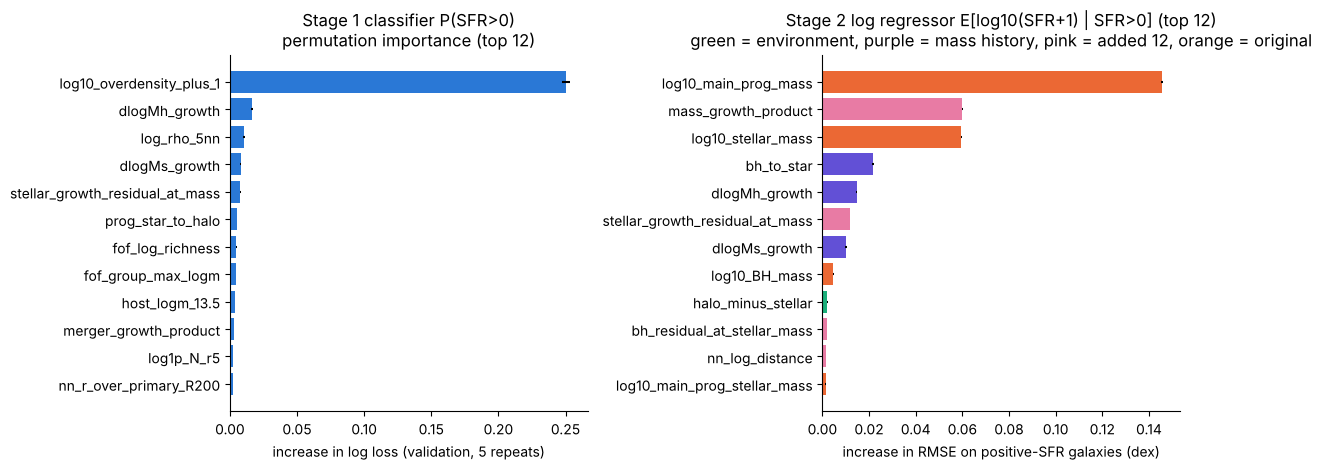

n  실제_0비율  예측_0확률_평균  양수_실제_평균z  양수_예측_평균z
central   host                                                        
central   (8.0, 12.0]   18103   0.004      0.004      0.466      0.467
          (12.0, 13.0]   4280   0.004      0.004      1.060      1.057
          (13.0, 13.5]    377   0.003      0.001      1.214      1.203
          (13.5, 14.0]    112   0.000      0.000      1.371      1.351
          (14.0, 16.0]     26   0.000      0.001      1.728      1.524
satellite (8.0, 12.0]    3171   0.015      0.015      0.368      0.372
          (12.0, 13.0]   6719   0.012      0.010      0.461      0.460
          (13.0, 13.5]   3620   0.033      0.030      0.447      0.449
          (13.5, 14.0]   3022   0.390      0.389      0.450      0.448
          (14.0, 16.0]   2258   0.926      0.933      0.397      0.409

n  항성성장_중앙  헤일로성장_중앙  헤일로감소_비율
          zero                                     
central   False  91608    0.231     0.161     0.000
          True     398    0.185     0.106     0.020
satellite False  60497    0.208     0.089     0.247
          True   13626    0.175     0.052     0.290

양수 은하: 항성 성장과 log sSFR의 Spearman 0.571, log SFR과 -0.078, 항성 질량 10분위 안 log SFR과의 중앙값 0.480


In [62]:
# 12절 보조: 두 단계가 각각 어느 피처에 기대나 — permutation importance (검증 데이터, 5회 반복). 해석용.
# 회귀기는 양수 은하의 선택 로그 SFR에서 RMSE 증가로 잰다.
yv_pos = (y_val.to_numpy() > 0).astype(int)
imp_clf = permutation_importance(FINAL_MODEL.clf_, X_val_env[FINAL_COLS], yv_pos, scoring="neg_log_loss",
                                 n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
pos_mask = yv > 0
imp_reg = permutation_importance(FINAL_MODEL.reg_, X_val_env.loc[pos_mask, FINAL_COLS], to_log(yv[pos_mask]),
                                 scoring="neg_root_mean_squared_error", n_repeats=5, random_state=RANDOM_SEED, n_jobs=-1)
imp_c = pd.DataFrame({"분류기: log loss 증가": imp_clf.importances_mean, "SD": imp_clf.importances_std}, index=FINAL_COLS).sort_values("분류기: log loss 증가", ascending=False)
imp_r = pd.DataFrame({"로그 회귀기: RMSE 증가 (dex)": imp_reg.importances_mean, "SD": imp_reg.importances_std}, index=FINAL_COLS).sort_values("로그 회귀기: RMSE 증가 (dex)", ascending=False)
print("1단계 분류기 (상위 12개):"); display(imp_c.head(12).round(4))
print("2단계 로그 회귀기 (상위 12개):"); display(imp_r.head(12).round(4))
_env_r = imp_r.loc[imp_r.index.isin(ENV_FEATURES), "로그 회귀기: RMSE 증가 (dex)"]
print("질량 성장·비율 피처 — 분류기:", imp_c.loc[MASS_FEATURES, "분류기: log loss 증가"].round(4).to_dict())
print("질량 성장·비율 피처 — 로그 회귀기:", imp_r.loc[MASS_FEATURES, "로그 회귀기: RMSE 증가 (dex)"].round(4).to_dict())
print("추가 피처 12개 — 분류기:", imp_c.loc[EXTRA_FEATURES, "분류기: log loss 증가"].round(4).to_dict())
print("추가 피처 12개 — 로그 회귀기:", imp_r.loc[EXTRA_FEATURES, "로그 회귀기: RMSE 증가 (dex)"].round(4).to_dict())
print(f"개별 열 순열 증가량의 산술 합(공동 기여 아님), 환경 17개 {_env_r.sum():.4f} dex (상위: {', '.join(_env_r.head(3).index)})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
order_c = imp_c.head(12).index[::-1]
axes[0].barh(order_c, imp_c.loc[order_c, "분류기: log loss 증가"], xerr=imp_c.loc[order_c, "SD"], color="#2a78d6")
axes[0].set_title("Stage 1 classifier P(SFR>0)\npermutation importance (top 12)")
axes[0].set_xlabel("increase in log loss (validation, 5 repeats)")
order_r = imp_r.head(12).index[::-1]
axes[1].barh(order_r, imp_r.loc[order_r, "로그 회귀기: RMSE 증가 (dex)"], xerr=imp_r.loc[order_r, "SD"],
             color=["#1baf7a" if c in ENV_FEATURES else ("#6250d6" if c in MASS_FEATURES else ("#e87ba4" if c in EXTRA_FEATURES else "#eb6834")) for c in order_r])
axes[1].set_title(f"Stage 2 log regressor E[log10(SFR+{LOG_EPS:g}) | SFR>0] (top 12)\ngreen = environment, purple = mass history, pink = added 12, orange = original")
axes[1].set_xlabel("increase in RMSE on positive-SFR galaxies (dex)")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

# 위성/중심 × 호스트 질량별 실제 0 비율과 분류기 평균 확률, 양수 은하의 실제·예측 평균 로그 SFR (val)
cen = X_val_env["fof_is_central"].to_numpy() == 1
hb = pd.cut(X_val_env["fof_group_max_logm"], [8, 12, 13, 13.5, 14, 16])
_e_pos = FINAL_MODEL.predict_log_positive(X_val_env)
sat_tab = (pd.DataFrame({"host": hb, "central": np.where(cen, "central", "satellite"), "zero": (yv == 0), "p_zero": 1 - p_fin,
                         "z_pos_true": np.where(yv > 0, to_log(yv), np.nan), "z_pos_pred": np.where(yv > 0, _e_pos, np.nan)})
           .groupby(["central", "host"], observed=True).agg(n=("zero", "size"), 실제_0비율=("zero", "mean"), 예측_0확률_평균=("p_zero", "mean"),
                                                             양수_실제_평균z=("z_pos_true", "mean"), 양수_예측_평균z=("z_pos_pred", "mean")))
display(sat_tab.round(3))

# 성장 피처의 물리적 뜻 (학습 데이터): 중심/위성 × 꺼짐별 성장, 양수 은하에서 sSFR과의 상관 (12.1)
_tr = X_train_env.assign(zero=(y_train.to_numpy() == 0), sfr=y_train.to_numpy())
_tr = _tr[(_tr["log10_main_prog_mass"] > 6.0001) & (_tr["log10_main_prog_stellar_mass"] > 6.0001)]          # 헤일로 센티널 후보 제외; 공식 의미 미확정
_g = _tr.groupby([np.where(_tr["fof_is_central"] == 1, "central", "satellite"), "zero"]).agg(
    n=("zero", "size"), 항성성장_중앙=("dlogMs_growth", "median"), 헤일로성장_중앙=("dlogMh_growth", "median"),
    헤일로감소_비율=("dlogMh_growth", lambda v: (v < 0).mean()))
display(_g.round(3))
_pp = _tr[~_tr["zero"]]
_lsfr = np.log10(_pp["sfr"])
_within = (pd.DataFrame({"g": _pp["dlogMs_growth"], "s": _lsfr, "b": pd.qcut(_pp["log10_stellar_mass"], 10)})
           .groupby("b", observed=True).apply(lambda t: t["g"].corr(t["s"], method="spearman")))
print(f"양수 은하: 항성 성장과 log sSFR의 Spearman {_pp['dlogMs_growth'].corr(_lsfr - _pp['log10_stellar_mass'], method='spearman'):.3f}, "
      f"log SFR과 {_pp['dlogMs_growth'].corr(_lsfr, method='spearman'):.3f}, 항성 질량 10분위 안 log SFR과의 중앙값 {_within.median():.3f}")

### 12.1 Scientific Interpretation — **STUDENT RESPONSE**

**핵심.** 모델은 "별 생성이 꺼졌는가"와 "얼마나 만드는가"를 서로 다른 정보로 판단한다. 꺼짐은 **환경**, 크기는 **질량과 성장 이력**이다.

**Which information appears most important.** 위 순열 중요도에서 분류기는 주변 밀도에 압도적으로 기댄다(섞으면 log loss +0.251, 2위의 15배). 그다음은 헤일로·항성 질량 성장(+0.017, +0.008), 5번째 이웃 밀도(+0.010), 같은 질량 대비 항성 성장 잔차(+0.008)다. 회귀기는 반대로 전구체 헤일로 질량(+0.146 dex), 질량 × 성장(+0.060), 항성 질량(+0.060)에 기대고, 그다음이 BH/항성 질량비(+0.022)와 성장 피처들이다. 주변 밀도는 회귀기 상위 12개에 들지 않는다. 추가 피처 중에서는 질량 × 성장과 성장 잔차가 주로 쓰였고, 병합 표시·병합 강도는 두 단계 모두 거의 0, 이웃 은하 피처는 작게(0.001~0.002) 쓰였다.

**Whether the relationships are astrophysically plausible.** 그렇다.
- *환경에 의한 꺼짐.* 위성 은하의 실제 0 비율은 그룹 최대 헤일로 질량이 10^13.5 미만이면 1~3%이지만, 10^13.5~10^14이면 39%, 10^14 이상이면 93%로 급증한다. 중심 은하는 어느 그룹에서든 약 0.4%다. 모델의 평균 0 확률은 각각 38.9%, 93.3%로 이 계단을 그대로 재현한다. 거대 헤일로 안의 위성이 램 압력이나 가스 공급 차단으로 가스를 잃는다는 그림과 맞는다. 거대 헤일로의 R200 안에 있는 은하는 98~99%가 0이다(11.2절).
- *질량과 주계열.* 양수 은하의 로그 SFR이 질량(항성·전구체 헤일로)에 가장 크게 기대는 것은 별 생성 주계열(SFR ∝ M*^~0.7, EDA 4)과 맞는다.
- *성장 이력.* 항성 질량 증가는 양수 은하의 log sSFR과 Spearman 0.571로 상관하고, 꺼진 위성은 켜진 위성보다 헤일로 성장이 작다(중앙값 0.052 대 0.089). 회귀기가 성장 자체보다 질량 × 성장을 더 쓰는 것은, 같은 상대 성장이라도 무거운 은하에서 더 많은 별 생성을 뜻하기 때문으로 보인다.
- *블랙홀.* BH/항성 질량비는 꺼짐보다 양수 SFR의 크기에 쓰인다. EDA 4에서 큰 BH 은하가 주계열 아래에 있던 것과 같은 방향이며, AGN 피드백이 별 생성을 0이 아니라 "낮게" 만든다는 해석과 일관된다.

**What we learned about galaxy star formation or quenching.** 이 시뮬레이션에서 꺼짐은 대부분 **위성 은하의 환경 현상**이다. 0 은하의 대부분이 거대 그룹의 위성이고, 중심 은하는 거의 꺼지지 않는다. 그래서 0 판정에는 "어디에 있는가"가, 크기에는 "얼마나 크고 얼마나 자라 왔는가"가 필요하다. 이 분리가 두 단계 구조가 세 알고리즘 모두에서 단일 회귀보다 나았던 이유로 보인다(9.2절). 반대로 병합은 극단 SFR 은하에 몰려 있지만 크기를 예측하는 정보로는 거의 쓰이지 않았다.

**Where interpretation is uncertain or model-dependent.**
- 순열 중요도는 학습된 모델이 무엇에 기대는지를 보여 줄 뿐 원인을 보여 주지 않는다. 상관된 열(여러 밀도 척도, 질량과 그 곱·차이)은 중요도를 나눠 가진다. 예를 들어 항성 질량의 중요도는 34개 입력 모델의 0.155에서 질량 × 성장과 나눠 0.060이 됐다.
- 성장 피처는 시간 간격을 모르는 누적량이고, 병합과 질량 손실도 섞인다. 특수값 6.0은 극단 성장과 겹친다(11.2절).
- FoF 중심·위성과 호스트 질량은 실제 소속의 대리량이다. 연결 구조가 은하 하나에 민감할 수 있다(11.3절). 가장 가까운 이웃이 실제로 묶여 있거나 병합 중이라고 가정하지 않는다.

## 13. Limitations & Conclusion — **REQUIRED**

### 13.1 Limitations

1. **평가 정의가 가정이다.** 로그 변환을 log10(SFR + 1)로 가정했다. 공식 offset이 더 작으면(예: 0.01) 작은 SFR과 0의 차이가 크게 벌어져, 같은 예측의 점수와 모델 간 순위가 달라질 수 있다. 같은 최종 예측을 log10(SFR + 0.01)로 재면 0.2620이고, 그 정의로 다시 학습하면 0.2336이다. 정의가 확인되면 학습·문턱 선택을 그 정의로 다시 해야 한다.
2. **검증이 한 상자 안의 무작위 분할이다.** 학습과 검증 은하가 같은 시뮬레이션 상자에 섞여 있어 이웃 은하가 양쪽에 나뉜다. 환경·이웃 피처도 전체 은하로 계산한다(FAQ Q2 허용). 공간 블록으로 나눈 교차검증은 하지 않았다. 또 공통 검증셋은 Part I부터 여러 번 보았으므로 완전히 새로운 시험 점수가 아니다.
3. **선택 과정의 낙관.** 구조·피처·학습기를 같은 학습 데이터의 교차검증에서 여러 번 골랐다. 특히 추가 피처 12개는 팀원이 시드 42의 fold에서 여러 후보를 비교해 골랐으므로 CV 개선 폭(−0.0019)은 다소 낙관적이다. 그 탐색에 쓰지 않은 검증셋에서 −0.0013으로 개선이 확인됐다.
4. **극단 SFR을 맞히지 못한다.** SFR > 100 은하는 평균 −0.40 dex 과소예측된다. 병합 지표·병합 × 성장 피처와 꼬리 전용 구조로도 크기를 설명하지 못했고(9.1절), 예측 구간처럼 불확실성을 함께 내는 방법도 시도하지 못했다.
5. **물리 해석은 연관이다.** 순열 중요도와 구간별 표는 모델이 무엇에 기대는지를 보여 줄 뿐 원인을 보여 주지 않는다. 전구체의 시간 간격, 좌표·속도의 단위가 공개되지 않아 성장 피처는 시간당 성장률이 아닌 누적량이고, R200·V200은 정규화를 위한 대리량이다.
6. **환경·이웃 피처가 주변 은하 목록에 의존한다.** 같은 상자의 같은 은하 집합에서는 재현되지만, 표본 밀도가 다른 표나 다른 상자에 적용하면 이웃 거리와 FoF 그룹이 달라진다. FoF 그룹은 은하 하나에 따라 갈라질 수 있다(11.3절).
7. **0 출력 문턱은 다른 설정에서 정했다.** 0.9는 34개 입력·조기 종료 HGB의 25-fold에서 정했고, 최종 설정(46개, 트리 400개 고정)에서 다시 고르지 않았다.

### 13.2 Conclusion

**Conclusion:** 은하의 별 생성률(SFR)을 질량, 병합 지표, 주변 밀도, 위치·속도로 예측했다. 최종 모델은 로그 공간의 두 단계 모델이다. HGB 분류기가 별 생성이 켜져 있을 확률을, SFR > 0 은하로만 학습한 HGB 회귀기가 켜져 있을 때의 log10(SFR + 1)을 예측해 조건부 평균으로 합친다. 0일 확률이 0.9 이상이면 정확히 0을 낸다. 입력은 원래 13개에 위치·속도로 만든 환경 요약 17개, 질량 성장·비율 4개, 이웃 은하·병합 × 성장·질량 대비 잔차 12개를 더한 46개다.

공통 검증셋의 로그 RMSE는 **0.0941 dex**로 HGB 기준선(0.1538)보다 0.0598 낮고, 선형 RMSE도 9.51에서 7.76으로 줄었다. 가장 큰 개선은 평가 지표에 맞춘 로그 타깃(25-fold에서 −0.025 dex)과 질량 성장 피처(−0.006 dex)에서 왔고, 추가 피처 12개가 −0.002 dex를 더했다. 두 단계 구조는 HGB·LightGBM·CatBoost 모두에서 단일 회귀보다 나았고, 양수 은하를 한 번 더 나누는 구조는 같은 입력에서 이점이 없었다.

가장 중요한 과학적 발견은 꺼짐과 크기가 서로 다른 정보로 결정된다는 것이다. 꺼짐은 거대 그룹 안 위성 은하의 환경 현상이며, 모델은 호스트 질량에 따른 위성의 꺼짐 비율(1~3% → 39% → 93%)을 재현했다. 크기는 질량과 최근 성장이 정한다. 병합은 극단 SFR 은하에 몰려 있지만 그 크기를 정하지는 못했다.

시간과 계산이 더 있다면 다음을 하겠다. (1) 공간 블록 교차검증으로 일반화를 다시 잰다. (2) 공식 로그 정의가 확인되면 학습과 문턱을 그 정의로 다시 맞춘다. (3) 극단 SFR을 위해 그래프 신경망처럼 이웃 은하의 질량·속도를 직접 쓰는 모델과 예측 구간을 시도한다.

## 14. Final Model Card & Reproducibility — **REQUIRED**

**Final model:** `TwoStageLogSFR` — 로그 공간 두 단계 모델. HGB 분류기 P(SFR > 0 | x) × SFR > 0 은하의 HGB 로그 회귀기를 조건부 평균으로 결합하고, P(SFR = 0) ≥ 0.9이면 SFR = 0을 낸다.
**Input features:** 46개 (두 단계 공통). 원래 13개(`subhalo_id` 제외) + 환경 요약 17개 + 질량 성장·비율 4개 + 이웃 은하·병합 × 성장·질량 대비 잔차 12개.
**Preprocessing / feature engineering:** 환경·이웃 피처는 위치·속도와 질량에서 계산한다(주기 경계 상자 200, 타깃 미사용, 같은 상자의 고유 은하 전체 사용). 잔차 피처의 기준 곡선은 학습 분할의 입력으로만 정한다. 스케일링·결측 대체·행 삭제 없음. 고립 은하의 그룹 상대 속력만 NaN.
**Target treatment:** 분류기는 1[SFR > 0], 회귀기는 log10(SFR + 1). 예측은 10^ẑ − 1을 0 이상으로 자른 선형 SFR.
**Validation strategy:** 공통 80/20 분할(0 여부 층화, 시드 42). 구조·피처·문턱은 학습 데이터 내부 5-fold × 시드 5(25개 분할), 학습 알고리즘은 학습 내부 5-fold(시드 42), 추가 피처는 학습 내부 5-fold × 시드 42·7(10개 분할)에서 미리 정한 규칙으로 골랐다. 공통 검증셋은 보고와 진단에만 썼다.
**Primary metric:** 로그 SFR 공간의 RMSE, log10(SFR + 1)로 가정.
**Validation result:** 로그 RMSE 0.0941 dex(SFR = 0: 0.098, SFR > 0: 0.094). 선형 MAE 0.900, RMSE 7.759, R² 0.593. 실제 0 은하의 79.7%에 정확히 0을 냄(정밀도 98.4%).
**Random seed(s):** 42 (분할·모델). 25-fold 반복 교차검증 시드 42, 7, 11, 23, 101. 알고리즘 비교 시드 42. 추가 피처 비교 시드 42, 7.
**Major hyperparameters:** 두 단계 모두 `HistGradientBoosting`, 학습률 0.08, 트리 400개, 잎 최대 31개, 조기 종료 없음. 0 문턱 0.9.
**Approximate training time / hardware (if relevant):** 최종 모델 적합 약 6.5초(CPU 4코어). 노트북 전체 실행 약 11분(25-fold 반복 교차검증 포함). Python 3.13, numpy 2.5.4, pandas 3.1.1, scipy 1.18.1, scikit-learn 1.9.1, matplotlib 3.11.2, networkx 3.7(11.3절 FoF 연결 진단에 필요). 외부 데이터 없음.
**Biggest failure mode:** SFR > 100 은하의 체계적 과소예측(평균 −0.40 dex), 그리고 0과 양수가 섞이는 중간 밀도의 꺼진 은하를 놓치는 것.

## 15. Machine-Readable Results — **REQUIRED**

Keep the variable name `RESULTS`. This standardized block helps the instructors collect submission metadata and metrics consistently.

In [63]:
# STUDENT TODO — update model_name and notes; keep required keys.
_all = final_results.loc[final_results["Regime"] == "All"].iloc[0]
_zero = final_results.loc[final_results["Regime"] == "SFR = 0"].iloc[0]
_positive = final_results.loc[final_results["Regime"] == "SFR > 0"].iloc[0]
_ls = log_scores(VAL_PREDICTIONS)

RESULTS = {
    "model_name": type(FINAL_MODEL).__name__,
    "algorithm": "HistGradientBoosting (sklearn)",
    "model_params": HGB_FIXED400,
    "algorithm_comparison": ALGORITHM_COMPARISON,
    "features": list(FINAL_COLS),                     # 두 단계 모두 같은 46개 (원래 13 + 환경 17 + 질량 성장·비율 4 + 추가 12)
    "n_features": len(FINAL_COLS),
    "stage2_regressor_features": list(FINAL_COLS),
    "engineered_environment_features": list(ENV_FEATURES),
    "engineered_mass_history_features": list(MASS_FEATURES),
    "engineered_extra_features": list(EXTRA_FEATURES),
    "random_seed": RANDOM_SEED,
    "validation_mae": float(_all["MAE"]),            # 아래 다섯 칸은 템플릿 지표(선형 SFR)
    "validation_rmse": float(_all["RMSE"]),
    "validation_r2": float(_all["R2"]),
    "zero_sfr_mae": float(_zero["MAE"]),
    "positive_sfr_mae": float(_positive["MAE"]),
    "training_seconds": float(FINAL_TRAIN_SECONDS),
    **selected_log_result_fields(_ls, LOG_EPS),
    "zero_threshold_P0": ZERO_THRESHOLD,
    "primary_metric_is_assumption": True,
    "metric_audit": {"selected": log_rmse(y_val, VAL_PREDICTIONS, LOG_EPS),
                     "D1": log_rmse(y_val, VAL_PREDICTIONS, 1.0), "D2": log_rmse(y_val, VAL_PREDICTIONS, 0.01)},
    "reproducibility": REVISION_RUNTIME,
    "prediction_contract_checks": PREDICTION_CONTRACT_CHECKS,
    "diagnostic_cv_records": DIAGNOSTIC_CV.to_dict(orient="records"),
    "diagnostic_interaction_records": DIAGNOSTIC_INTERACTION.reset_index().to_dict(orient="records"),
    "diagnostic_cv": {"folds": 5, "seed": 42, "eps": 1.0, "tau": 0.9, "max_iter": 400,
                      "used_for_model_selection": False, "algorithm": "HGB, sklearn 기본 조기 종료"},
    "notes": "로그 공간 두 단계 모델: HGB 분류기 P(SFR>0)와 SFR>0 은하의 로그 회귀기를 결합하고 P(0)>=0.9면 0을 낸다. 46개 입력(원래 13 + 환경 17 + 질량 성장·비율 4 + 이웃·병합×성장·질량 대비 잔차 12). 구조·문턱은 학습 내부 25-fold, 알고리즘은 5-fold, 추가 피처는 팀원 탐색 후 학습 내부 10-fold로 확인했다. log10(SFR + 1)은 팀 가정이며 검증셋은 Part I부터 재사용했다.",
}

assert RESULTS["log_metric_definition"] == f"log10(SFR + {LOG_EPS:g})"
assert np.isclose(RESULTS["validation_log_rmse"], log_rmse(y_val, VAL_PREDICTIONS, LOG_EPS), rtol=1e-12, atol=1e-12)
print(json.dumps(RESULTS, indent=2, ensure_ascii=False))

{
  "model_name": "TwoStageLogSFR",
  "algorithm": "HistGradientBoosting (sklearn)",
  "model_params": {
    "learning_rate": 0.08,
    "max_iter": 400,
    "max_leaf_nodes": 31,
    "random_state": 42,
    "early_stopping": false
  },
  "algorithm_comparison": {
    "records": [
      {
        "model": "hgb_single_fixed400",
        "fold": 0,
        "n_train": 133399,
        "n_eval": 33350,
        "rmse_log": 0.1001381424713579,
        "rmse_log_zero": 0.13474133566636212,
        "rmse_log_positive": 0.0961316663079208,
        "rmse_log_high_gt100": 0.5859615078138289,
        "zero_recall": 0.31713120326308636,
        "zero_precision": 0.9925531914893617,
        "positive_predicted_zero_count": 7,
        "training_seconds": 5.682072999996308,
        "prediction_seconds": 0.22838710000360152,
        "classifier_iterations": 0,
        "regressor_iterations": 400
      },
      {
        "model": "hgb_single_fixed400",
        "fold": 1,
        "n_train": 133399,
       

## 16. Final Submission Checklist

- [x] Part I remains in the notebook and is complete.
- [x] Changes since the midterm are documented.
- [x] Final training and prediction code is included.
- [x] Model comparison table is complete.
- [x] Error analysis covers meaningful SFR regimes.
- [x] Model interpretation is connected to astrophysics.
- [x] Limitations and conclusion are complete.
- [x] Final model card is complete.
- [x] `RESULTS` executes successfully.
- [x] All important figures have labels/captions and written interpretation.
- [x] The notebook runs from top to bottom without hidden state or missing local variables.
- [x] No unnecessary personal information is included.

**Submission reminder:** submit this completed notebook according to the official DataHub submission instructions.

**Required filename:** `DataHub_<ApplicationID>_mid/final.ipynb`